# CIFAR-10 consistency student: model setup

This notebook builds the frozen DDPM teacher, a separate consistency student, and an exponential moving average (EMA) copy of the student. It does **not** train or generate images yet. Run the cells in order on a Colab kernel; reconnect and run them again after a runtime restart. The teacher architecture, cosine schedule, and checkpoint path come from `techer_ddpm_cifar10_fid28.ipynb` in this folder.

Confirm that the checkpoint was trained with this schedule and the teacher notebook's CIFAR-10 `ToTensor()` preprocessing. No dataset download, DDPM training, FID calculation, or checkpoint saving is performed here.

In [7]:
import copy
import math
from pathlib import Path

import torch
import torch.nn as nn
from google.colab import drive

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)
if device.type == 'cuda':
    print('GPU:', torch.cuda.get_device_name(0))
print('PyTorch:', torch.__version__)

Device: cuda
GPU: Tesla T4
PyTorch: 2.14.1+cu130


## Mount Drive and find the teacher weights

Authorize Drive access if prompted. Change `TEACHER_PATH` only if you moved the checkpoint. This notebook reads the file and never overwrites it.

In [8]:
drive.mount('/content/gdrive')
TEACHER_PATH = Path('/content/gdrive/My Drive/Queens/CISC473/ddpm_cifar_300.pt')
if not TEACHER_PATH.is_file():
    raise FileNotFoundError(f'Teacher checkpoint not found: {TEACHER_PATH}. Update TEACHER_PATH.')
print('Teacher checkpoint found:', TEACHER_PATH)

Mounted at /content/gdrive
Teacher checkpoint found: /content/gdrive/My Drive/Queens/CISC473/ddpm_cifar_300.pt


## Teacher noise schedule

These are the teacher notebook's exact schedule settings. Timestep indices run from 0 to 999; index 0 still has a small amount of noise. The student below uses index 0 as its boundary, so its boundary output is the input at that *slightly noisy* level, not necessarily a perfectly clean image.

In [9]:
T = 1000
s = 8e-3
steps = torch.linspace(0, T, T + 1, dtype=torch.float64, device=device)
alpha_bar = torch.cos(((steps / T + s) / (1 + s)) * math.pi / 2) ** 2
alpha_bar = alpha_bar / alpha_bar[0]
betas = (1 - alpha_bar[1:] / alpha_bar[:-1]).clamp(min=1e-5, max=0.999).float()
alphas = 1.0 - betas
alpha_time_t = torch.cumprod(alphas, dim=0)

## Shared U-Net architecture

This matches the teacher's model: three input/output channels, 64 base channels, and 128-dimensional timestep embeddings. The teacher predicts noise; the student will wrap a separate U-Net to produce an image-valued estimate.

In [10]:
class SinusoidalTimeEmbedding(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.dim = dim

    def forward(self, t):
        half_dim = self.dim // 2
        emb_scale = math.log(10000) / (half_dim - 1)
        emb = torch.exp(torch.arange(half_dim, device=t.device) * -emb_scale)
        emb = t.float()[:, None] * emb[None, :]
        return torch.cat([torch.sin(emb), torch.cos(emb)], dim=1)


class block(nn.Module):
    def __init__(self, in_channels, out_channels, num_groups=8):
        super().__init__()
        self.normalize = nn.GroupNorm(num_groups, in_channels)
        self.convolute = nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1)
        self.act_func = nn.SiLU()

    def forward(self, x):
        return self.convolute(self.act_func(self.normalize(x)))


class resnetblock(nn.Module):
    def __init__(self, in_channels, out_channels, time_dim):
        super().__init__()
        self.mlp = nn.Linear(time_dim, out_channels)
        self.block1 = block(in_channels, out_channels)
        self.block2 = block(out_channels, out_channels)
        self.residual = nn.Conv2d(in_channels, out_channels, kernel_size=1) if in_channels != out_channels else nn.Identity()

    def forward(self, x, time_emb):
        h = self.block1(x)
        time_emb = self.mlp(time_emb)[:, :, None, None]
        h = self.block2(h + time_emb)
        return h + self.residual(x)


class UNet(nn.Module):
    def __init__(self, in_channels=3, base_channels=64, time_dim=128):
        super().__init__()
        self.time_embedding = nn.Sequential(
            SinusoidalTimeEmbedding(time_dim),
            nn.Linear(time_dim, time_dim),
            nn.SiLU(),
            nn.Linear(time_dim, time_dim),
        )
        self.input_conv = nn.Conv2d(in_channels, base_channels, kernel_size=3, padding=1)
        self.downblock1 = resnetblock(base_channels, base_channels, time_dim)
        self.downsample1 = nn.Conv2d(base_channels, base_channels * 2, kernel_size=4, stride=2, padding=1)
        self.downblock2 = resnetblock(base_channels * 2, base_channels * 2, time_dim)
        self.downsample2 = nn.Conv2d(base_channels * 2, base_channels * 4, kernel_size=4, stride=2, padding=1)
        self.bottleneck1 = resnetblock(base_channels * 4, base_channels * 4, time_dim)
        self.bottleneck2 = resnetblock(base_channels * 4, base_channels * 4, time_dim)
        self.upsample1 = nn.ConvTranspose2d(base_channels * 4, base_channels * 2, kernel_size=4, stride=2, padding=1)
        self.upblock1 = resnetblock(base_channels * 4, base_channels * 2, time_dim)
        self.upsample2 = nn.ConvTranspose2d(base_channels * 2, base_channels, kernel_size=4, stride=2, padding=1)
        self.upblock2 = resnetblock(base_channels * 2, base_channels, time_dim)
        self.output = nn.Conv2d(base_channels, in_channels, kernel_size=1)

    def forward(self, x, t):
        t_emb = self.time_embedding(t)
        x = self.input_conv(x)
        d1 = self.downblock1(x, t_emb)
        x = self.downsample1(d1)
        d2 = self.downblock2(x, t_emb)
        x = self.downsample2(d2)
        x = self.bottleneck1(x, t_emb)
        x = self.bottleneck2(x, t_emb)
        x = self.upsample1(x)
        x = torch.cat([x, d2], dim=1)
        x = self.upblock1(x, t_emb)
        x = self.upsample2(x)
        x = torch.cat([x, d1], dim=1)
        x = self.upblock2(x, t_emb)
        return self.output(x)

## Load and freeze the teacher

The notebook expects a plain PyTorch state dictionary from the checkpoint. Loading checks that every key and tensor shape matches the teacher architecture; it does not verify how the checkpoint was trained.

In [11]:
teacher = UNet().to(device)
teacher_weights = torch.load(TEACHER_PATH, map_location=device, weights_only=True)
print(teacher.load_state_dict(teacher_weights))
del teacher_weights
teacher.eval()
teacher.requires_grad_(False)
print('Teacher parameters:', sum(p.numel() for p in teacher.parameters()))

<All keys matched successfully>
Teacher parameters: 4789699


## Image-valued consistency student

The student is initialized independently of the teacher because the teacher U-Net predicts noise, while this U-Net's output is used as an image-valued correction. Following the skip/output form described in [Consistency Models, section 3](https://arxiv.org/abs/2303.01469), we define `f(x, t) = c_skip(t) * x + c_out(t) * student_unet(x, t)`.

Here the coefficients use the teacher schedule's discrete noise standard deviation `sqrt(1 - alpha_time_t[t])`. They guarantee `f(x, 0) = x` exactly. `sigma_data = 0.5` is an explicit initial scaling choice for this [0,1] data setup, **not** a measured dataset statistic. This discrete variance-preserving adaptation is not the paper's original continuous EDM parameterization; its suitability must be checked during distillation. Inputs are tensors `[batch, 3, 32, 32]`; `t` is a batch-length `torch.long` tensor of indices 0 through 999. Outputs are unclamped image-valued tensors, not noise predictions or guaranteed valid images.

In [12]:
class ConsistencyStudent(nn.Module):
    def __init__(self, alpha_cumprod, sigma_data=0.5):
        super().__init__()
        self.unet = UNet()
        self.register_buffer('noise_std', torch.sqrt(1 - alpha_cumprod.clone()))
        self.sigma_data = sigma_data

    def forward(self, x, t):
        if x.ndim != 4 or x.shape[1:] != (3, 32, 32):
            raise ValueError('x must have shape [batch, 3, 32, 32].')
        if t.dtype != torch.long or t.ndim != 1 or t.shape[0] != x.shape[0]:
            raise ValueError('t must be a torch.long vector with one index per image.')
        if x.device != self.noise_std.device or t.device != x.device:
            raise ValueError('x, t, and the student must be on the same device.')
        if torch.any(t < 0) or torch.any(t >= self.noise_std.numel()):
            raise ValueError('timestep indices must be between 0 and 999.')
        sigma = self.noise_std[t].view(-1, 1, 1, 1)
        offset = sigma - self.noise_std[0]
        c_skip = self.sigma_data ** 2 / (offset ** 2 + self.sigma_data ** 2)
        c_out = self.sigma_data * offset / torch.sqrt(sigma ** 2 + self.sigma_data ** 2)
        return c_skip * x + c_out * self.unet(x, t)


student = ConsistencyStudent(alpha_time_t).to(device)
ema_student = copy.deepcopy(student).to(device)
ema_student.eval()
ema_student.requires_grad_(False)
print('Student parameters:', sum(p.numel() for p in student.parameters()))
print('EMA target initialized as a separate copy of the student.')

Student parameters: 4789699
EMA target initialized as a separate copy of the student.


## EMA update for future training

After each future student optimizer step, call `update_ema(student, ema_student, decay=0.999)`. This moves the target weights toward the updated student without training the target by gradients. `0.999` is a starting choice, not a result validated for this experiment. Nothing calls the update during setup.

In [13]:
@torch.no_grad()
def update_ema(student, ema_student, decay=0.999):
    if not 0 <= decay <= 1:
        raise ValueError('EMA decay must be between 0 and 1.')
    student_params = dict(student.named_parameters())
    target_params = dict(ema_student.named_parameters())
    student_buffers = dict(student.named_buffers())
    target_buffers = dict(ema_student.named_buffers())
    if student_params.keys() != target_params.keys() or student_buffers.keys() != target_buffers.keys():
        raise ValueError('Student and EMA target must have matching parameters and buffers.')
    for name, target in target_params.items():
        target.lerp_(student_params[name], 1 - decay)
    for name, target in target_buffers.items():
        target.copy_(student_buffers[name])

## Setup checks

These checks validate model separation, frozen teacher/EMA parameters, the boundary condition, matching initial student/EMA outputs, and the EMA update rule on a tiny separate model. They do not measure image quality or train the student.

In [28]:
assert teacher is not student and teacher is not ema_student and student is not ema_student
assert not any(p.requires_grad for p in teacher.parameters())
assert not any(p.requires_grad for p in ema_student.parameters())
assert all(p.requires_grad for p in student.parameters())
assert all(a.data_ptr() != b.data_ptr() for a, b in zip(student.parameters(), ema_student.parameters()))

with torch.no_grad():
    x = torch.randn(1, 3, 32, 32, device=device)
    boundary_t = torch.zeros(1, dtype=torch.long, device=device)
    noisy_t = torch.full((1,), T - 1, dtype=torch.long, device=device)
    assert torch.equal(student(x, boundary_t), x)
    student_output = student(x, noisy_t)
    target_output = ema_student(x, noisy_t)
    teacher_output = teacher(x, noisy_t)
    assert student_output.shape == target_output.shape == teacher_output.shape == x.shape
    assert torch.isfinite(student_output).all() and torch.isfinite(teacher_output).all()
    torch.testing.assert_close(student_output, target_output, rtol=1e-4, atol=1e-5)

toy_student = nn.Linear(1, 1, bias=False)
toy_target = copy.deepcopy(toy_student)
with torch.no_grad():
    toy_student.weight.fill_(2.0)
    toy_target.weight.fill_(0.0)
update_ema(toy_student, toy_target, decay=0.75)
assert torch.allclose(toy_target.weight, torch.full_like(toy_target.weight, 0.5))
print('Setup checks passed. Student and EMA are untrained; distillation is the next step.')

Setup checks passed. Student and EMA are untrained; distillation is the next step.


In [29]:
student_state = student.state_dict()
ema_state = ema_student.state_dict()

different = [
    name for name in student_state
    if not torch.equal(student_state[name], ema_state[name])
]

print("Different weights or buffers:", different)
print("Maximum output difference:",
      (student_output - target_output).abs().max().item())
print("Student training mode:", student.training)
print("EMA training mode:", ema_student.training)

Different weights or buffers: []
Maximum output difference: 1.341104507446289e-07
Student training mode: True
EMA training mode: False


## Teacher trajectory: timestep grid

The grid runs from the student boundary at index 0 to the teacher's actual highest-noise index 999. It starts with 100 approximately evenly spaced indices and explicitly includes 998, so the first reverse step from 999 goes to 998. This is a proposed distillation grid, not a change to the teacher schedule. It contains 101 levels; future training can sample adjacent pairs. The exact endpoint is retained even though its small cumulative signal makes the reverse update sensitive to noise-prediction errors.

In [14]:
grid = torch.linspace(0, T - 1, steps=100, device=device).round().long()
grid = torch.unique(torch.cat((grid, torch.tensor([T - 2], device=device))), sorted=True)
if grid[0].item() != 0 or grid[-1].item() != T - 1 or not torch.all(grid[1:] > grid[:-1]):
    raise ValueError('The trajectory grid must be strictly increasing and include both endpoints.')
print('Grid levels:', grid.numel())
print('Lowest levels:', grid[:5].tolist())
print('Highest levels:', grid[-5:].tolist())

Grid levels: 101
Lowest levels: [0, 10, 20, 30, 40]
Highest levels: [969, 979, 989, 998, 999]


## Forward noising and deterministic teacher step

`q_sample` uses the teacher notebook's forward equation and returns both the noisy image and its noise. `teacher_trajectory_pair` moves that noisy image to the immediately preceding grid level using the frozen teacher and the repository's DDIM update with `eta=0`: predict noise, estimate the clean image, and construct the next point. It adds no new random noise and does not clamp its outputs.

The two returned tensors are detached `[batch, 3, 32, 32]` trajectory points, ordered from noisier to less noisy. The teacher must already be in evaluation mode with frozen parameters. Indices must be batch-length `torch.long` tensors on the same device as the images and schedule.

In [15]:
def validate_trajectory_input(images, timesteps, name):
    if images.ndim != 4 or images.shape[1:] != (3, 32, 32) or images.shape[0] == 0:
        raise ValueError('Images must have shape [batch, 3, 32, 32] with a nonempty batch.')
    if images.dtype != torch.float32 or images.device != alpha_time_t.device:
        raise ValueError('Images must be float32 and on the teacher schedule device.')
    if timesteps.dtype != torch.long or timesteps.ndim != 1 or timesteps.shape[0] != images.shape[0]:
        raise ValueError(f'{name} must be a torch.long vector with one index per image.')
    if timesteps.device != images.device:
        raise ValueError(f'{name} and images must be on the same device.')
    if torch.any(timesteps < 0) or torch.any(timesteps >= T):
        raise ValueError(f'{name} must contain indices from 0 to {T - 1}.')
    if not torch.isfinite(images).all():
        raise ValueError('Images contain non-finite values.')


def q_sample(x0, t, noise=None):
    validate_trajectory_input(x0, t, 't')
    if noise is None:
        noise = torch.randn_like(x0)
    if noise.shape != x0.shape or noise.dtype != x0.dtype or noise.device != x0.device:
        raise ValueError('Noise must match the shape, dtype, and device of x0.')
    if not torch.isfinite(noise).all():
        raise ValueError('Noise contains non-finite values.')
    alpha = alpha_time_t[t].view(-1, 1, 1, 1)
    x_t = torch.sqrt(alpha) * x0 + torch.sqrt(1 - alpha) * noise
    return x_t, noise


@torch.no_grad()
def teacher_trajectory_pair(teacher_model, x0, t_high, t_low, noise=None):
    validate_trajectory_input(x0, t_high, 't_high')
    validate_trajectory_input(x0, t_low, 't_low')
    if teacher_model.training or any(p.requires_grad for p in teacher_model.parameters()):
        raise ValueError('The teacher must be in evaluation mode and have frozen parameters.')
    if torch.any(t_low >= t_high):
        raise ValueError('Each t_low must be strictly less than its t_high.')
    positions = torch.searchsorted(grid, t_high)
    if torch.any(positions == 0) or torch.any(grid[positions] != t_high):
        raise ValueError('Each t_high must be a grid level above the boundary.')
    if torch.any(grid[positions - 1] != t_low):
        raise ValueError('Each t_low must be the grid level immediately below t_high.')

    x_high, _ = q_sample(x0, t_high, noise)
    predicted_noise = teacher_model(x_high, t_high)
    if predicted_noise.shape != x_high.shape or not torch.isfinite(predicted_noise).all():
        raise ValueError('Teacher noise prediction has the wrong shape or contains non-finite values.')
    alpha_high = alpha_time_t[t_high].view(-1, 1, 1, 1)
    alpha_low = alpha_time_t[t_low].view(-1, 1, 1, 1)
    if torch.any(alpha_high <= 0) or not torch.isfinite(alpha_high).all():
        raise ValueError('The teacher schedule has an invalid cumulative signal at t_high.')
    x0_pred = (x_high - torch.sqrt(1 - alpha_high) * predicted_noise) / torch.sqrt(alpha_high)
    x_low = torch.sqrt(alpha_low) * x0_pred + torch.sqrt(1 - alpha_low) * predicted_noise
    if not torch.isfinite(x_high).all() or not torch.isfinite(x_low).all():
        raise FloatingPointError('Teacher trajectory contains non-finite values; inspect the schedule and endpoint.')
    return x_high, x_low

## Verify the trajectory step

First, a small synthetic test uses an oracle that returns the known added noise. The deterministic DDIM step should then agree with directly noising the same clean images at the lower level, including the actual 999-to-998 transition. This checks the arithmetic, not teacher quality.

In [16]:
class NoiseOracle(nn.Module):
    def __init__(self, noise):
        super().__init__()
        self.register_buffer('noise', noise)

    def forward(self, x, t):
        return self.noise


test_generator = torch.Generator(device=device).manual_seed(123)
test_x0 = torch.rand((2, 3, 32, 32), generator=test_generator, device=device)
test_noise = torch.randn(test_x0.shape, generator=test_generator, device=device)
test_positions = torch.tensor([1, grid.numel() - 1], dtype=torch.long, device=device)
test_high = grid[test_positions]
test_low = grid[test_positions - 1]
oracle = NoiseOracle(test_noise).to(device).eval()
oracle_high, oracle_low = teacher_trajectory_pair(oracle, test_x0, test_high, test_low, test_noise)
expected_high, _ = q_sample(test_x0, test_high, test_noise)
expected_low, _ = q_sample(test_x0, test_low, test_noise)
torch.testing.assert_close(oracle_high, expected_high, rtol=1e-5, atol=1e-5)
torch.testing.assert_close(oracle_low, expected_low, rtol=1e-3, atol=1e-3)
assert not oracle_high.requires_grad and not oracle_low.requires_grad
print('Oracle trajectory checks passed; timestep pairs:', list(zip(test_high.tolist(), test_low.tolist())))

Oracle trajectory checks passed; timestep pairs: [(10, 0), (999, 998)]


## Check the loaded teacher on real CIFAR-10 images

This cell downloads CIFAR-10 to the temporary Colab runtime if needed. It preserves the teacher notebook's `ToTensor()` [0,1] preprocessing. It tests a mid-noise pair and the actual 999-to-998 endpoint, prints the schedule's signal ratio and measured tensor magnitudes, and checks deterministic repeatability and finiteness. Large but finite endpoint values are a warning to investigate before training, not proof of a stable trajectory. The original checkpoint is never changed.

In [17]:
import torchvision
from torchvision import transforms

cifar_train = torchvision.datasets.CIFAR10(
    root='/content/data', train=True, download=True, transform=transforms.ToTensor()
)
real_x0 = torch.stack([cifar_train[i][0] for i in range(2)]).to(device)
real_noise = torch.randn(real_x0.shape, generator=test_generator, device=device)
real_positions = torch.tensor([grid.numel() // 2, grid.numel() - 1], dtype=torch.long, device=device)
real_high = grid[real_positions]
real_low = grid[real_positions - 1]
x_high, x_low = teacher_trajectory_pair(teacher, real_x0, real_high, real_low, real_noise)
x_high_again, x_low_again = teacher_trajectory_pair(teacher, real_x0, real_high, real_low, real_noise)
torch.testing.assert_close(x_high, x_high_again, rtol=1e-5, atol=1e-6)
torch.testing.assert_close(x_low, x_low_again, rtol=1e-4, atol=1e-4)
assert x_high.shape == x_low.shape == real_x0.shape
assert torch.all(real_low < real_high)
assert not x_high.requires_grad and not x_low.requires_grad

for i in range(real_x0.shape[0]):
    high, low = real_high[i].item(), real_low[i].item()
    signal = alpha_time_t[high].item()
    gain = torch.sqrt(alpha_time_t[low] / alpha_time_t[high]).item()
    print(f'{high} -> {low}: alpha_bar={signal:.3e}, signal gain={gain:.2f}, '
          f'input max abs={x_high[i].abs().max().item():.3f}, output max abs={x_low[i].abs().max().item():.3f}')
print('Teacher trajectory checks passed. Inspect endpoint magnitudes before implementing training.')

100%|██████████| 170M/170M [19:06<00:00, 149kB/s]  


505 -> 494: alpha_bar=4.845e-01, signal gain=1.02, input max abs=3.047, output max abs=3.011
999 -> 998: alpha_bar=2.429e-09, signal gain=31.62, input max abs=3.595, output max abs=3.517
Teacher trajectory checks passed. Inspect endpoint magnitudes before implementing training.


## Step 5: Consistency-distillation training

Everything below uses the Step 4 trajectory code. Per batch: pick a random adjacent pair of grid levels `(t_low, t_high)` for each image, noise the image to `t_high`, let the frozen teacher take one deterministic DDIM step to `t_low`, then train the student so that `student(x_high, t_high)` matches the EMA target's `ema(x_low, t_low)`. Only the student is optimized; the EMA target then follows it.

Settings are untuned starting values. Images stay in [0,1] (`ToTensor()` only), the same range the teacher was trained on.

In [18]:
from torch.utils.data import DataLoader

BATCH_SIZE = 128
LEARNING_RATE = 1e-4
EMA_DECAY = 0.999
GRAD_CLIP_NORM = 1.0
SEED = 0

torch.manual_seed(SEED)
train_loader = DataLoader(cifar_train, batch_size=BATCH_SIZE, shuffle=True, drop_last=True, num_workers=2)


def infinite_batches(loader):
    while True:
        for images, _ in loader:
            yield images.to(device)


batches = infinite_batches(train_loader)
print('Batches per epoch:', len(train_loader))

Batches per epoch: 390


## Initialize the student and EMA target from the teacher

The student's U-Net starts from the teacher's weights instead of random ones, so training only has to reshape a network that already denoises at every level into a consistency model. The EMA target is then re-copied from the student so both start identical. The teacher itself is not changed.

Re-running this cell resets the student, EMA target, optimizer, and step counter to this starting point.

In [19]:
student.unet.load_state_dict(teacher.state_dict())
ema_student.load_state_dict(student.state_dict())
student.train()
student.requires_grad_(True)
ema_student.eval()
ema_student.requires_grad_(False)
optimizer = torch.optim.Adam(student.parameters(), lr=LEARNING_RATE)
global_step = 0

teacher_params = dict(teacher.named_parameters())
for name, p in student.unet.named_parameters():
    assert torch.equal(p, teacher_params[name]), name
for (name, p), (_, q) in zip(student.named_parameters(), ema_student.named_parameters()):
    assert torch.equal(p, q) and p.data_ptr() != q.data_ptr(), name
assert not any(p.requires_grad for p in teacher.parameters()) and not teacher.training
print('Student U-Net and EMA target initialized from the teacher; teacher is still frozen.')

Student U-Net and EMA target initialized from the teacher; teacher is still frozen.


## The distillation step

* The teacher produces `x_high` and `x_low` under `no_grad` (inside `teacher_trajectory_pair`).
* The EMA target's output on `x_low` is computed under `no_grad`, so it is a constant target.
* Loss: plain mean squared error between the student's output at `t_high` and the target's output at `t_low`, averaged over all pixels.
* Boundary condition: `ConsistencyStudent` returns its input exactly at index 0, so for the lowest pair (`t_low = 0`) the target is exactly the teacher's `x_low`. This is what anchors the model to real images.
* Gradients are clipped to `GRAD_CLIP_NORM`; a non-finite loss or gradient raises an error before any weights change.

In [20]:
def distillation_step(student_model, ema_model, opt, x0, noise=None, positions=None, decay=EMA_DECAY):
    if not student_model.training or ema_model.training:
        raise ValueError('The student must be in train mode and the EMA target in eval mode.')
    if positions is None:
        positions = torch.randint(1, grid.numel(), (x0.shape[0],), device=x0.device)
    t_high = grid[positions]
    t_low = grid[positions - 1]

    x_high, x_low = teacher_trajectory_pair(teacher, x0, t_high, t_low, noise)
    with torch.no_grad():
        target = ema_model(x_low, t_low)
    prediction = student_model(x_high, t_high)
    loss = torch.nn.functional.mse_loss(prediction, target)
    if not torch.isfinite(loss):
        raise FloatingPointError('Distillation loss is not finite.')

    opt.zero_grad(set_to_none=True)
    loss.backward()
    grad_norm = torch.nn.utils.clip_grad_norm_(student_model.parameters(), GRAD_CLIP_NORM)
    if not torch.isfinite(grad_norm):
        raise FloatingPointError('Gradient norm is not finite.')
    opt.step()
    update_ema(student_model, ema_model, decay=decay)
    return loss.item(), grad_norm.item()

## Smoke test

This runs on throwaway copies of the student, EMA target, and optimizer, so the real student is untouched. It checks one step (finite loss and gradients, teacher bit-identical, student and EMA updated, EMA has no gradients, boundary condition), then repeats a fixed batch for 60 steps, where the loss should trend down. A falling loss on one batch shows the wiring works; it does not show image quality.

In [37]:
check_student = copy.deepcopy(student)
check_ema = copy.deepcopy(ema_student)
check_opt = torch.optim.Adam(check_student.parameters(), lr=LEARNING_RATE)

x0 = next(batches)
assert x0.shape == (BATCH_SIZE, 3, 32, 32) and x0.dtype == torch.float32
assert x0.min() >= 0 and x0.max() <= 1, 'Images must be in [0,1].'

teacher_before = [p.detach().clone() for p in teacher.parameters()]
student_before = [p.detach().clone() for p in check_student.parameters()]
ema_before = [p.detach().clone() for p in check_ema.parameters()]

loss_value, grad_norm = distillation_step(check_student, check_ema, check_opt, x0)
print(f'one step: loss={loss_value:.5f}, grad norm={grad_norm:.4f}')

assert math.isfinite(loss_value) and math.isfinite(grad_norm) and grad_norm > 0
assert all(p.grad is not None and torch.isfinite(p.grad).all() for p in check_student.parameters())
assert all(p.grad is None for p in check_ema.parameters())
assert all(torch.equal(a, b) for a, b in zip(teacher_before, teacher.parameters())), 'Teacher changed!'
assert any(not torch.equal(a, b) for a, b in zip(student_before, check_student.parameters())), 'Student did not update.'
ema_change = max((a - b).abs().max().item() for a, b in zip(ema_before, check_ema.parameters()))
student_change = max((a - b).abs().max().item() for a, b in zip(student_before, check_student.parameters()))
assert 0 < ema_change < student_change, 'EMA should move, but less than the student.'
assert not teacher.training and not check_ema.training and check_student.training

# Boundary: lowest pair has t_low = 0, where the output must equal the input exactly.
assert grid[0].item() == 0
with torch.no_grad():
    probe_positions = torch.ones(4, dtype=torch.long, device=device)
    probe_high, probe_low = teacher_trajectory_pair(teacher, x0[:4], grid[probe_positions], grid[probe_positions - 1])
    assert torch.equal(check_ema(probe_low, grid[probe_positions - 1]), probe_low)

# Overfit check on one fixed batch.
fit_student = copy.deepcopy(student)
fit_ema = copy.deepcopy(ema_student)
fit_opt = torch.optim.Adam(fit_student.parameters(), lr=LEARNING_RATE)
fit_x0 = x0[:32]
fit_generator = torch.Generator(device=device).manual_seed(7)
fit_noise = torch.randn(fit_x0.shape, generator=fit_generator, device=device)
fit_positions = torch.randint(1, grid.numel(), (fit_x0.shape[0],), generator=fit_generator, device=device)
fit_losses = [distillation_step(fit_student, fit_ema, fit_opt, fit_x0, fit_noise, fit_positions)[0] for _ in range(60)]
first, last = sum(fit_losses[:5]) / 5, sum(fit_losses[-5:]) / 5
print(f'fixed-batch loss: first 5 avg={first:.5f}, last 5 avg={last:.5f}')
assert all(math.isfinite(v) for v in fit_losses) and last < first, 'Loss did not decrease on a fixed batch.'

del check_student, check_ema, check_opt, fit_student, fit_ema, fit_opt
print('Smoke test passed. The real student, EMA target, and optimizer are untouched.')

one step: loss=0.00052, grad norm=0.0084
fixed-batch loss: first 5 avg=0.00008, last 5 avg=0.00002
Smoke test passed. The real student, EMA target, and optimizer are untouched.


## Short pilot run

Trains the real student for a small number of steps and prints the average loss and speed. The loss alone can look fine for the wrong reason, so this only confirms the loop runs and stays finite; judge quality from one-step samples later. Run this cell again to continue training; `global_step` keeps counting. Checkpoint saving is added in the next step, so a runtime disconnect loses this progress.

In [ ]:
import time


def train(num_steps, log_every=50):
    global global_step
    student.train()
    running, start = [], time.time()
    for _ in range(num_steps):
        loss_value, grad_norm = distillation_step(student, ema_student, optimizer, next(batches))
        global_step += 1
        running.append(loss_value)
        if global_step % log_every == 0:
            elapsed = time.time() - start
            print(f'step {global_step}: loss={sum(running) / len(running):.5f}, grad norm={grad_norm:.3f}, '
                  f'{elapsed / len(running):.3f} s/step')
            running, start = [], time.time()


train(200)

## Step 6: Train, monitor, and save

This section adds (1) one-step sample grids for monitoring, (2) checkpoint saving and loading, and (3) a training loop that logs, shows samples, and saves periodically. It reuses `distillation_step` unchanged.

Checkpoints go to a new folder next to the teacher checkpoint, `consistency_distillation/`, so the teacher file `ddpm_cifar_300.pt` is never touched. If you run out of GPU memory (the teacher, student, EMA target, and optimizer all live on the GPU), lower `BATCH_SIZE` in the Step 5 config cell, re-run the cells from that cell onward, and the new batch size will be recorded in the checkpoint.

In [21]:
import os
import random
import time
import hashlib
from datetime import datetime, timezone

import matplotlib.pyplot as plt
from torchvision.utils import make_grid, save_image

CHECKPOINT_DIR = TEACHER_PATH.parent / 'consistency_distillation'
CHECKPOINT_PATH = CHECKPOINT_DIR / 'consistency_student_ckpt.pt'
SAMPLE_DIR = CHECKPOINT_DIR / 'samples'
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
SAMPLE_DIR.mkdir(parents=True, exist_ok=True)
if CHECKPOINT_PATH.resolve() == TEACHER_PATH.resolve():
    raise RuntimeError('The checkpoint path must differ from the teacher checkpoint.')
print('Checkpoints will be written to:', CHECKPOINT_DIR)

SAMPLE_SEED = 1234  # fixed noise so grids from different steps are comparable


@torch.no_grad()
def one_step_samples(model, num=32):
    was_training = model.training
    model.eval()
    generator = torch.Generator(device=device).manual_seed(SAMPLE_SEED)
    noise = torch.randn((num, 3, 32, 32), generator=generator, device=device)
    t = torch.full((num,), T - 1, dtype=torch.long, device=device)
    out = model(noise, t)
    model.train(was_training)
    if not torch.isfinite(out).all():
        raise FloatingPointError('One-step samples contain non-finite values.')
    return out


def show_samples(step):
    """Show one-step samples (pure noise at index 999 -> one forward pass) from the EMA target and the student."""
    fig, axes = plt.subplots(1, 2, figsize=(12, 6.5))
    for ax, (name, model) in zip(axes, [('EMA target', ema_student), ('student', student)]):
        out = one_step_samples(model)
        grid_img = make_grid(out.clamp(0, 1).cpu(), nrow=8, padding=1)
        if name == 'EMA target':
            save_image(grid_img, SAMPLE_DIR / f'ema_step{step:07d}.png')
        outside = ((out < 0) | (out > 1)).float().mean().item()
        ax.imshow(grid_img.permute(1, 2, 0).numpy())
        ax.set_title(f'{name}, step {step}\nrange [{out.min().item():.2f}, {out.max().item():.2f}], '
                     f'{outside:.0%} outside [0,1]')
        ax.axis('off')
    plt.tight_layout()
    plt.show()


def plot_loss_log():
    if not training_state['loss_log']:
        print('No logged losses yet.')
        return
    steps, losses = zip(*training_state['loss_log'])
    plt.figure(figsize=(7, 3))
    plt.plot(steps, losses)
    plt.yscale('log')
    plt.xlabel('step')
    plt.ylabel('average MSE loss')
    plt.title('Distillation loss (not a measure of image quality)')
    plt.show()


training_state = {'train_seconds': 0.0, 'loss_log': [], 'peak_gpu_memory_gb': 0.0}

Checkpoints will be written to: /content/gdrive/My Drive/Queens/CISC473/consistency_distillation


## Checkpoint save and load

A checkpoint stores the student and EMA weights, optimizer state, training step, all settings, the random-number states, and run information (GPU, batch size, cumulative training time, schedule, teacher checkpoint and its SHA-256). Files are written to a temporary name and then renamed, so a disconnect during saving cannot corrupt the previous checkpoint.

Loading refuses to continue if the schedule, grid, student settings, or teacher file differ from the current notebook. Resuming restores the random-number states, but the data loader does not resume mid-epoch, so a resumed run is statistically equivalent rather than bit-identical. `train_seconds` counts only time spent in `run_training`; the 400 earlier pilot steps are not included.

In [22]:
_teacher_sha = {}


def teacher_sha256():
    if 'value' not in _teacher_sha:
        digest = hashlib.sha256()
        with open(TEACHER_PATH, 'rb') as f:
            for block in iter(lambda: f.read(1 << 20), b''):
                digest.update(block)
        _teacher_sha['value'] = digest.hexdigest()
    return _teacher_sha['value']


def make_config():
    return {
        'T': T,
        'schedule': f'cosine, s={s}, betas clamped to [1e-5, 0.999], alpha_bar normalized by alpha_bar[0]',
        'alpha_checksum': float(alpha_time_t.double().sum().item()),
        'grid': grid.tolist(),
        'teacher_checkpoint': str(TEACHER_PATH),
        'teacher_sha256': teacher_sha256(),
        'student_init': 'teacher weights',
        'sigma_data': student.sigma_data,
        'loss': 'mse(student(x_high, t_high), ema(x_low, t_low))',
        'batch_size': BATCH_SIZE,
        'learning_rate': LEARNING_RATE,
        'ema_decay': EMA_DECAY,
        'grad_clip_norm': GRAD_CLIP_NORM,
        'seed': SEED,
        'data': 'CIFAR-10 train, ToTensor() only, [0,1]',
        'gpu': torch.cuda.get_device_name(0) if device.type == 'cuda' else 'cpu',
        'torch_version': str(torch.__version__),
    }


def save_checkpoint(path):
    path = Path(path)
    if path.resolve() == TEACHER_PATH.resolve():
        raise RuntimeError('Refusing to overwrite the teacher checkpoint.')
    if device.type == 'cuda':
        training_state['peak_gpu_memory_gb'] = max(
            training_state['peak_gpu_memory_gb'], torch.cuda.max_memory_allocated() / 1e9)
    state = {
        'format_version': 1,
        'global_step': global_step,
        'student': student.state_dict(),
        'ema_student': ema_student.state_dict(),
        'optimizer': optimizer.state_dict(),
        'config': make_config(),
        'training_state': {
            'train_seconds': training_state['train_seconds'],
            'loss_log': [list(item) for item in training_state['loss_log']],
            'peak_gpu_memory_gb': training_state['peak_gpu_memory_gb'],
        },
        'rng': {
            'torch_cpu': torch.get_rng_state(),
            'torch_cuda': torch.cuda.get_rng_state_all() if device.type == 'cuda' else None,
            'python': random.getstate(),
        },
        'saved_at': datetime.now(timezone.utc).isoformat(),
    }
    tmp_path = path.with_name(path.name + '.tmp')
    torch.save(state, tmp_path)
    os.replace(tmp_path, path)


def load_checkpoint(path):
    global global_step
    ckpt = torch.load(path, map_location='cpu', weights_only=True)
    saved, current = ckpt['config'], make_config()
    for key in ('T', 'schedule', 'grid', 'sigma_data', 'teacher_sha256', 'student_init', 'loss', 'data'):
        if saved[key] != current[key]:
            raise ValueError(f'Checkpoint does not match this notebook: {key} differs.')
    if not math.isclose(saved['alpha_checksum'], current['alpha_checksum'], rel_tol=1e-6):
        raise ValueError('Checkpoint does not match this notebook: noise schedule differs.')
    for key in ('batch_size', 'learning_rate', 'ema_decay', 'grad_clip_norm'):
        if saved[key] != current[key]:
            print(f'Note: {key} was {saved[key]} in the checkpoint but is {current[key]} in this notebook.')

    student.load_state_dict(ckpt['student'])
    ema_student.load_state_dict(ckpt['ema_student'])
    optimizer.load_state_dict(ckpt['optimizer'])
    student.train()
    ema_student.eval()
    global_step = ckpt['global_step']
    training_state['train_seconds'] = ckpt['training_state']['train_seconds']
    training_state['loss_log'] = [list(item) for item in ckpt['training_state']['loss_log']]
    training_state['peak_gpu_memory_gb'] = ckpt['training_state']['peak_gpu_memory_gb']
    torch.set_rng_state(ckpt['rng']['torch_cpu'])
    if ckpt['rng']['torch_cuda'] is not None and device.type == 'cuda':
        torch.cuda.set_rng_state_all(ckpt['rng']['torch_cuda'])
    random.setstate(ckpt['rng']['python'])
    print(f"Loaded checkpoint saved {ckpt['saved_at']} at step {global_step}.")
    return ckpt


def summarize_checkpoint(path):
    ckpt = torch.load(path, map_location='cpu', weights_only=True)
    cfg, ts = ckpt['config'], ckpt['training_state']
    print(f"Checkpoint: {path}\nSaved: {ckpt['saved_at']}\nStep: {ckpt['global_step']}")
    print(f"Training time (run_training only): {ts['train_seconds'] / 60:.1f} min; "
          f"peak GPU memory: {ts['peak_gpu_memory_gb']:.2f} GB")
    for key, value in cfg.items():
        if key != 'grid':
            print(f'  {key}: {value}')
    print(f"  grid: {len(cfg['grid'])} levels, {cfg['grid'][:3]} ... {cfg['grid'][-3:]}")

## Training loop with monitoring

`run_training(num_steps)` continues from the current `global_step`. It prints the average loss and speed every `log_every` steps, shows sample grids every `sample_every` steps, saves the main checkpoint every `save_every` steps and at the end, and also keeps a separate numbered snapshot every `snapshot_every` steps so a later divergence cannot overwrite a good earlier checkpoint. A non-finite loss raises an error and leaves the last saved checkpoint intact.

If you cancel the cell, nothing extra is saved; resume from the last saved checkpoint, or just run the cell again to continue from memory.

In [23]:
def run_training(num_steps, log_every=50, sample_every=1000, save_every=500, snapshot_every=5000):
    global global_step
    student.train()
    ema_student.eval()
    target_step = global_step + num_steps
    window = []
    window_start = time.time()
    try:
        while global_step < target_step:
            step_start = time.time()
            loss_value, grad_norm = distillation_step(student, ema_student, optimizer, next(batches))
            global_step += 1
            training_state['train_seconds'] += time.time() - step_start
            window.append(loss_value)

            if global_step % log_every == 0:
                avg = sum(window) / len(window)
                training_state['loss_log'].append([global_step, avg])
                print(f'step {global_step}: loss={avg:.6f}, grad norm={grad_norm:.4f}, '
                      f'{(time.time() - window_start) / len(window):.3f} s/step, '
                      f"train time {training_state['train_seconds'] / 60:.1f} min")
                window, window_start = [], time.time()
            if global_step % sample_every == 0:
                show_samples(global_step)
            if global_step % save_every == 0 or global_step == target_step:
                save_checkpoint(CHECKPOINT_PATH)
                print(f'  saved checkpoint at step {global_step}')
                window_start = time.time()
            if global_step % snapshot_every == 0:
                snapshot = CHECKPOINT_DIR / f'consistency_student_step{global_step:07d}.pt'
                save_checkpoint(snapshot)
                print(f'  saved snapshot {snapshot.name}')
    except KeyboardInterrupt:
        print(f'Interrupted at step {global_step}. The last saved checkpoint is {CHECKPOINT_PATH.name}.')

## Baseline sample grid and save/load self-test

This shows what the student produces after the 400 pilot steps (the baseline to compare later grids against), saves the first checkpoint, and then tests that loading really restores everything: it runs 3 extra throwaway steps, loads the checkpoint back, and checks that the weights, optimizer state, step counter, and random-number states match what was saved. The data loader will have consumed 3 batches, which does not matter.

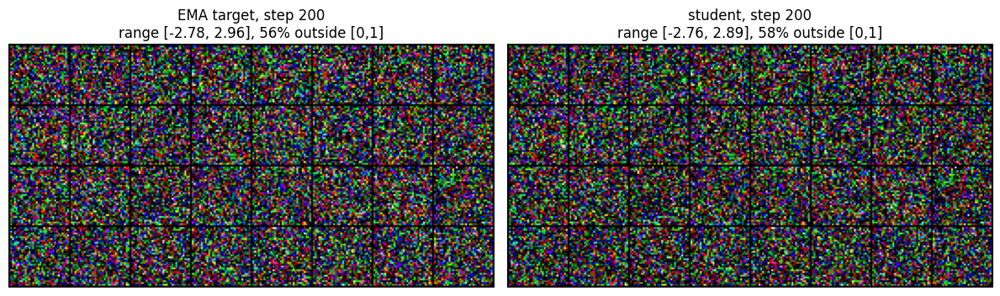

Saved baseline checkpoint at step 200 -> /content/gdrive/My Drive/Queens/CISC473/consistency_distillation/consistency_student_ckpt.pt
Loaded checkpoint saved 2026-11-24T20:17:48.691299+00:00 at step 200.
Save/load self-test passed.
Checkpoint: /content/gdrive/My Drive/Queens/CISC473/consistency_distillation/consistency_student_ckpt.pt
Saved: 2026-11-24T20:17:48.691299+00:00
Step: 200
Training time (run_training only): 0.0 min; peak GPU memory: 1.44 GB
  T: 1000
  schedule: cosine, s=0.008, betas clamped to [1e-5, 0.999], alpha_bar normalized by alpha_bar[0]
  alpha_checksum: 495.5774450877395
  teacher_checkpoint: /content/gdrive/My Drive/Queens/CISC473/ddpm_cifar_300.pt
  teacher_sha256: 93089b1c124f894c59dbef7d45a9b6c75f8727e2f009efdeb227d7957b9a2a71
  student_init: teacher weights
  sigma_data: 0.5
  loss: mse(student(x_high, t_high), ema(x_low, t_low))
  batch_size: 128
  learning_rate: 0.0001
  ema_decay: 0.999
  grad_clip_norm: 1.0
  seed: 0
  data: CIFAR-10 train, ToTensor() onl

In [42]:
show_samples(global_step)
if not optimizer.state:  # fresh optimizer: take a few real steps so its state exists for the self-test
    for _ in range(5):
        distillation_step(student, ema_student, optimizer, next(batches))
        global_step += 1
    show_samples(global_step)
save_checkpoint(CHECKPOINT_PATH)
print('Saved baseline checkpoint at step', global_step, '->', CHECKPOINT_PATH)

saved_step = global_step
saved_student = {k: v.detach().clone() for k, v in student.state_dict().items()}
saved_ema = {k: v.detach().clone() for k, v in ema_student.state_dict().items()}
saved_opt_state = [(p.detach().clone(), optimizer.state[p]['exp_avg'].clone()) for p in student.parameters()]
saved_seconds = training_state['train_seconds']
cpu_draw = torch.rand(3)
dev_draw = torch.rand(3, device=device)
py_draw = random.random()

for _ in range(3):
    distillation_step(student, ema_student, optimizer, next(batches))
global_step += 3
training_state['train_seconds'] += 1.0
assert any(not torch.equal(saved_student[k], v) for k, v in student.state_dict().items()), 'test steps changed nothing'

load_checkpoint(CHECKPOINT_PATH)
assert global_step == saved_step and training_state['train_seconds'] == saved_seconds
for k, v in student.state_dict().items():
    assert torch.equal(saved_student[k], v), k
for k, v in ema_student.state_dict().items():
    assert torch.equal(saved_ema[k], v), k
for p, (value, exp_avg) in zip(student.parameters(), saved_opt_state):
    assert torch.equal(p, value) and torch.equal(optimizer.state[p]['exp_avg'], exp_avg)
assert torch.equal(torch.rand(3), cpu_draw) and torch.equal(torch.rand(3, device=device), dev_draw)
assert random.random() == py_draw
assert student.training and not ema_student.training
assert not any(p.requires_grad for p in teacher.parameters()) and not teacher.training
assert all(not p.requires_grad for p in ema_student.parameters())
print('Save/load self-test passed.')
summarize_checkpoint(CHECKPOINT_PATH)

## Pilot run (about 2,000 steps)

Runs about 10 minutes at the pilot speed. It prints the loss every 50 steps, shows sample grids every 500 steps, and saves every 500 steps. Judge the grids, not just the loss: look for the one-step samples gaining structure and colour over time rather than staying noise or a flat colour. If they never improve, stop and tell me before a longer run.

step 250: loss=0.000136, grad norm=0.0023, 0.281 s/step, train time 0.2 min
step 300: loss=0.000139, grad norm=0.0018, 0.266 s/step, train time 0.5 min
step 350: loss=0.000134, grad norm=0.0018, 0.270 s/step, train time 0.7 min
step 400: loss=0.000114, grad norm=0.0023, 0.272 s/step, train time 0.9 min
step 450: loss=0.000123, grad norm=0.0011, 0.275 s/step, train time 1.1 min
step 500: loss=0.000132, grad norm=0.0026, 0.278 s/step, train time 1.4 min


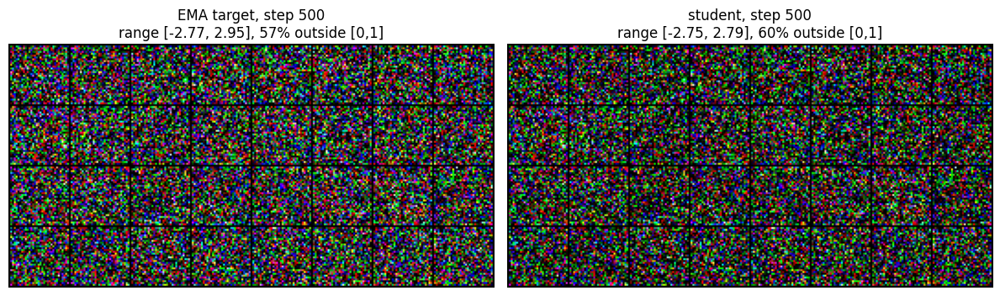

  saved checkpoint at step 500
step 550: loss=0.000099, grad norm=0.0062, 0.279 s/step, train time 1.6 min
step 600: loss=0.000102, grad norm=0.0014, 0.287 s/step, train time 1.8 min
step 650: loss=0.000098, grad norm=0.0022, 0.283 s/step, train time 2.1 min
step 700: loss=0.000085, grad norm=0.0022, 0.284 s/step, train time 2.3 min
step 750: loss=0.000092, grad norm=0.0019, 0.285 s/step, train time 2.5 min
step 800: loss=0.000102, grad norm=0.0013, 0.286 s/step, train time 2.8 min
step 850: loss=0.000099, grad norm=0.0027, 0.288 s/step, train time 3.0 min
step 900: loss=0.000103, grad norm=0.0017, 0.289 s/step, train time 3.3 min
step 950: loss=0.000107, grad norm=0.0020, 0.290 s/step, train time 3.5 min
step 1000: loss=0.000089, grad norm=0.0016, 0.294 s/step, train time 3.8 min


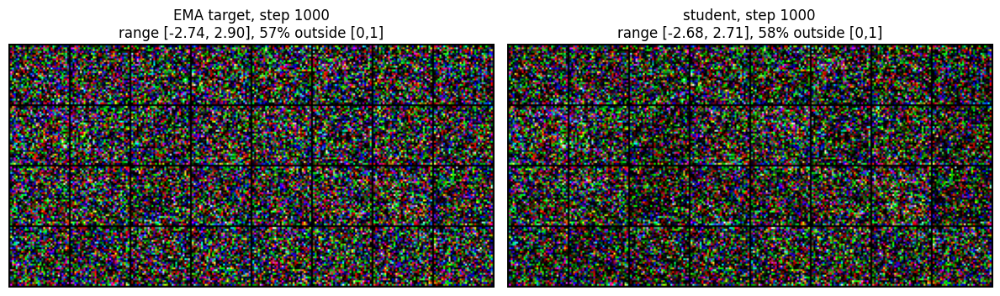

  saved checkpoint at step 1000
step 1050: loss=0.000095, grad norm=0.0012, 0.294 s/step, train time 4.0 min
step 1100: loss=0.000085, grad norm=0.0016, 0.292 s/step, train time 4.2 min
step 1150: loss=0.000070, grad norm=0.0026, 0.291 s/step, train time 4.5 min
step 1200: loss=0.000091, grad norm=0.0009, 0.291 s/step, train time 4.7 min
step 1250: loss=0.000066, grad norm=0.0015, 0.291 s/step, train time 5.0 min
step 1300: loss=0.000092, grad norm=0.0020, 0.290 s/step, train time 5.2 min
step 1350: loss=0.000100, grad norm=0.0024, 0.291 s/step, train time 5.5 min
step 1400: loss=0.000076, grad norm=0.0021, 0.295 s/step, train time 5.7 min
step 1450: loss=0.000086, grad norm=0.0046, 0.292 s/step, train time 5.9 min
step 1500: loss=0.000089, grad norm=0.0044, 0.292 s/step, train time 6.2 min


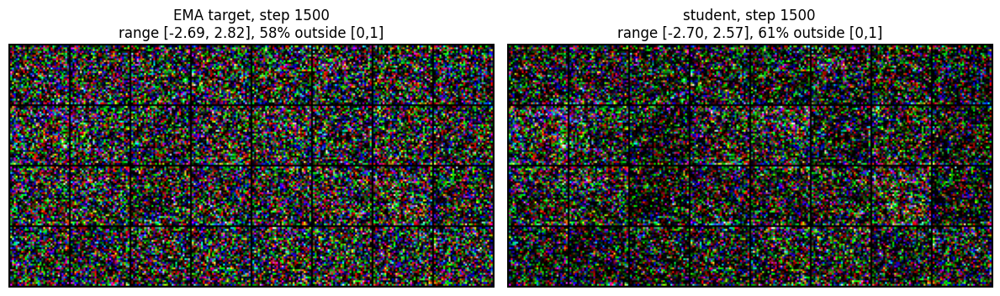

  saved checkpoint at step 1500
step 1550: loss=0.000081, grad norm=0.0028, 0.292 s/step, train time 6.4 min
step 1600: loss=0.000069, grad norm=0.0090, 0.294 s/step, train time 6.7 min
step 1650: loss=0.000106, grad norm=0.0036, 0.292 s/step, train time 6.9 min
step 1700: loss=0.000084, grad norm=0.0016, 0.292 s/step, train time 7.2 min
step 1750: loss=0.000096, grad norm=0.0030, 0.292 s/step, train time 7.4 min
step 1800: loss=0.000121, grad norm=0.0037, 0.295 s/step, train time 7.7 min
step 1850: loss=0.000132, grad norm=0.0063, 0.292 s/step, train time 7.9 min
step 1900: loss=0.000109, grad norm=0.0041, 0.292 s/step, train time 8.1 min
step 1950: loss=0.000090, grad norm=0.0014, 0.292 s/step, train time 8.4 min
step 2000: loss=0.000087, grad norm=0.0212, 0.292 s/step, train time 8.6 min


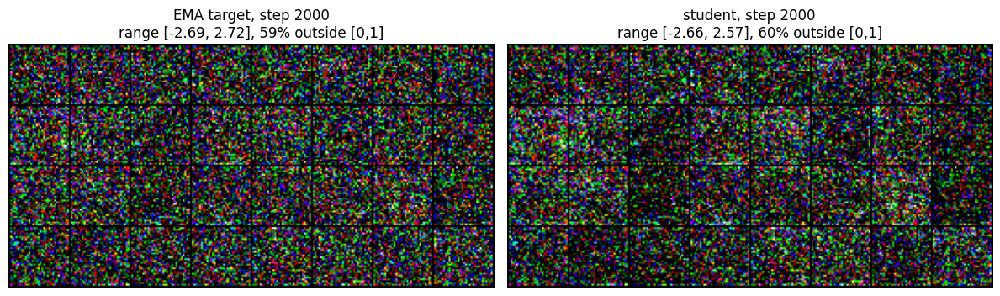

  saved checkpoint at step 2000
step 2050: loss=0.000089, grad norm=0.0016, 0.291 s/step, train time 8.9 min
step 2100: loss=0.000079, grad norm=0.0014, 0.292 s/step, train time 9.1 min
step 2150: loss=0.000077, grad norm=0.0022, 0.291 s/step, train time 9.4 min
step 2200: loss=0.000079, grad norm=0.0012, 0.295 s/step, train time 9.6 min
  saved checkpoint at step 2200


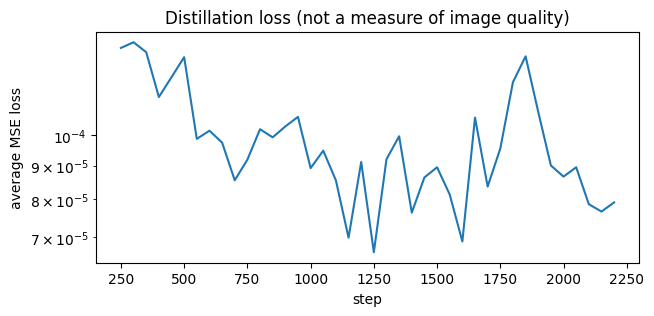

In [27]:
run_training(2000, log_every=50, sample_every=500, save_every=500)
plot_loss_log()

## Long run

Only run this after the pilot grids look reasonable. Edit `LONG_RUN_STEPS` as needed; 10,000 steps is roughly 50 minutes at the pilot speed. It saves the main checkpoint every 500 steps, shows a grid every 1,000 steps, and keeps a numbered snapshot every 5,000. You can run this cell repeatedly to keep training.

In [ ]:
LONG_RUN_STEPS = 10000
run_training(LONG_RUN_STEPS, log_every=100, sample_every=1000, save_every=500, snapshot_every=5000)
plot_loss_log()
summarize_checkpoint(CHECKPOINT_PATH)

## Resume after a disconnect

If the Colab runtime disconnects: reconnect, run the setup cells from the top through the **initialization cell** in Step 5 (it recreates the student, EMA target, and optimizer from the teacher), then the config, Step 6 definition cells, and this cell. Do **not** run the baseline, pilot, or long-run cells before this one. After it loads, call `run_training(...)` again to continue.

Loaded checkpoint saved 2026-11-24T20:17:48.691299+00:00 at step 200.
Checkpoint: /content/gdrive/My Drive/Queens/CISC473/consistency_distillation/consistency_student_ckpt.pt
Saved: 2026-11-24T20:17:48.691299+00:00
Step: 200
Training time (run_training only): 0.0 min; peak GPU memory: 1.44 GB
  T: 1000
  schedule: cosine, s=0.008, betas clamped to [1e-5, 0.999], alpha_bar normalized by alpha_bar[0]
  alpha_checksum: 495.5774450877395
  teacher_checkpoint: /content/gdrive/My Drive/Queens/CISC473/ddpm_cifar_300.pt
  teacher_sha256: 93089b1c124f894c59dbef7d45a9b6c75f8727e2f009efdeb227d7957b9a2a71
  student_init: teacher weights
  sigma_data: 0.5
  loss: mse(student(x_high, t_high), ema(x_low, t_low))
  batch_size: 128
  learning_rate: 0.0001
  ema_decay: 0.999
  grad_clip_norm: 1.0
  seed: 0
  data: CIFAR-10 train, ToTensor() only, [0,1]
  gpu: Tesla T4
  torch_version: 2.14.1+cu130
  grid: 101 levels, [0, 10, 20] ... [989, 998, 999]


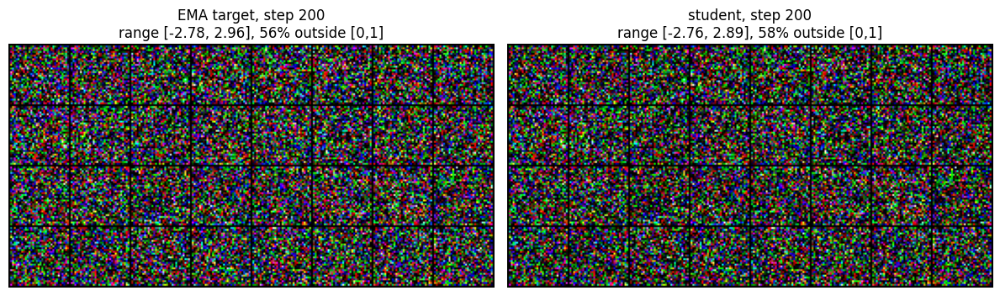

In [24]:
if not CHECKPOINT_PATH.is_file():
    raise FileNotFoundError(f'No checkpoint at {CHECKPOINT_PATH}.')
load_checkpoint(CHECKPOINT_PATH)
summarize_checkpoint(CHECKPOINT_PATH)
show_samples(global_step)

In [26]:
def readiness_check():
    problems = []

    def check(label, condition, detail=''):
        print(('OK   ' if condition else 'FAIL ') + label + (f'  [{detail}]' if detail else ''))
        if not condition:
            problems.append(label)

    needed = ['teacher', 'student', 'ema_student', 'optimizer', 'grid', 'batches', 'global_step',
              'distillation_step', 'run_training', 'save_checkpoint', 'load_checkpoint',
              'CHECKPOINT_PATH', 'TEACHER_PATH', 'training_state']
    missing = [n for n in needed if n not in globals()]
    check('all required names defined', not missing, f'missing: {missing}' if missing else '')
    if missing:
        print('\nRun the setup cells (or the resume path) first; stopping here.')
        return

    check('GPU in use', device.type == 'cuda', torch.cuda.get_device_name(0) if device.type == 'cuda' else 'CPU - change runtime to GPU')
    check('Drive mounted, teacher checkpoint present', TEACHER_PATH.is_file())
    check('consistency checkpoint present on Drive', CHECKPOINT_PATH.is_file())
    check('checkpoint path differs from teacher path', CHECKPOINT_PATH.resolve() != TEACHER_PATH.resolve())
    check('teacher frozen and in eval mode',
          not teacher.training and not any(p.requires_grad for p in teacher.parameters()))
    check('EMA target frozen and in eval mode',
          not ema_student.training and not any(p.requires_grad for p in ema_student.parameters()))
    check('student in train mode with gradients',
          student.training and all(p.requires_grad for p in student.parameters()))
    check('three distinct models', len({id(teacher), id(student), id(ema_student)}) == 3)
    check('grid is 101 levels ending 998, 999', grid.numel() == 101 and grid[-2:].tolist() == [998, 999])
    check('student and EMA on the same device as the schedule',
          next(student.parameters()).device == next(ema_student.parameters()).device == alpha_time_t.device)
    check('learning rate and EMA decay as expected',
          optimizer.param_groups[0]['lr'] == LEARNING_RATE and EMA_DECAY == 0.999,
          f"lr={optimizer.param_groups[0]['lr']}, ema={EMA_DECAY}")
    check('optimizer state exists (not a fresh optimizer)', len(optimizer.state) > 0)
    check('student U-Net differs from teacher (training has happened)',
          any(not torch.equal(p, q) for p, q in zip(student.unet.parameters(), teacher.parameters())))

    print(f'\nglobal_step = {global_step}, batch size = {BATCH_SIZE}, '
          f"logged train time = {training_state['train_seconds'] / 60:.1f} min")
    if CHECKPOINT_PATH.is_file():
        ckpt = torch.load(CHECKPOINT_PATH, map_location='cpu', weights_only=True)
        print(f"Checkpoint on Drive is at step {ckpt['global_step']} (saved {ckpt['saved_at']}).")
        check('in-memory step is not behind the saved checkpoint', global_step >= ckpt['global_step'],
              f"memory={global_step}, saved={ckpt['global_step']}")
        del ckpt

    print('\nREADY to train.' if not problems else f'\nNOT READY: {len(problems)} problem(s): {problems}')

    print("Training images:", len(cifar_train))
    print("First image shape:", cifar_train[0][0].shape)


readiness_check()

OK   all required names defined
OK   GPU in use  [Tesla T4]
OK   Drive mounted, teacher checkpoint present
OK   consistency checkpoint present on Drive
OK   checkpoint path differs from teacher path
OK   teacher frozen and in eval mode
OK   EMA target frozen and in eval mode
OK   student in train mode with gradients
OK   three distinct models
OK   grid is 101 levels ending 998, 999
OK   student and EMA on the same device as the schedule
OK   learning rate and EMA decay as expected  [lr=0.0001, ema=0.999]
OK   optimizer state exists (not a fresh optimizer)
OK   student U-Net differs from teacher (training has happened)

global_step = 200, batch size = 128, logged train time = 0.0 min
Checkpoint on Drive is at step 200 (saved 2026-11-24T20:17:48.691299+00:00).
OK   in-memory step is not behind the saved checkpoint  [memory=200, saved=200]

READY to train.
Training images: 50000
First image shape: torch.Size([3, 32, 32])


DEBUGGING

In [28]:
@torch.no_grad()
def diagnose_distillation():
    images = torch.stack([cifar_train[i][0] for i in range(4)]).to(device)
    generator = torch.Generator(device=device).manual_seed(42)
    noise = torch.randn(images.shape, generator=generator, device=device)

    positions = [1, 10, 50, 90, grid.numel() - 2, grid.numel() - 1]
    print("high -> low | trajectory change | consistency MSE | student vs image MSE")

    for pos in positions:
        high = grid[pos].item()
        low = grid[pos - 1].item()
        t_high = torch.full((len(images),), high, dtype=torch.long, device=device)
        t_low = torch.full((len(images),), low, dtype=torch.long, device=device)

        x_high, x_low = teacher_trajectory_pair(
            teacher, images, t_high, t_low, noise
        )
        prediction = student(x_high, t_high)
        target = ema_student(x_low, t_low)

        trajectory_change = (x_high - x_low).square().mean().sqrt().item()
        consistency_mse = (prediction - target).square().mean().item()
        image_mse = (prediction - images).square().mean().item()

        print(f"{high:3d} -> {low:3d} | {trajectory_change:.6f} | "
              f"{consistency_mse:.6f} | {image_mse:.6f}")

diagnose_distillation()

high -> low | trajectory change | consistency MSE | student vs image MSE
 10 ->   0 | 0.016962 | 0.000303 | 0.000733
101 ->  91 | 0.014778 | 0.000005 | 0.050755
505 -> 494 | 0.013156 | 0.000008 | 0.532082
908 -> 898 | 0.007473 | 0.000007 | 0.633669
998 -> 989 | 0.067717 | 0.000461 | 0.662793
999 -> 998 | 0.232218 | 0.005321 | 0.818945


In [29]:
@torch.no_grad()
def check_noise_preservation():
    images = torch.stack([cifar_train[i][0] for i in range(8)]).to(device)
    generator = torch.Generator(device=device).manual_seed(42)
    noise = torch.randn(images.shape, generator=generator, device=device)

    for level in [101, 505, 908, 999]:
        t = torch.full((len(images),), level, dtype=torch.long, device=device)
        x_noisy, _ = q_sample(images, t, noise)
        output = ema_student(x_noisy, t)

        a = (x_noisy - x_noisy.mean()).flatten()
        b = (output - output.mean()).flatten()
        correlation = torch.nn.functional.cosine_similarity(a, b, dim=0).item()

        print(
            f"t={level}: "
            f"output/input correlation={correlation:.3f}, "
            f"output vs input MSE={(output - x_noisy).square().mean().item():.4f}, "
            f"output vs image MSE={(output - images).square().mean().item():.4f}"
        )

check_noise_preservation()

t=101: output/input correlation=0.977, output vs input MSE=0.0075, output vs image MSE=0.0628
t=505: output/input correlation=0.994, output vs input MSE=0.0539, output vs image MSE=0.5336
t=908: output/input correlation=1.000, output vs input MSE=0.1329, output vs image MSE=0.6319
t=999: output/input correlation=0.992, output vs input MSE=0.1771, output vs image MSE=0.7123


In [30]:
import torch

x0 = torch.stack([cifar_train[i][0] for i in range(8)]).to(device)
gen = torch.Generator(device=device).manual_seed(123)
noise = torch.randn(x0.shape, generator=gen, device=device)

print("In-memory step:", global_step)
print(" high -> low | teacher noise MSE | pair change RMS | "
      "EMA local MSE | student/EMA MSE")

with torch.no_grad():
    for high in [10, 101, 505, 908, 989, 998, 999]:
        pos = torch.searchsorted(grid, torch.tensor(high, device=device)).item()
        assert pos > 0 and grid[pos].item() == high
        low = grid[pos - 1].item()

        th = torch.full((len(x0),), high, dtype=torch.long, device=device)
        tl = torch.full_like(th, low)
        xh, xl = teacher_trajectory_pair(teacher, x0, th, tl, noise)

        eps = teacher(xh, th)
        ema_high = ema_student(xh, th)
        ema_low = ema_student(xl, tl)
        student_high = student(xh, th)

        noise_mse = (eps - noise).square().mean().item()
        pair_rms = (xl - xh).square().mean().sqrt().item()
        local_mse = (ema_high - ema_low).square().mean().item()
        student_ema_mse = (student_high - ema_high).square().mean().item()
        print(f"{high:4} -> {low:3} | {noise_mse:17.6g} | "
              f"{pair_rms:15.6g} | {local_mse:13.6g} | "
              f"{student_ema_mse:15.6g}")

In-memory step: 2200
 high -> low | teacher noise MSE | pair change RMS | EMA local MSE | student/EMA MSE
  10 ->   0 |          0.346696 |       0.0167705 |   0.000314377 |     2.09347e-06
 101 ->  91 |         0.0932327 |       0.0147477 |    0.00071647 |      0.00067844
 505 -> 494 |         0.0166049 |         0.01308 |   2.75891e-05 |     2.48791e-05
 908 -> 898 |       0.000996809 |      0.00730029 |   3.09779e-06 |     9.25351e-06
 989 -> 979 |       6.19696e-05 |      0.00598381 |   1.07557e-05 |     1.38364e-05
 998 -> 989 |       5.70744e-05 |        0.064392 |   0.000535167 |      0.00010787
 999 -> 998 |       5.19949e-05 |        0.220463 |     0.0262557 |       0.0188846


In [31]:
x0 = torch.stack([cifar_train[i][0] for i in range(32)]).to(device)

print(" high -> low | seed | pair RMS | actual training MSE")
with torch.no_grad():
    for high in [998, 999]:
        pos = torch.searchsorted(grid, torch.tensor(high, device=device)).item()
        assert grid[pos].item() == high and pos > 0
        low = grid[pos - 1].item()
        th = torch.full((len(x0),), high, dtype=torch.long, device=device)
        tl = torch.full_like(th, low)

        for seed in [11, 22, 33]:
            gen = torch.Generator(device=device).manual_seed(seed)
            noise = torch.randn(x0.shape, generator=gen, device=device)
            xh, xl = teacher_trajectory_pair(teacher, x0, th, tl, noise)
            pair_rms = (xl - xh).square().mean().sqrt().item()
            loss = (student(xh, th) - ema_student(xl, tl)).square().mean().item()
            print(f"{high:4} -> {low:3} | {seed:4} | "
                  f"{pair_rms:8.5f} | {loss:.7f}")

 high -> low | seed | pair RMS | actual training MSE
 998 -> 989 |   11 |  0.06223 | 0.0003977
 998 -> 989 |   22 |  0.06446 | 0.0003950
 998 -> 989 |   33 |  0.06347 | 0.0003893
 999 -> 998 |   11 |  0.21331 | 0.0049725
 999 -> 998 |   22 |  0.22040 | 0.0048915
 999 -> 998 |   33 |  0.21750 | 0.0049369


Start 999: raw range [-3.19, 1.19]
Start 998: raw range [-0.12, 1.03]


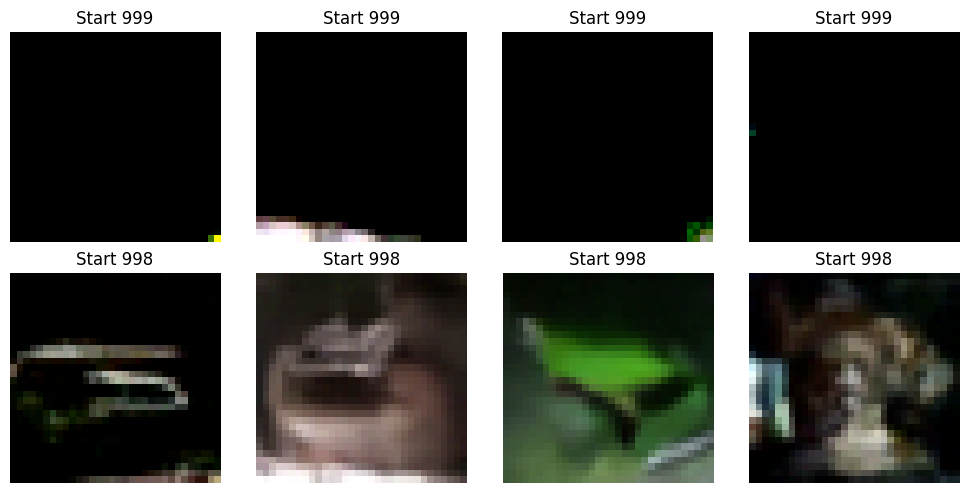

In [33]:
import matplotlib.pyplot as plt

@torch.no_grad()
def teacher_grid_sample(start_t, noise):
    assert not teacher.training
    start_pos = torch.searchsorted(grid, torch.tensor(start_t, device=device)).item()
    assert grid[start_pos].item() == start_t

    x = noise.clone()
    for pos in range(start_pos, 0, -1):
        high = grid[pos].item()
        low = grid[pos - 1].item()
        t = torch.full((len(x),), high, dtype=torch.long, device=device)

        a_high = alpha_time_t[high]
        a_low = alpha_time_t[low]
        eps = teacher(x, t)
        x0_pred = (x - torch.sqrt(1 - a_high) * eps) / torch.sqrt(a_high)
        x = torch.sqrt(a_low) * x0_pred + torch.sqrt(1 - a_low) * eps

        if not torch.isfinite(x).all():
            raise FloatingPointError(f"Non-finite trajectory at {high} -> {low}")
    return x

gen = torch.Generator(device=device).manual_seed(1234)
noise = torch.randn((4, 3, 32, 32), generator=gen, device=device)

outputs = {
    999: teacher_grid_sample(999, noise),
    998: teacher_grid_sample(998, noise),
}

fig, axes = plt.subplots(2, 4, figsize=(10, 5))
for row, (start, images) in enumerate(outputs.items()):
    print(f"Start {start}: raw range [{images.min().item():.2f}, "
          f"{images.max().item():.2f}]")
    for col, image in enumerate(images):
        axes[row, col].imshow(image.clamp(0, 1).cpu().permute(1, 2, 0))
        axes[row, col].set_title(f"Start {start}")
        axes[row, col].axis("off")
plt.tight_layout()
plt.show()

|Endpoint Experiment|

In [34]:
# EXPERIMENT: top of the grid is 998 instead of 999. All other settings are unchanged.
EXPERIMENT_TOP = 998

grid = torch.linspace(0, EXPERIMENT_TOP, steps=101, device=device).round().long()
assert grid[0].item() == 0 and grid[-1].item() == EXPERIMENT_TOP
assert torch.all(grid[1:] > grid[:-1]) and grid.numel() == 101
print('Grid levels:', grid.numel(), '| top levels:', grid[-4:].tolist())

# New checkpoint folder, so the original 999-endpoint run stays untouched
OLD_CHECKPOINT_DIR = CHECKPOINT_DIR
CHECKPOINT_DIR = TEACHER_PATH.parent / 'consistency_distillation_998'
CHECKPOINT_PATH = CHECKPOINT_DIR / 'consistency_student_ckpt.pt'
SAMPLE_DIR = CHECKPOINT_DIR / 'samples'
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
SAMPLE_DIR.mkdir(parents=True, exist_ok=True)
assert CHECKPOINT_DIR.resolve() != OLD_CHECKPOINT_DIR.resolve()
assert CHECKPOINT_PATH.resolve() != TEACHER_PATH.resolve()
print('New checkpoint folder:', CHECKPOINT_DIR)

SAMPLE_T = EXPERIMENT_TOP  # one-step samples now start at 998


@torch.no_grad()
def one_step_samples(model, num=32):
    was_training = model.training
    model.eval()
    generator = torch.Generator(device=device).manual_seed(SAMPLE_SEED)
    noise = torch.randn((num, 3, 32, 32), generator=generator, device=device)
    t = torch.full((num,), SAMPLE_T, dtype=torch.long, device=device)
    out = model(noise, t)
    model.train(was_training)
    if not torch.isfinite(out).all():
        raise FloatingPointError('One-step samples contain non-finite values.')
    return out


# Fresh start: same initialization and settings as the original pilot
torch.manual_seed(SEED)
student.unet.load_state_dict(teacher.state_dict())
ema_student.load_state_dict(student.state_dict())
student.train()
student.requires_grad_(True)
ema_student.eval()
ema_student.requires_grad_(False)
optimizer = torch.optim.Adam(student.parameters(), lr=LEARNING_RATE)
global_step = 0
training_state['train_seconds'] = 0.0
training_state['loss_log'] = []
training_state['peak_gpu_memory_gb'] = 0.0

# Sanity check: top pair size and training loss at step 0
x0 = next(batches)
top = torch.full((len(x0),), EXPERIMENT_TOP, dtype=torch.long, device=device)
low = torch.full_like(top, grid[-2].item())
with torch.no_grad():
    xh, xl = teacher_trajectory_pair(teacher, x0, top, low)
    rms = (xl - xh).square().mean().sqrt().item()
    loss0 = (student(xh, top) - ema_student(xl, low)).square().mean().item()
print(f'Top pair {EXPERIMENT_TOP} -> {grid[-2].item()}: pair RMS={rms:.4f}, step-0 MSE={loss0:.6f}')
print('Reference: 999 -> 998 had pair RMS ~0.22 and 998 -> 989 had ~0.063.')
assert rms < 0.1, 'Top pair is still unexpectedly large; stop and report this.'

Grid levels: 101 | top levels: [968, 978, 988, 998]
New checkpoint folder: /content/gdrive/My Drive/Queens/CISC473/consistency_distillation_998
Top pair 998 -> 988: pair RMS=0.0709, step-0 MSE=0.002088
Reference: 999 -> 998 had pair RMS ~0.22 and 998 -> 989 had ~0.063.


step 50: loss=0.000053, grad norm=0.0009, 0.264 s/step, train time 0.2 min
step 100: loss=0.000031, grad norm=0.0008, 0.266 s/step, train time 0.4 min
step 150: loss=0.000027, grad norm=0.0027, 0.270 s/step, train time 0.7 min
step 200: loss=0.000020, grad norm=0.0005, 0.272 s/step, train time 0.9 min
step 250: loss=0.000021, grad norm=0.0006, 0.275 s/step, train time 1.1 min
step 300: loss=0.000018, grad norm=0.0007, 0.277 s/step, train time 1.4 min
step 350: loss=0.000020, grad norm=0.0006, 0.282 s/step, train time 1.6 min
step 400: loss=0.000017, grad norm=0.0009, 0.281 s/step, train time 1.8 min
step 450: loss=0.000019, grad norm=0.0006, 0.282 s/step, train time 2.1 min
step 500: loss=0.000018, grad norm=0.0006, 0.283 s/step, train time 2.3 min


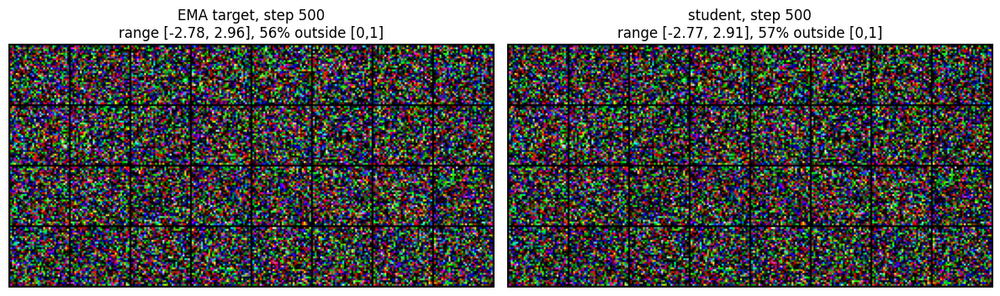

  saved checkpoint at step 500
step 550: loss=0.000018, grad norm=0.0006, 0.285 s/step, train time 2.5 min
step 600: loss=0.000017, grad norm=0.0007, 0.287 s/step, train time 2.8 min
step 650: loss=0.000014, grad norm=0.0008, 0.288 s/step, train time 3.0 min
step 700: loss=0.000014, grad norm=0.0006, 0.290 s/step, train time 3.3 min
step 750: loss=0.000015, grad norm=0.0006, 0.293 s/step, train time 3.5 min
step 800: loss=0.000018, grad norm=0.0006, 0.290 s/step, train time 3.7 min
step 850: loss=0.000020, grad norm=0.0007, 0.291 s/step, train time 4.0 min
step 900: loss=0.000015, grad norm=0.0008, 0.291 s/step, train time 4.2 min
step 950: loss=0.000018, grad norm=0.0009, 0.291 s/step, train time 4.5 min
step 1000: loss=0.000017, grad norm=0.0006, 0.292 s/step, train time 4.7 min


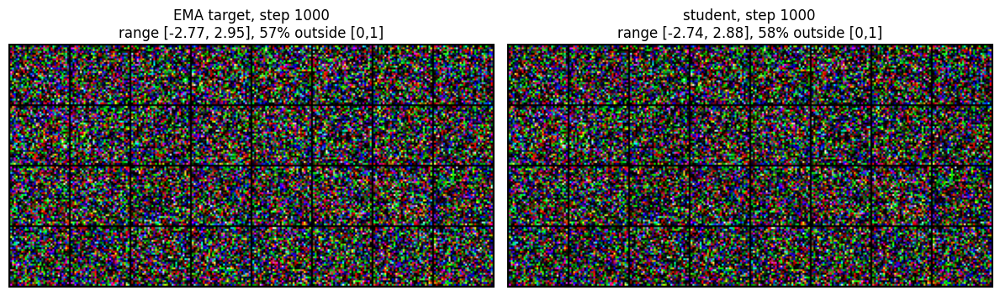

  saved checkpoint at step 1000
  saved snapshot consistency_student_step0001000.pt
step 1050: loss=0.000016, grad norm=0.0009, 0.307 s/step, train time 5.0 min
step 1100: loss=0.000015, grad norm=0.0005, 0.292 s/step, train time 5.2 min
step 1150: loss=0.000013, grad norm=0.0004, 0.297 s/step, train time 5.4 min
step 1200: loss=0.000018, grad norm=0.0006, 0.292 s/step, train time 5.7 min
step 1250: loss=0.000016, grad norm=0.0008, 0.292 s/step, train time 5.9 min
step 1300: loss=0.000017, grad norm=0.0008, 0.292 s/step, train time 6.2 min
step 1350: loss=0.000016, grad norm=0.0010, 0.292 s/step, train time 6.4 min
step 1400: loss=0.000017, grad norm=0.0011, 0.292 s/step, train time 6.7 min
step 1450: loss=0.000016, grad norm=0.0010, 0.292 s/step, train time 6.9 min
step 1500: loss=0.000016, grad norm=0.0008, 0.292 s/step, train time 7.1 min


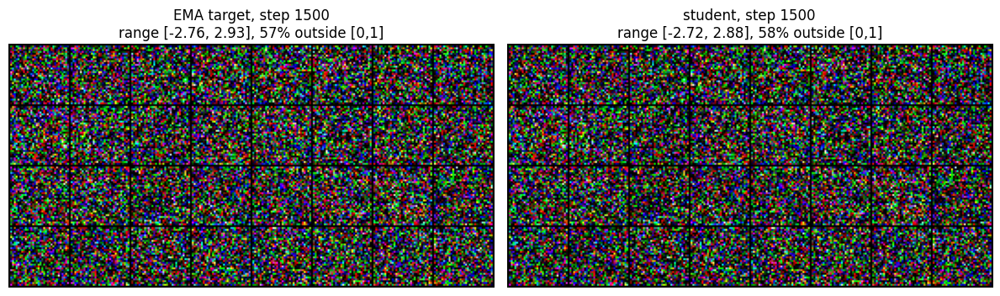

  saved checkpoint at step 1500
step 1550: loss=0.000017, grad norm=0.0008, 0.295 s/step, train time 7.4 min
step 1600: loss=0.000018, grad norm=0.0012, 0.292 s/step, train time 7.6 min
step 1650: loss=0.000016, grad norm=0.0008, 0.292 s/step, train time 7.9 min
step 1700: loss=0.000017, grad norm=0.0007, 0.292 s/step, train time 8.1 min
step 1750: loss=0.000017, grad norm=0.0004, 0.292 s/step, train time 8.4 min
step 1800: loss=0.000017, grad norm=0.0008, 0.292 s/step, train time 8.6 min
step 1850: loss=0.000016, grad norm=0.0004, 0.292 s/step, train time 8.9 min
step 1900: loss=0.000017, grad norm=0.0006, 0.294 s/step, train time 9.1 min
step 1950: loss=0.000015, grad norm=0.0009, 0.292 s/step, train time 9.3 min
step 2000: loss=0.000017, grad norm=0.0010, 0.291 s/step, train time 9.6 min


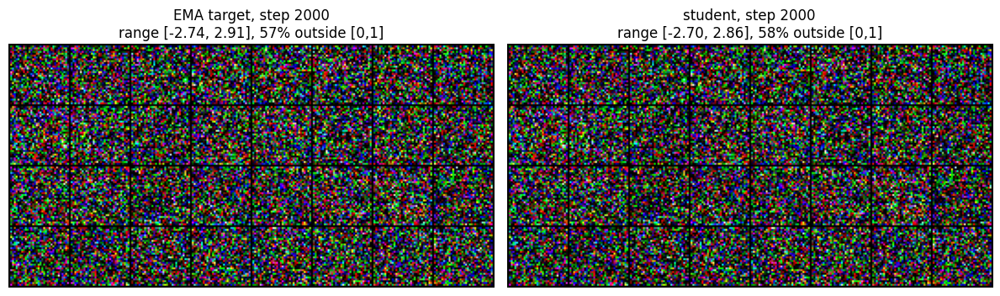

  saved checkpoint at step 2000
  saved snapshot consistency_student_step0002000.pt


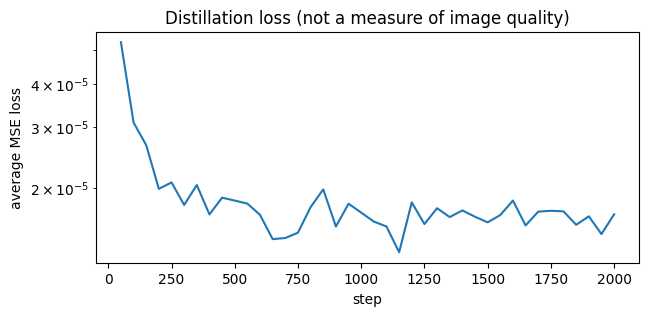

In [35]:
run_training(2000, log_every=50, sample_every=500, save_every=500, snapshot_every=1000)
plot_loss_log()

In [ ]:
with torch.no_grad():
    gen = torch.Generator(device=device).manual_seed(SAMPLE_SEED)
    noise = torch.randn((64, 3, 32, 32), generator=gen, device=device)
    t = torch.full((64,), EXPERIMENT_TOP, dtype=torch.long, device=device)
    out = ema_student(noise, t)
    corr = torch.corrcoef(torch.stack([noise.flatten(), out.flatten()]))[0, 1].item()
    outside = ((out < 0) | (out > 1)).float().mean().item()
print(f'step {global_step}: input/output correlation={corr:.3f}, '
      f'outside [0,1]={outside:.0%}, range [{out.min():.2f}, {out.max():.2f}]')

In [36]:
with torch.no_grad():
    gen = torch.Generator(device=device).manual_seed(SAMPLE_SEED)
    for level in [998, 505, 101]:
        x0 = next(batches)[:64]
        t = torch.full((64,), level, dtype=torch.long, device=device)
        xt, _ = q_sample(x0, t, torch.randn(x0.shape, generator=gen, device=device))
        out = ema_student(xt, t)
        b = (out * xt).sum() / xt.square().sum()          # best scale: out ≈ b * xt
        resid = (out - b * xt).square().mean().sqrt().item()
        err = (out - x0).square().mean().sqrt().item()
        print(f't={level}: out ≈ {b:.3f}*input, leftover RMS={resid:.4f}, '
              f'RMS error vs true clean image={err:.4f}')

t=998: out ≈ 0.638*input, leftover RMS=0.0267, RMS error vs true clean image=0.8463
t=505: out ≈ 0.777*input, leftover RMS=0.1720, RMS error vs true clean image=0.7490
t=101: out ≈ 0.996*input, leftover RMS=0.0914, RMS error vs true clean image=0.2565


In [37]:
WARMUP_STEPS = 3000
WARMUP_LR = 2e-4
WARMUP_DIR = TEACHER_PATH.parent / 'consistency_distillation_998_warmup'
WARMUP_DIR.mkdir(parents=True, exist_ok=True)
assert WARMUP_DIR.resolve() != OLD_CHECKPOINT_DIR.resolve() and WARMUP_DIR.resolve() != CHECKPOINT_DIR.resolve()

torch.manual_seed(SEED)
student.unet.load_state_dict(teacher.state_dict())   # same starting weights as before
student.train(); student.requires_grad_(True)
warm_opt = torch.optim.Adam(student.parameters(), lr=WARMUP_LR)


def coeffs(t):
    sigma = student.noise_std[t].view(-1, 1, 1, 1)
    offset = sigma - student.noise_std[0]
    sd = student.sigma_data
    return sd**2 / (offset**2 + sd**2), sd * offset / torch.sqrt(sigma**2 + sd**2)


running = []
for step in range(1, WARMUP_STEPS + 1):
    x0 = next(batches)
    t = grid[torch.randint(1, grid.numel(), (x0.shape[0],), device=device)]
    xt, _ = q_sample(x0, t)
    c_skip, c_out = coeffs(t)
    target = (x0 - c_skip * xt) / c_out      # what the U-Net must output so f(xt, t) = x0
    loss = torch.nn.functional.mse_loss(student.unet(xt, t), target)
    warm_opt.zero_grad(set_to_none=True)
    loss.backward()
    torch.nn.utils.clip_grad_norm_(student.parameters(), GRAD_CLIP_NORM)
    warm_opt.step()
    running.append(loss.item())
    if step % 250 == 0:
        print(f'warm-up step {step}: loss={sum(running) / len(running):.4f}')
        running = []

# Same check as before, plus the noisy input's own error for comparison
student.eval()
with torch.no_grad():
    for level in [998, 505, 101]:
        x0 = next(batches)[:64]
        t = torch.full((64,), level, dtype=torch.long, device=device)
        xt, _ = q_sample(x0, t)
        err_in = (xt - x0).square().mean().sqrt().item()
        err_out = (student(xt, t) - x0).square().mean().sqrt().item()
        print(f't={level}: RMS error of noisy input={err_in:.4f}, of student output={err_out:.4f}')
student.train()
torch.save(student.state_dict(), WARMUP_DIR / 'warmup_student.pt')

warm-up step 250: loss=0.6704
warm-up step 500: loss=0.1717
warm-up step 750: loss=0.1590
warm-up step 1000: loss=0.1523
warm-up step 1250: loss=0.1481
warm-up step 1500: loss=0.1462
warm-up step 1750: loss=0.1452
warm-up step 2000: loss=0.1438
warm-up step 2250: loss=0.1425
warm-up step 2500: loss=0.1417
warm-up step 2750: loss=0.1417
warm-up step 3000: loss=0.1402
t=998: RMS error of noisy input=1.1288, of student output=0.2574
t=505: RMS error of noisy input=0.7380, of student output=0.1201
t=101: RMS error of noisy input=0.1707, of student output=0.0519


In [ ]:
CHECKPOINT_DIR = WARMUP_DIR
CHECKPOINT_PATH = CHECKPOINT_DIR / 'consistency_student_ckpt.pt'
SAMPLE_DIR = CHECKPOINT_DIR / 'samples'
SAMPLE_DIR.mkdir(parents=True, exist_ok=True)

ema_student.load_state_dict(student.state_dict())
student.train(); student.requires_grad_(True)
ema_student.eval(); ema_student.requires_grad_(False)
optimizer = torch.optim.Adam(student.parameters(), lr=LEARNING_RATE)   # fresh distillation optimizer
global_step = 0
training_state['train_seconds'] = 0.0
training_state['loss_log'] = []
training_state['peak_gpu_memory_gb'] = 0.0

show_samples(0)   # blurry mean-like images expected here
run_training(2000, log_every=50, sample_every=500, save_every=500, snapshot_every=1000)
plot_loss_log()

998 pilot checkpoint step: 2000
998 pilot EMA: correlation=1.000, outside [0,1]=57.0%, range=[-2.74, 2.91]
Warm-up student: correlation=-0.021, outside [0,1]=0.0%, range=[0.31, 0.63]


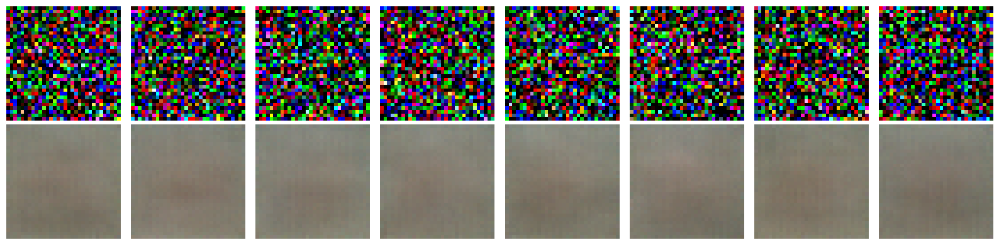

In [38]:
# Compare the saved 998 pilot and the completed warm-up.
pilot_path = TEACHER_PATH.parent / 'consistency_distillation_998' / 'consistency_student_ckpt.pt'
warmup_path = TEACHER_PATH.parent / 'consistency_distillation_998_warmup' / 'warmup_student.pt'

if not pilot_path.is_file() or not warmup_path.is_file():
    raise FileNotFoundError('A checkpoint is missing. Check the paths above.')

pilot_ckpt = torch.load(pilot_path, map_location='cpu', weights_only=True)
print('998 pilot checkpoint step:', pilot_ckpt['global_step'])

pilot_model = copy.deepcopy(student).to(device)
pilot_model.load_state_dict(pilot_ckpt['ema_student'])
pilot_model.eval()

warmup_model = copy.deepcopy(student).to(device)
warmup_model.load_state_dict(torch.load(warmup_path, map_location=device, weights_only=True))
warmup_model.eval()

gen = torch.Generator(device=device).manual_seed(1234)
noise = torch.randn((32, 3, 32, 32), generator=gen, device=device)
t = torch.full((32,), 998, dtype=torch.long, device=device)

fig, axes = plt.subplots(2, 8, figsize=(16, 4))
with torch.no_grad():
    for row, (name, model) in enumerate([
        ('998 pilot EMA', pilot_model),
        ('Warm-up student', warmup_model),
    ]):
        out = model(noise, t)
        corr = torch.corrcoef(torch.stack([noise.flatten(), out.flatten()]))[0, 1].item()
        outside = ((out < 0) | (out > 1)).float().mean().item()
        print(f'{name}: correlation={corr:.3f}, outside [0,1]={outside:.1%}, '
              f'range=[{out.min().item():.2f}, {out.max().item():.2f}]')
        for col in range(8):
            axes[row, col].imshow(out[col].clamp(0, 1).cpu().permute(1, 2, 0))
            axes[row, col].axis('off')
        axes[row, 0].set_ylabel(name)

plt.tight_layout()
plt.show()

del pilot_model, warmup_model, pilot_ckpt

Saving this experiment to: /content/gdrive/My Drive/Queens/CISC473/consistency_distillation_998_warmup_distill_v1


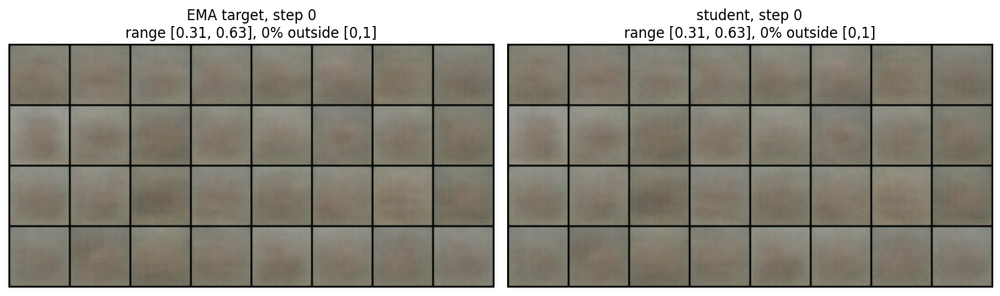

step 50: loss=0.000153, grad norm=0.0083, 0.283 s/step, train time 0.2 min
step 100: loss=0.000018, grad norm=0.0041, 0.284 s/step, train time 0.5 min
step 150: loss=0.000014, grad norm=0.0014, 0.288 s/step, train time 0.7 min
step 200: loss=0.000013, grad norm=0.0012, 0.292 s/step, train time 1.0 min
step 250: loss=0.000012, grad norm=0.0070, 0.295 s/step, train time 1.2 min
step 300: loss=0.000010, grad norm=0.0022, 0.293 s/step, train time 1.4 min
step 350: loss=0.000011, grad norm=0.0083, 0.290 s/step, train time 1.7 min
step 400: loss=0.000012, grad norm=0.0098, 0.289 s/step, train time 1.9 min
step 450: loss=0.000012, grad norm=0.0016, 0.295 s/step, train time 2.2 min
step 500: loss=0.000010, grad norm=0.0010, 0.292 s/step, train time 2.4 min


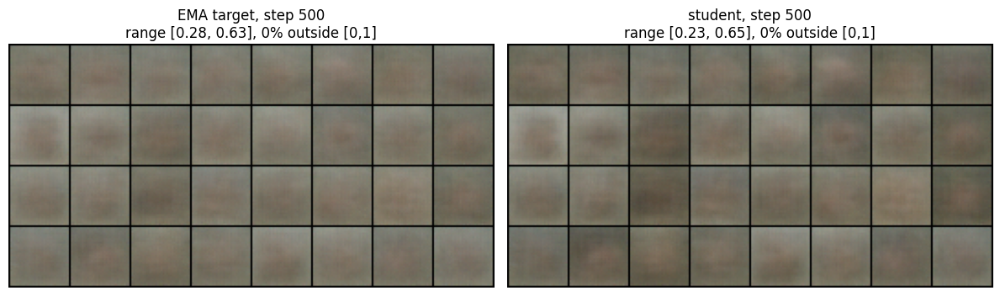

  saved checkpoint at step 500
  saved snapshot consistency_student_step0000500.pt


In [39]:
# Short experiment: distill from the saved warm-up.
pilot_path = TEACHER_PATH.parent / 'consistency_distillation_998' / 'consistency_student_ckpt.pt'
warmup_path = TEACHER_PATH.parent / 'consistency_distillation_998_warmup' / 'warmup_student.pt'
new_dir = TEACHER_PATH.parent / 'consistency_distillation_998_warmup_distill_v1'

if not pilot_path.is_file() or not warmup_path.is_file():
    raise FileNotFoundError('Pilot or warm-up checkpoint is missing.')
if new_dir.exists():
    raise FileExistsError(f'{new_dir} already exists; choose a new folder name.')

pilot_config = torch.load(pilot_path, map_location='cpu', weights_only=True)['config']
if grid.tolist() != pilot_config['grid'] or grid[-1].item() != 998:
    raise ValueError('Current grid does not match the saved 998 pilot.')
if teacher_sha256() != pilot_config['teacher_sha256']:
    raise ValueError('Current teacher does not match the saved 998 pilot.')
if SAMPLE_T != 998:
    raise ValueError('One-step sampling must use timestep 998.')

# Record exactly which warm-up checkpoint was used.
digest = hashlib.sha256()
with open(warmup_path, 'rb') as f:
    for block in iter(lambda: f.read(1 << 20), b''):
        digest.update(block)
warmup_sha = digest.hexdigest()

warmup_state = torch.load(warmup_path, map_location=device, weights_only=True)
torch.testing.assert_close(warmup_state['noise_std'], student.noise_std)

new_dir.mkdir()
CHECKPOINT_DIR = new_dir
CHECKPOINT_PATH = new_dir / 'consistency_student_ckpt.pt'
SAMPLE_DIR = new_dir / 'samples'
SAMPLE_DIR.mkdir()

student.load_state_dict(warmup_state)
ema_student.load_state_dict(student.state_dict())
student.train()
student.requires_grad_(True)
ema_student.eval()
ema_student.requires_grad_(False)
optimizer = torch.optim.Adam(student.parameters(), lr=LEARNING_RATE)
global_step = 0
training_state = {'train_seconds': 0.0, 'loss_log': [], 'peak_gpu_memory_gb': 0.0}

# Correct the checkpoint metadata for this experiment.
def make_config(_base=make_config):
    config = _base()
    config['student_init'] = 'teacher weights plus supervised denoising warm-up'
    config['warmup_checkpoint'] = str(warmup_path)
    config['warmup_sha256'] = warmup_sha
    config['warmup_description'] = (
        '3000 steps, Adam lr 2e-4, MSE on unet output against '
        '(x0 - c_skip * xt) / c_out'
    )
    return config

print('Saving this experiment to:', new_dir)
show_samples(0)
run_training(500, log_every=50, sample_every=500, save_every=500, snapshot_every=500)

t=998: MSE vs teacher final=0.13471, variation across images=0.0147
t=898: MSE vs teacher final=0.02928, variation across images=0.0626
t=499: MSE vs teacher final=0.00434, variation across images=0.1186
t=100: MSE vs teacher final=0.00045, variation across images=0.1379
t=0: MSE vs teacher final=0.00000, variation across images=0.1385


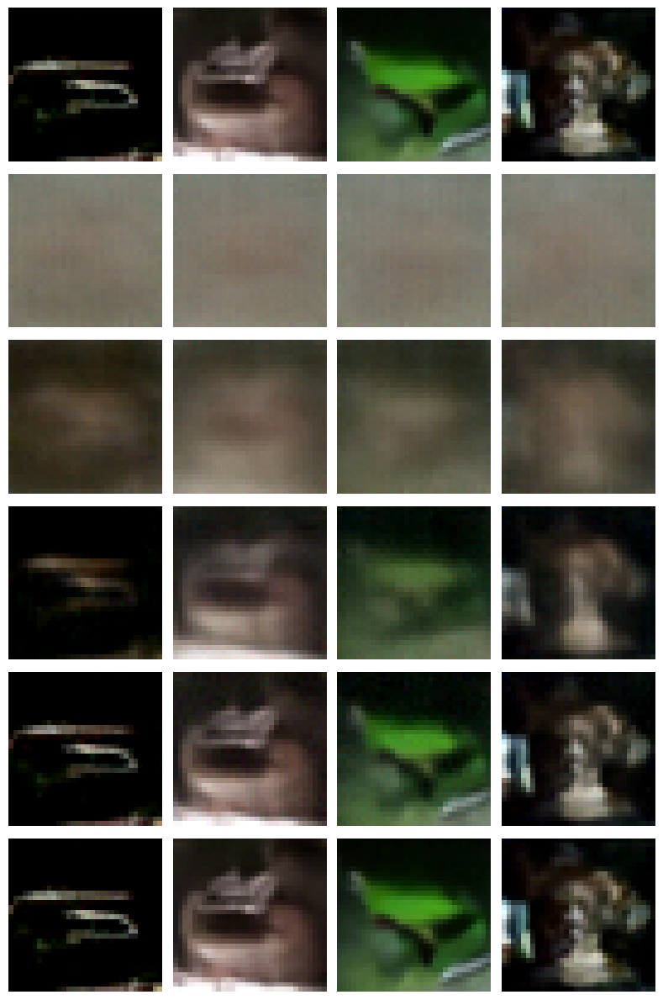

In [40]:
@torch.no_grad()
def compare_trajectory():
    if teacher.training or ema_student.training:
        raise ValueError('Teacher and EMA must be in evaluation mode.')
    if grid[-1].item() != 998:
        raise ValueError('Expected the 998 experiment grid.')

    levels = grid.tolist()
    selected = [
        levels[-1],
        min(levels, key=lambda x: abs(x - 900)),
        min(levels, key=lambda x: abs(x - 500)),
        min(levels, key=lambda x: abs(x - 100)),
        levels[0],
    ]

    gen = torch.Generator(device=device).manual_seed(1234)
    x = torch.randn((4, 3, 32, 32), generator=gen, device=device)
    points = {}

    for pos in range(len(levels) - 1, 0, -1):
        high, low = levels[pos], levels[pos - 1]
        if high in selected:
            points[high] = x.clone()

        t = torch.full((len(x),), high, dtype=torch.long, device=device)
        eps = teacher(x, t)
        a_high, a_low = alpha_time_t[high], alpha_time_t[low]
        clean_estimate = (x - torch.sqrt(1 - a_high) * eps) / torch.sqrt(a_high)
        x = torch.sqrt(a_low) * clean_estimate + torch.sqrt(1 - a_low) * eps

        if not torch.isfinite(x).all():
            raise FloatingPointError(f'Non-finite teacher output at {high} -> {low}')

    points[levels[0]] = x
    reference = x
    rows = [('Teacher final', reference)]

    for level in selected:
        t = torch.full((len(x),), level, dtype=torch.long, device=device)
        out = ema_student(points[level], t)
        mse = (out - reference).square().mean().item()
        diversity = out.std(dim=0, unbiased=False).mean().item()
        print(f't={level}: MSE vs teacher final={mse:.5f}, '
              f'variation across images={diversity:.4f}')
        rows.append((f'EMA at {level}', out))

    fig, axes = plt.subplots(len(rows), 4, figsize=(8, 2 * len(rows)))
    for row, (label, images) in enumerate(rows):
        for col, image in enumerate(images):
            axes[row, col].imshow(image.clamp(0, 1).cpu().permute(1, 2, 0))
            axes[row, col].axis('off')
        axes[row, 0].set_ylabel(label)
    plt.tight_layout()
    plt.show()

compare_trajectory()

Before: train MSE=0.17869, held-out MSE=0.19674, held-out variation=0.0364
step 50: training loss=0.00729
step 100: training loss=0.00276
step 150: training loss=0.00145
step 200: training loss=0.00089
After: train MSE=0.00088, held-out MSE=0.01544, held-out variation=0.2292


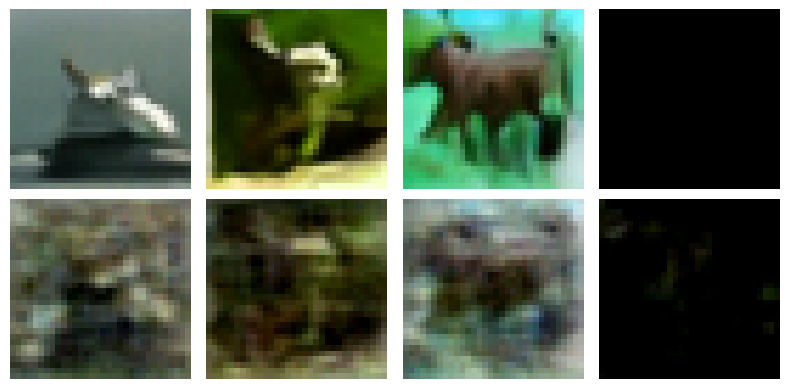

In [41]:
@torch.no_grad()
def make_teacher_pairs(n=16):
    gen = torch.Generator(device=device).manual_seed(31415)
    noise = torch.randn((n, 3, 32, 32), generator=gen, device=device)
    x = noise.clone()
    levels = grid.tolist()

    for pos in range(len(levels) - 1, 0, -1):
        high, low = levels[pos], levels[pos - 1]
        t = torch.full((n,), high, dtype=torch.long, device=device)
        eps = teacher(x, t)
        ah, al = alpha_time_t[high], alpha_time_t[low]
        clean = (x - torch.sqrt(1 - ah) * eps) / torch.sqrt(ah)
        x = torch.sqrt(al) * clean + torch.sqrt(1 - al) * eps
        if not torch.isfinite(x).all():
            raise FloatingPointError(f'Non-finite teacher output at {high} -> {low}')

    return noise, x


def trajectory_pair_test():
    assert grid[-1].item() == 998
    noise, targets = make_teacher_pairs()
    t = torch.full((16,), 998, dtype=torch.long, device=device)

    # A separate copy: the real student and EMA are not modified.
    probe = copy.deepcopy(ema_student)
    probe.requires_grad_(True)
    opt = torch.optim.Adam(probe.parameters(), lr=1e-4)

    def report(label):
        probe.eval()
        with torch.no_grad():
            out = probe(noise, t)
            train_mse = (out[:8] - targets[:8]).square().mean().item()
            test_mse = (out[8:] - targets[8:]).square().mean().item()
            variation = out[8:].std(dim=0, unbiased=False).mean().item()
        print(f'{label}: train MSE={train_mse:.5f}, '
              f'held-out MSE={test_mse:.5f}, held-out variation={variation:.4f}')
        return out

    report('Before')
    probe.train()
    for step in range(1, 201):
        prediction = probe(noise[:8], t[:8])
        loss = torch.nn.functional.mse_loss(prediction, targets[:8])
        if not torch.isfinite(loss):
            raise FloatingPointError('Non-finite loss')
        opt.zero_grad(set_to_none=True)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(probe.parameters(), 1.0, error_if_nonfinite=True)
        opt.step()
        if step % 50 == 0:
            print(f'step {step}: training loss={loss.item():.5f}')

    out = report('After')
    fig, axes = plt.subplots(2, 4, figsize=(8, 4))
    for col in range(4):
        for row, images in enumerate([targets[8:], out[8:]]):
            axes[row, col].imshow(images[col].clamp(0, 1).cpu().permute(1, 2, 0))
            axes[row, col].axis('off')
    axes[0, 0].set_ylabel('Teacher')
    axes[1, 0].set_ylabel('Probe')
    plt.tight_layout()
    plt.show()


trajectory_pair_test()

In [42]:
noise, teacher_outputs = make_teacher_pairs(n=16)

below = (teacher_outputs < 0).float().mean(dim=(1, 2, 3))
above = (teacher_outputs > 1).float().mean(dim=(1, 2, 3))

for i in range(16):
    img = teacher_outputs[i]
    print(f'{i:2}: range [{img.min().item():.2f}, {img.max().item():.2f}], '
          f'below 0: {below[i].item():.1%}, above 1: {above[i].item():.1%}')

 0: range [-0.05, 0.90], below 0: 20.8%, above 1: 0.0%
 1: range [-0.14, 0.58], below 0: 81.3%, above 1: 0.0%
 2: range [0.07, 1.03], below 0: 0.0%, above 1: 0.1%
 3: range [-0.10, 1.05], below 0: 22.8%, above 1: 1.9%
 4: range [-0.26, 0.39], below 0: 99.1%, above 1: 0.0%
 5: range [-0.11, 0.72], below 0: 74.1%, above 1: 0.0%
 6: range [0.02, 1.19], below 0: 0.0%, above 1: 41.5%
 7: range [-0.12, 0.64], below 0: 93.6%, above 1: 0.0%
 8: range [0.02, 1.03], below 0: 0.0%, above 1: 0.1%
 9: range [-0.09, 1.04], below 0: 20.2%, above 1: 0.5%
10: range [-0.03, 1.02], below 0: 0.4%, above 1: 0.2%
11: range [-0.28, -0.12], below 0: 100.0%, above 1: 0.0%
12: range [-0.21, 0.56], below 0: 99.1%, above 1: 0.0%
13: range [-0.13, -0.05], below 0: 100.0%, above 1: 0.0%
14: range [-0.04, 1.00], below 0: 3.9%, above 1: 0.0%
15: range [-0.24, -0.10], below 0: 100.0%, above 1: 0.0%


Start 998: 6/16 images with over 90% of pixels below zero
  sample 4: below zero=99.1%, range=[-0.26, 0.39]
  sample 11: below zero=100.0%, range=[-0.28, -0.12]
  sample 13: below zero=100.0%, range=[-0.13, -0.05]
  sample 15: below zero=100.0%, range=[-0.24, -0.10]
Start 988: 0/16 images with over 90% of pixels below zero
  sample 4: below zero=22.4%, range=[-0.03, 0.79]
  sample 11: below zero=1.1%, range=[-0.01, 0.70]
  sample 13: below zero=0.0%, range=[0.02, 0.81]
  sample 15: below zero=1.4%, range=[-0.03, 0.84]


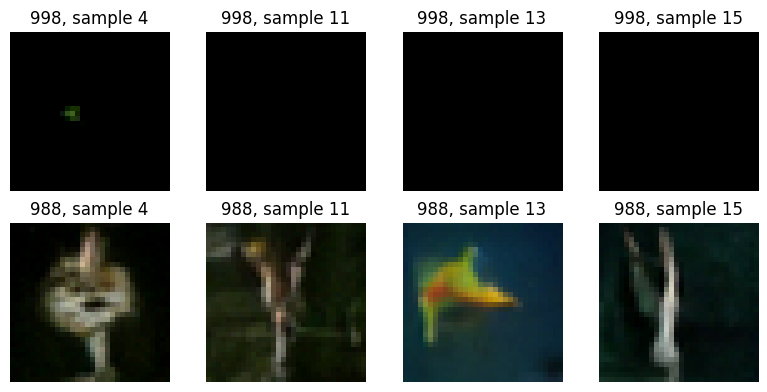

In [43]:
@torch.no_grad()
def compare_teacher_starts():
    levels = grid.tolist()
    assert levels[-2:] == [988, 998]
    assert noise.shape[0] == teacher_outputs.shape[0] == 16

    # Start at 988 using the same noise as the previous test.
    x = noise.clone()
    for pos in range(len(levels) - 2, 0, -1):
        high, low = levels[pos], levels[pos - 1]
        t = torch.full((len(x),), high, dtype=torch.long, device=device)
        eps = teacher(x, t)
        ah, al = alpha_time_t[high], alpha_time_t[low]
        clean = (x - torch.sqrt(1 - ah) * eps) / torch.sqrt(ah)
        x = torch.sqrt(al) * clean + torch.sqrt(1 - al) * eps
        if not torch.isfinite(x).all():
            raise FloatingPointError(f'Non-finite output at {high} -> {low}')

    for label, images in [('998', teacher_outputs), ('988', x)]:
        below = (images < 0).float().mean(dim=(1, 2, 3))
        print(f'Start {label}: {(below > 0.9).sum().item()}/16 images '
              f'with over 90% of pixels below zero')
        for i in [4, 11, 13, 15]:
            print(f'  sample {i}: below zero={below[i].item():.1%}, '
                  f'range=[{images[i].min().item():.2f}, {images[i].max().item():.2f}]')

    fig, axes = plt.subplots(2, 4, figsize=(8, 4))
    for row, (label, images) in enumerate([('998', teacher_outputs), ('988', x)]):
        for col, i in enumerate([4, 11, 13, 15]):
            axes[row, col].imshow(images[i].clamp(0, 1).cpu().permute(1, 2, 0))
            axes[row, col].set_title(f'{label}, sample {i}')
            axes[row, col].axis('off')
    plt.tight_layout()
    plt.show()

compare_teacher_starts()

One large step: 6/16 images with over 90% of pixels below zero
  sample 4: below zero=99.1%, range=[-0.26, 0.39]
  sample 11: below zero=100.0%, range=[-0.28, -0.12]
  sample 13: below zero=100.0%, range=[-0.13, -0.05]
  sample 15: below zero=100.0%, range=[-0.24, -0.10]
Ten small steps: 0/16 images with over 90% of pixels below zero
  sample 4: below zero=74.9%, range=[-0.09, 0.77]
  sample 11: below zero=72.8%, range=[-0.06, 0.58]
  sample 13: below zero=11.2%, range=[-0.02, 0.71]
  sample 15: below zero=84.6%, range=[-0.07, 0.75]


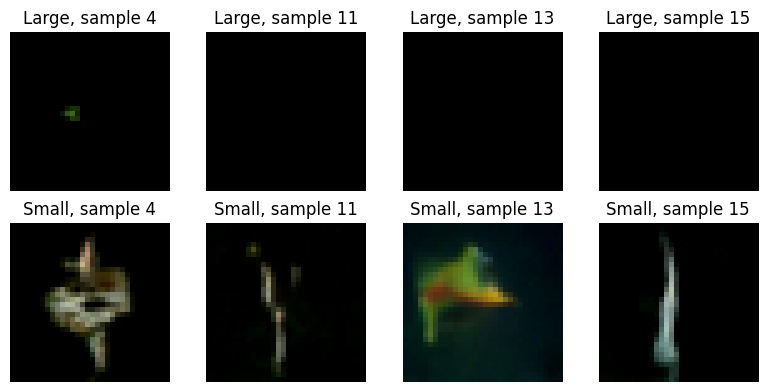

In [44]:
@torch.no_grad()
def test_smaller_first_steps():
    levels = grid.tolist()
    assert levels[-2:] == [988, 998]
    assert noise.shape[0] == teacher_outputs.shape[0] == 16

    x = noise.clone()
    pairs = [(high, high - 1) for high in range(998, 988, -1)]
    pairs += [(levels[pos], levels[pos - 1])
              for pos in range(len(levels) - 2, 0, -1)]

    for high, low in pairs:
        t = torch.full((len(x),), high, dtype=torch.long, device=device)
        eps = teacher(x, t)
        ah, al = alpha_time_t[high], alpha_time_t[low]
        clean = (x - torch.sqrt(1 - ah) * eps) / torch.sqrt(ah)
        x = torch.sqrt(al) * clean + torch.sqrt(1 - al) * eps
        if not torch.isfinite(x).all():
            raise FloatingPointError(f'Non-finite output at {high} -> {low}')

    for label, images in [('One large step', teacher_outputs), ('Ten small steps', x)]:
        below = (images < 0).float().mean(dim=(1, 2, 3))
        print(f'{label}: {(below > 0.9).sum().item()}/16 images '
              f'with over 90% of pixels below zero')
        for i in [4, 11, 13, 15]:
            print(f'  sample {i}: below zero={below[i].item():.1%}, '
                  f'range=[{images[i].min().item():.2f}, {images[i].max().item():.2f}]')

    fig, axes = plt.subplots(2, 4, figsize=(8, 4))
    for row, (label, images) in enumerate([('Large', teacher_outputs), ('Small', x)]):
        for col, i in enumerate([4, 11, 13, 15]):
            axes[row, col].imshow(images[i].clamp(0, 1).cpu().permute(1, 2, 0))
            axes[row, col].set_title(f'{label}, sample {i}')
            axes[row, col].axis('off')
    plt.tight_layout()
    plt.show()

test_smaller_first_steps()

Finished batch 1/4
Finished batch 2/4
Finished batch 3/4
Finished batch 4/4

Large step:
  images with >90% below zero: 18/64
  images with >99% below zero: 10/64
  average pixels below zero: 45.9%
  average pixels above one: 1.2%
  raw range: [-0.40, 1.12]

Small steps:
  images with >90% below zero: 0/64
  images with >99% below zero: 0/64
  average pixels below zero: 9.6%
  average pixels above one: 0.9%
  raw range: [-0.21, 1.12]


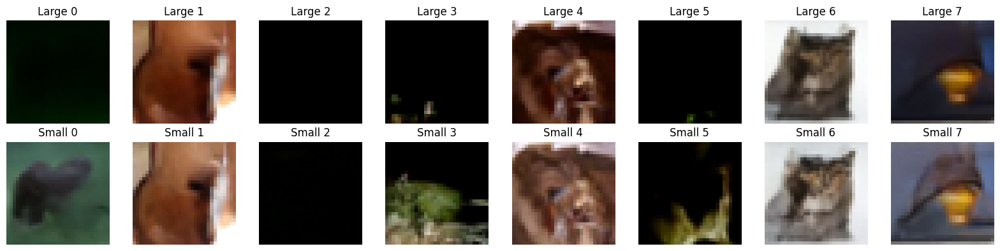

In [45]:
@torch.no_grad()
def validate_teacher_steps():
    levels = grid.tolist()
    if levels[-2:] != [988, 998]:
        raise ValueError('Expected the 998 experiment grid.')
    if teacher.training:
        raise ValueError('Teacher must be in evaluation mode.')

    coarse_pairs = [(levels[i], levels[i - 1])
                    for i in range(len(levels) - 1, 0, -1)]
    fine_pairs = [(t, t - 1) for t in range(998, 988, -1)]
    fine_pairs += [(levels[i], levels[i - 1])
                   for i in range(len(levels) - 2, 0, -1)]

    def follow(start, pairs):
        x = start.clone()
        for high, low in pairs:
            t = torch.full((len(x),), high, dtype=torch.long, device=device)
            eps = teacher(x, t)
            ah, al = alpha_time_t[high], alpha_time_t[low]
            clean = (x - torch.sqrt(1 - ah) * eps) / torch.sqrt(ah)
            x = torch.sqrt(al) * clean + torch.sqrt(1 - al) * eps
        if not torch.isfinite(x).all():
            raise FloatingPointError('Teacher trajectory produced non-finite values.')
        return x

    gen = torch.Generator(device=device).manual_seed(271828)
    coarse, fine = [], []
    for batch in range(4):
        z = torch.randn((16, 3, 32, 32), generator=gen, device=device)
        coarse.append(follow(z, coarse_pairs).cpu())
        fine.append(follow(z, fine_pairs).cpu())
        print(f'Finished batch {batch + 1}/4')

    coarse, fine = torch.cat(coarse), torch.cat(fine)
    for name, images in [('Large step', coarse), ('Small steps', fine)]:
        below = (images < 0).float().mean(dim=(1, 2, 3))
        above = (images > 1).float().mean()
        print(f'\n{name}:')
        print(f'  images with >90% below zero: {(below > 0.9).sum().item()}/64')
        print(f'  images with >99% below zero: {(below > 0.99).sum().item()}/64')
        print(f'  average pixels below zero: {below.mean().item():.1%}')
        print(f'  average pixels above one: {above.item():.1%}')
        print(f'  raw range: [{images.min().item():.2f}, {images.max().item():.2f}]')

    fig, axes = plt.subplots(2, 8, figsize=(16, 4))
    for row, (name, images) in enumerate([('Large', coarse), ('Small', fine)]):
        for i in range(8):
            axes[row, i].imshow(images[i].clamp(0, 1).permute(1, 2, 0))
            axes[row, i].set_title(f'{name} {i}')
            axes[row, i].axis('off')
    plt.tight_layout()
    plt.show()

validate_teacher_steps()

Trajectory check passed; non-top pair is unchanged.
Saving to: /content/gdrive/My Drive/Queens/CISC473/consistency_distillation_998_warmup_substeps_v1


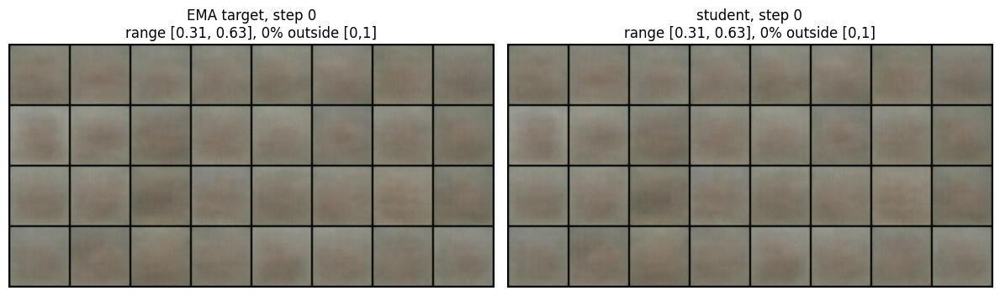

step 50: loss=0.000097, grad norm=0.0028, 0.319 s/step, train time 0.3 min
step 100: loss=0.000005, grad norm=0.0008, 0.330 s/step, train time 0.5 min
step 150: loss=0.000003, grad norm=0.0021, 0.325 s/step, train time 0.8 min
step 200: loss=0.000003, grad norm=0.0007, 0.315 s/step, train time 1.1 min
step 250: loss=0.000002, grad norm=0.0011, 0.315 s/step, train time 1.3 min
step 300: loss=0.000002, grad norm=0.0027, 0.314 s/step, train time 1.6 min
step 350: loss=0.000003, grad norm=0.0011, 0.318 s/step, train time 1.9 min
step 400: loss=0.000003, grad norm=0.0026, 0.322 s/step, train time 2.1 min
step 450: loss=0.000003, grad norm=0.0108, 0.317 s/step, train time 2.4 min
step 500: loss=0.000002, grad norm=0.0020, 0.316 s/step, train time 2.7 min


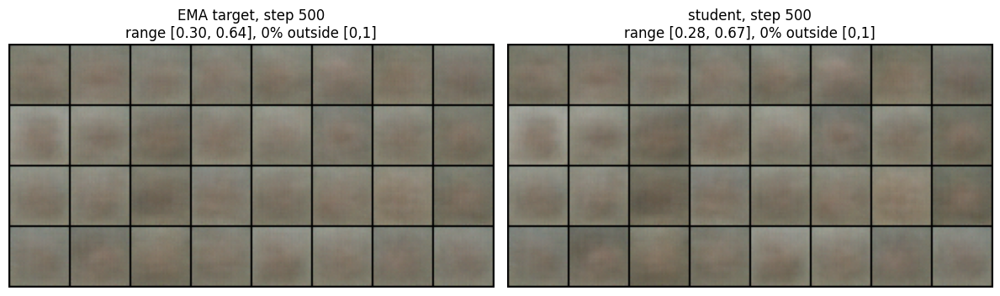

  saved checkpoint at step 500
  saved snapshot consistency_student_step0000500.pt


In [46]:
# Verify the warm-up and previous 500-step baseline.
warmup_path = TEACHER_PATH.parent / 'consistency_distillation_998_warmup' / 'warmup_student.pt'
baseline_path = (
    TEACHER_PATH.parent / 'consistency_distillation_998_warmup_distill_v1'
    / 'consistency_student_ckpt.pt'
)
new_dir = TEACHER_PATH.parent / 'consistency_distillation_998_warmup_substeps_v1'

if not warmup_path.is_file() or not baseline_path.is_file():
    raise FileNotFoundError('Warm-up or previous baseline checkpoint is missing.')
if new_dir.exists():
    raise FileExistsError(f'{new_dir} already exists. Choose a new folder name.')
if grid[-2:].tolist() != [988, 998] or SAMPLE_T != 998:
    raise ValueError('Expected the 998 grid and sampling timestep.')
if teacher.training or any(p.requires_grad for p in teacher.parameters()):
    raise ValueError('Teacher must be frozen and in evaluation mode.')

baseline = torch.load(baseline_path, map_location='cpu', weights_only=True)
cfg = baseline['config']
if cfg['grid'] != grid.tolist() or cfg['teacher_sha256'] != teacher_sha256():
    raise ValueError('Grid or teacher differs from the previous baseline.')
for key, value in [
    ('batch_size', BATCH_SIZE),
    ('learning_rate', LEARNING_RATE),
    ('ema_decay', EMA_DECAY),
    ('grad_clip_norm', GRAD_CLIP_NORM),
]:
    if cfg[key] != value:
        raise ValueError(f'{key} differs from the previous baseline.')

digest = hashlib.sha256()
with open(warmup_path, 'rb') as f:
    for block in iter(lambda: f.read(1 << 20), b''):
        digest.update(block)
warmup_sha = digest.hexdigest()
if cfg['warmup_sha256'] != warmup_sha:
    raise ValueError('Warm-up checkpoint differs from the previous baseline.')

warmup_state = torch.load(warmup_path, map_location=device, weights_only=True)
torch.testing.assert_close(warmup_state['noise_std'], student.noise_std)

# Keep the existing step for every pair except 998 -> 988.
original_trajectory_pair = teacher_trajectory_pair

@torch.no_grad()
def substepped_trajectory_pair(teacher_model, x0, t_high, t_low, noise=None):
    x_high, x_low = original_trajectory_pair(
        teacher_model, x0, t_high, t_low, noise
    )
    top = (t_high == 998) & (t_low == 988)
    if top.any():
        x = x_high[top].clone()
        for high in range(998, 988, -1):
            t = torch.full((len(x),), high, dtype=torch.long, device=device)
            eps = teacher_model(x, t)
            ah, al = alpha_time_t[high], alpha_time_t[high - 1]
            clean = (x - torch.sqrt(1 - ah) * eps) / torch.sqrt(ah)
            x = torch.sqrt(al) * clean + torch.sqrt(1 - al) * eps
        if not torch.isfinite(x).all():
            raise FloatingPointError('Non-finite substepped trajectory.')
        x_low = x_low.clone()
        x_low[top] = x
    return x_high, x_low

# Check that the input and non-top pair are unchanged.
test_x0 = torch.stack([cifar_train[i][0] for i in range(2)]).to(device)
gen = torch.Generator(device=device).manual_seed(123)
test_noise = torch.randn(test_x0.shape, generator=gen, device=device)
test_high = torch.tensor([998, 988], dtype=torch.long, device=device)
test_low = torch.tensor([988, 978], dtype=torch.long, device=device)

old_high, old_low = original_trajectory_pair(
    teacher, test_x0, test_high, test_low, test_noise
)
new_high, new_low = substepped_trajectory_pair(
    teacher, test_x0, test_high, test_low, test_noise
)
torch.testing.assert_close(new_high, old_high)
torch.testing.assert_close(new_low[1], old_low[1])
print('Trajectory check passed; non-top pair is unchanged.')

# Set up a fresh run in its own folder.
new_dir.mkdir()
CHECKPOINT_DIR = new_dir
CHECKPOINT_PATH = new_dir / 'consistency_student_ckpt.pt'
SAMPLE_DIR = new_dir / 'samples'
SAMPLE_DIR.mkdir()

teacher_trajectory_pair = substepped_trajectory_pair
student.load_state_dict(warmup_state)
ema_student.load_state_dict(student.state_dict())
student.train()
student.requires_grad_(True)
ema_student.eval()
ema_student.requires_grad_(False)
optimizer = torch.optim.Adam(student.parameters(), lr=LEARNING_RATE)
global_step = 0
training_state = {'train_seconds': 0.0, 'loss_log': [], 'peak_gpu_memory_gb': 0.0}

# Record the changed teacher step in the new checkpoints.
def make_config(_base=make_config):
    config = _base()
    config['student_init'] = 'teacher weights plus supervised denoising warm-up'
    config['warmup_checkpoint'] = str(warmup_path)
    config['warmup_sha256'] = warmup_sha
    config['teacher_trajectory'] = 'DDIM: 998 to 988 in ten steps; other pairs unchanged'
    return config

print('Saving to:', new_dir)
show_samples(0)
run_training(500, log_every=50, sample_every=500, save_every=500, snapshot_every=500)

sparse: >90% below zero: 14/64; mean below zero: 38.7%; mean above one: 3.4%; range: [-0.30, 1.15]
substepped: >90% below zero: 0/64; mean below zero: 8.3%; mean above one: 1.9%; range: [-0.10, 1.09]


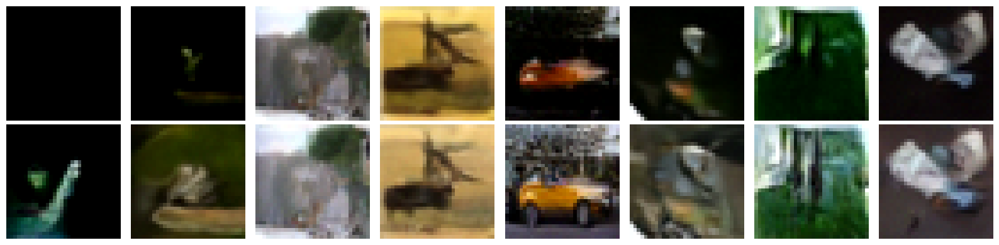

In [47]:
import hashlib
import matplotlib.pyplot as plt

assert device.type == "cuda", "Use a GPU runtime for this experiment."
assert not teacher.training
assert not any(p.requires_grad for p in teacher.parameters())

# Rebuild the 998 experiment grid independently of notebook state.
levels = torch.linspace(0, 998, steps=101).round().long().tolist()
assert levels[-3:] == [978, 988, 998]
assert all(a < b for a, b in zip(levels, levels[1:]))

sparse_path = levels[::-1]
substep_path = list(range(998, 987, -1)) + levels[-3::-1]
assert substep_path[:11] == list(range(998, 987, -1))
assert substep_path[-1] == 0


@torch.no_grad()
def direct_teacher_sample(noise, path):
    x = noise.to(device)

    for high, low in zip(path[:-1], path[1:]):
        t = torch.full((len(x),), high, dtype=torch.long, device=device)
        eps = teacher(x, t)
        a_high = alpha_time_t[high]
        a_low = alpha_time_t[low]

        x0_pred = (x - (1 - a_high).sqrt() * eps) / a_high.sqrt()
        x = a_low.sqrt() * x0_pred + (1 - a_low).sqrt() * eps

        if not torch.isfinite(x).all():
            raise FloatingPointError(f"Non-finite teacher output at {high} -> {low}")

    return x.cpu()


def make_noise(count, seed):
    generator = torch.Generator(device="cpu").manual_seed(seed)
    return torch.randn(count, 3, 32, 32, generator=generator)


@torch.no_grad()
def generate_targets(noise, path, batch_size=32):
    return torch.cat([
        direct_teacher_sample(noise[i:i + batch_size], path)
        for i in range(0, len(noise), batch_size)
    ])


probe_noise = make_noise(64, seed=1234)
sparse_targets = generate_targets(probe_noise, sparse_path)
substep_targets = generate_targets(probe_noise, substep_path)

for name, images in [("sparse", sparse_targets), ("substepped", substep_targets)]:
    below = (images < 0).float().mean(dim=(1, 2, 3))
    above = (images > 1).float().mean(dim=(1, 2, 3))
    print(
        f"{name}: >90% below zero: {(below > 0.9).sum().item()}/64; "
        f"mean below zero: {below.mean().item():.1%}; "
        f"mean above one: {above.mean().item():.1%}; "
        f"range: [{images.min().item():.2f}, {images.max().item():.2f}]"
    )

fig, axes = plt.subplots(2, 8, figsize=(16, 4))
for row, (label, images) in enumerate(
    [("Sparse", sparse_targets), ("Substepped", substep_targets)]
):
    for col in range(8):
        axes[row, col].imshow(images[col].clamp(0, 1).permute(1, 2, 0))
        axes[row, col].axis("off")
    axes[row, 0].set_ylabel(label)
plt.tight_layout()
plt.show()

In [50]:
# Verify that the current teacher and schedule match the earlier experiment.
expected_sha = "93089b1c124f894c59dbef7d45a9b6c75f8727e2f009efdeb227d7957b9a2a71"

digest = hashlib.sha256()
with open(TEACHER_PATH, "rb") as f:
    for chunk in iter(lambda: f.read(1024 * 1024), b""):
        digest.update(chunk)

assert digest.hexdigest() == expected_sha, "Teacher checkpoint differs."
assert abs(alpha_time_t.double().sum().item() - 495.5774450877395) < 0.001, \
    "Schedule differs."

saved_teacher = torch.load(TEACHER_PATH, map_location="cpu", weights_only=True)
current_teacher = teacher.state_dict()
assert saved_teacher.keys() == current_teacher.keys()
assert all(
    torch.equal(saved_teacher[k], current_teacher[k].detach().cpu())
    for k in saved_teacher
), "In-memory teacher differs from the checkpoint."
del saved_teacher, current_teacher

# Create a new folder; never overwrite an existing experiment.
EXPERIMENT_DIR = TEACHER_PATH.parent / "direct_teacher_targets_v1"
EXPERIMENT_DIR.mkdir(exist_ok=False)

config = {
    "teacher_path": str(TEACHER_PATH),
    "teacher_sha256": expected_sha,
    "alpha_time_t": alpha_time_t.cpu(),
    "path": substep_path,
    "target": "raw deterministic teacher output at timestep 0",
    "initialization": "teacher U-Net weights in existing ConsistencyStudent",
    "loss": "raw image-space MSE to teacher endpoint",
    "torch_version": str(torch.__version__),
}
torch.save(config, EXPERIMENT_DIR / "config.pt")

pairs = {}
for name, count, seed in [
    ("train", 2048, 23456),
    ("validation", 128, 34567),
    ("test", 128, 45678),
]:
    print(f"\nGenerating {name}: {count} pairs")
    noise = make_noise(count, seed)
    batches = []

    for start in range(0, count, 32):
        batch = noise[start:start + 32]
        batches.append(direct_teacher_sample(batch, substep_path))
        done = min(start + len(batch), count)
        if done % 256 == 0 or done == count:
            print(f"  {done}/{count}")

    targets = torch.cat(batches)
    pairs[name] = {"noise": noise, "targets": targets, "seed": seed}
    torch.save(pairs[name], EXPERIMENT_DIR / f"{name}_pairs.pt")

    print(
        f"  target range: [{targets.min().item():.2f}, "
        f"{targets.max().item():.2f}]; "
        f"variation: {targets.std(dim=0, unbiased=False).mean().item():.4f}"
    )

print("\nAll pairs saved in:", EXPERIMENT_DIR)


Generating train: 2048 pairs
  256/2048
  512/2048
  768/2048
  1024/2048
  1280/2048
  1536/2048
  1792/2048
  2048/2048
  target range: [-0.34, 1.24]; variation: 0.2641

Generating validation: 128 pairs
  128/128
  target range: [-0.17, 1.15]; variation: 0.2578

Generating test: 128 pairs
  128/128
  target range: [-0.38, 1.66]; variation: 0.2803

All pairs saved in: /content/gdrive/My Drive/Queens/CISC473/direct_teacher_targets_v1



Step 0
train subset: MSE=0.51574; mean-image baseline=0.06957; variation student/teacher=0.6441/0.2611; outside [0,1]=56.0%
validation: MSE=0.51011; mean-image baseline=0.06809; variation student/teacher=0.6442/0.2578; outside [0,1]=56.3%


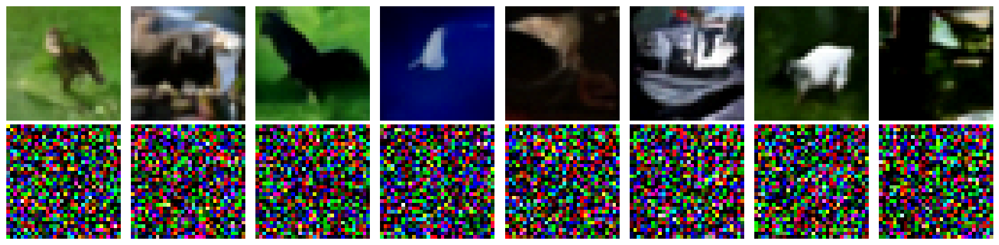

Saved: /content/gdrive/My Drive/Queens/CISC473/direct_teacher_targets_v1/direct_student_step00000.pt

Step 250
train subset: MSE=0.01823; mean-image baseline=0.06957; variation student/teacher=0.2433/0.2611; outside [0,1]=12.7%
validation: MSE=0.01859; mean-image baseline=0.06809; variation student/teacher=0.2420/0.2578; outside [0,1]=12.5%


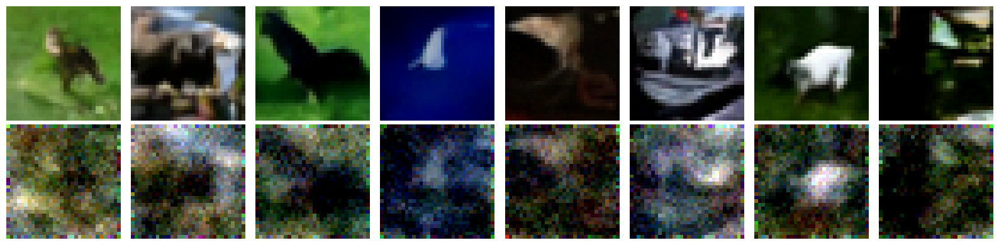

Saved: /content/gdrive/My Drive/Queens/CISC473/direct_teacher_targets_v1/direct_student_step00250.pt

Step 1000
train subset: MSE=0.00650; mean-image baseline=0.06957; variation student/teacher=0.2485/0.2611; outside [0,1]=10.7%
validation: MSE=0.00751; mean-image baseline=0.06809; variation student/teacher=0.2437/0.2578; outside [0,1]=10.0%


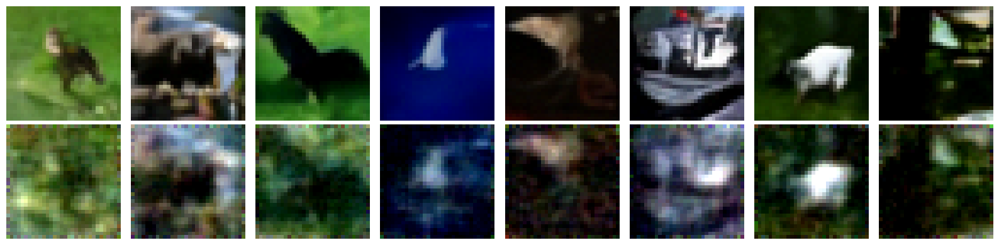

Saved: /content/gdrive/My Drive/Queens/CISC473/direct_teacher_targets_v1/direct_student_step01000.pt


In [53]:
import torch.nn.functional as F

assert all(name in pairs for name in ("train", "validation", "test"))
assert not any(EXPERIMENT_DIR.glob("direct_student_step*.pt")), \
    "Student checkpoints already exist; do not restart this cell."

# A separate model: existing student and EMA checkpoints are untouched.
direct_student = ConsistencyStudent(alpha_time_t).to(device)
direct_student.unet.load_state_dict(teacher.state_dict())
direct_student.train()

direct_optimizer = torch.optim.Adam(direct_student.parameters(), lr=1e-4)
direct_batch_rng = torch.Generator(device="cpu").manual_seed(56789)

train_noise = pairs["train"]["noise"]
train_targets = pairs["train"]["targets"]
mean_target = train_targets.mean(dim=0, keepdim=True)
history = []


@torch.no_grad()
def direct_metrics(name, noise, targets, show=False):
    was_training = direct_student.training
    direct_student.eval()

    outputs = []
    for start in range(0, len(noise), 32):
        batch = noise[start:start + 32].to(device)
        t = torch.full((len(batch),), 998, dtype=torch.long, device=device)
        outputs.append(direct_student(batch, t).cpu())

    direct_student.train(was_training)
    outputs = torch.cat(outputs)

    if not torch.isfinite(outputs).all():
        raise FloatingPointError(f"{name} outputs contain non-finite values.")

    mse = F.mse_loss(outputs, targets).item()
    baseline = F.mse_loss(mean_target.expand_as(targets), targets).item()
    output_variation = outputs.std(dim=0, unbiased=False).mean().item()
    target_variation = targets.std(dim=0, unbiased=False).mean().item()
    outside = ((outputs < 0) | (outputs > 1)).float().mean().item()

    print(
        f"{name}: MSE={mse:.5f}; mean-image baseline={baseline:.5f}; "
        f"variation student/teacher={output_variation:.4f}/{target_variation:.4f}; "
        f"outside [0,1]={outside:.1%}"
    )

    if show:
        fig, axes = plt.subplots(2, 8, figsize=(16, 4))
        for row, (label, images) in enumerate(
            [("Teacher", targets), ("Student", outputs)]
        ):
            for col in range(8):
                axes[row, col].imshow(
                    images[col].clamp(0, 1).permute(1, 2, 0)
                )
                axes[row, col].axis("off")
            axes[row, 0].set_ylabel(label)
        plt.tight_layout()
        plt.show()

    return {
        "mse": mse,
        "mean_baseline": baseline,
        "output_variation": output_variation,
        "target_variation": target_variation,
        "outside_fraction": outside,
    }


for direct_step in range(1001):
    if direct_step in (0, 250, 1000):
        print(f"\nStep {direct_step}")
        train_metrics = direct_metrics(
            "train subset", train_noise[:128], train_targets[:128]
        )
        val_metrics = direct_metrics(
            "validation",
            pairs["validation"]["noise"],
            pairs["validation"]["targets"],
            show=True,
        )
        history.append({
            "step": direct_step,
            "train": train_metrics,
            "validation": val_metrics,
        })

        checkpoint_path = (
            EXPERIMENT_DIR / f"direct_student_step{direct_step:05d}.pt"
        )
        torch.save({
            "step": direct_step,
            "student": direct_student.state_dict(),
            "optimizer": direct_optimizer.state_dict(),
            "batch_generator_state": direct_batch_rng.get_state(),
            "config": config,
            "history": history,
        }, checkpoint_path)
        print("Saved:", checkpoint_path)

    if direct_step == 1000:
        break

    indices = torch.randint(
        len(train_noise), (32,), generator=direct_batch_rng
    )
    x = train_noise[indices].to(device)
    target = train_targets[indices].to(device)
    t = torch.full((len(x),), 998, dtype=torch.long, device=device)

    prediction = direct_student(x, t)
    loss = F.mse_loss(prediction, target)
    if not torch.isfinite(loss):
        raise FloatingPointError(f"Non-finite loss at step {direct_step + 1}")

    direct_optimizer.zero_grad(set_to_none=True)
    loss.backward()
    torch.nn.utils.clip_grad_norm_(
        direct_student.parameters(), 1.0, error_if_nonfinite=True
    )
    direct_optimizer.step()


Step 2000
train subset: MSE=0.00368; mean-image baseline=0.06957; variation student/teacher=0.2527/0.2611; outside [0,1]=11.4%
validation: MSE=0.00505; mean-image baseline=0.06809; variation student/teacher=0.2460/0.2578; outside [0,1]=10.4%


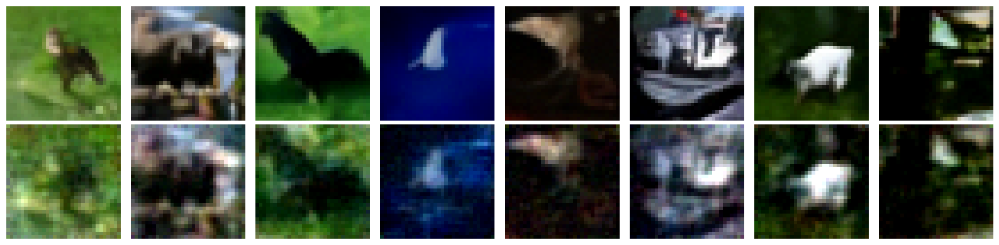

Saved: /content/gdrive/My Drive/Queens/CISC473/direct_teacher_targets_v1/direct_student_step02000.pt


In [54]:
checkpoint_path = EXPERIMENT_DIR / "direct_student_step01000.pt"
next_path = EXPERIMENT_DIR / "direct_student_step02000.pt"

assert checkpoint_path.is_file(), "Wait for the step-1000 checkpoint to finish saving."
assert not next_path.exists(), "Step-2000 checkpoint already exists; don't overwrite it."

checkpoint = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
assert checkpoint["step"] == 1000
assert checkpoint["config"]["teacher_sha256"] == config["teacher_sha256"]
assert checkpoint["config"]["path"] == substep_path

direct_student.load_state_dict(checkpoint["student"])
direct_optimizer.load_state_dict(checkpoint["optimizer"])
direct_batch_rng.set_state(checkpoint["batch_generator_state"])
history = checkpoint["history"]
direct_student.train()

for direct_step in range(1001, 2001):
    indices = torch.randint(len(train_noise), (32,), generator=direct_batch_rng)
    x = train_noise[indices].to(device)
    target = train_targets[indices].to(device)
    t = torch.full((len(x),), 998, dtype=torch.long, device=device)

    prediction = direct_student(x, t)
    loss = F.mse_loss(prediction, target)
    if not torch.isfinite(loss):
        raise FloatingPointError(f"Non-finite loss at step {direct_step}")

    direct_optimizer.zero_grad(set_to_none=True)
    loss.backward()
    torch.nn.utils.clip_grad_norm_(
        direct_student.parameters(), 1.0, error_if_nonfinite=True
    )
    direct_optimizer.step()

print("\nStep 2000")
train_metrics = direct_metrics("train subset", train_noise[:128], train_targets[:128])
val_metrics = direct_metrics(
    "validation",
    pairs["validation"]["noise"],
    pairs["validation"]["targets"],
    show=True,
)
history.append({"step": 2000, "train": train_metrics, "validation": val_metrics})

torch.save({
    "step": 2000,
    "student": direct_student.state_dict(),
    "optimizer": direct_optimizer.state_dict(),
    "batch_generator_state": direct_batch_rng.get_state(),
    "config": config,
    "history": history,
}, next_path)
print("Saved:", next_path)


Step 3000
train subset: MSE=0.00246; mean-image baseline=0.06957; variation student/teacher=0.2591/0.2611; outside [0,1]=11.5%
validation: MSE=0.00421; mean-image baseline=0.06809; variation student/teacher=0.2520/0.2578; outside [0,1]=10.4%


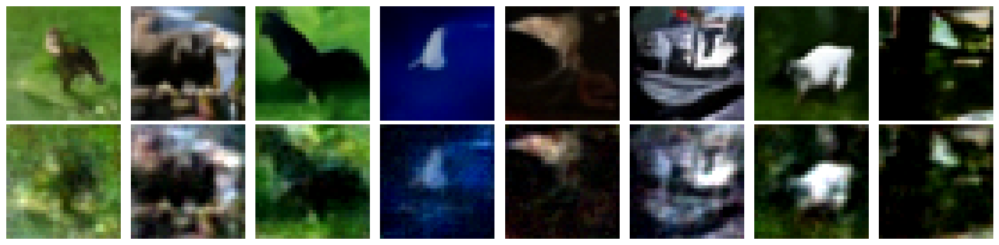

Saved: /content/gdrive/My Drive/Queens/CISC473/direct_teacher_targets_v1/direct_student_step03000.pt

Step 4000
train subset: MSE=0.00182; mean-image baseline=0.06957; variation student/teacher=0.2611/0.2611; outside [0,1]=12.5%
validation: MSE=0.00384; mean-image baseline=0.06809; variation student/teacher=0.2527/0.2578; outside [0,1]=11.0%


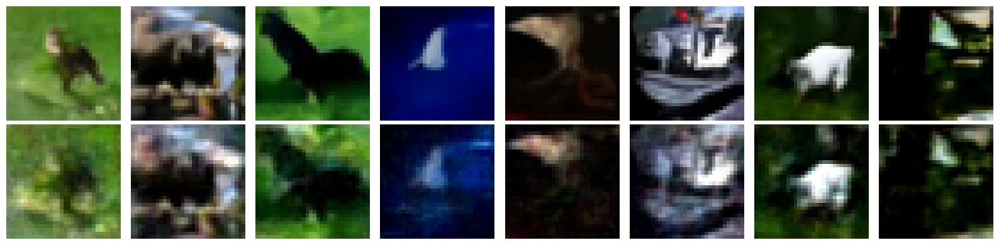

Saved: /content/gdrive/My Drive/Queens/CISC473/direct_teacher_targets_v1/direct_student_step04000.pt


In [55]:
checkpoint_path = EXPERIMENT_DIR / "direct_student_step02000.pt"
assert checkpoint_path.is_file(), "Wait for the step-2000 checkpoint to save."

for step in (3000, 4000):
    path = EXPERIMENT_DIR / f"direct_student_step{step:05d}.pt"
    assert not path.exists(), f"{path.name} already exists; don't overwrite it."

checkpoint = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
assert checkpoint["step"] == 2000
assert checkpoint["config"]["teacher_sha256"] == config["teacher_sha256"]
assert checkpoint["config"]["path"] == substep_path

direct_student.load_state_dict(checkpoint["student"])
direct_optimizer.load_state_dict(checkpoint["optimizer"])
direct_batch_rng.set_state(checkpoint["batch_generator_state"])
history = checkpoint["history"]
direct_student.train()

for direct_step in range(2001, 4001):
    indices = torch.randint(len(train_noise), (32,), generator=direct_batch_rng)
    x = train_noise[indices].to(device)
    target = train_targets[indices].to(device)
    t = torch.full((len(x),), 998, dtype=torch.long, device=device)

    prediction = direct_student(x, t)
    loss = F.mse_loss(prediction, target)
    if not torch.isfinite(loss):
        raise FloatingPointError(f"Non-finite loss at step {direct_step}")

    direct_optimizer.zero_grad(set_to_none=True)
    loss.backward()
    torch.nn.utils.clip_grad_norm_(
        direct_student.parameters(), 1.0, error_if_nonfinite=True
    )
    direct_optimizer.step()

    if direct_step in (3000, 4000):
        print(f"\nStep {direct_step}")
        train_metrics = direct_metrics(
            "train subset", train_noise[:128], train_targets[:128]
        )
        val_metrics = direct_metrics(
            "validation",
            pairs["validation"]["noise"],
            pairs["validation"]["targets"],
            show=True,
        )
        history.append({
            "step": direct_step,
            "train": train_metrics,
            "validation": val_metrics,
        })

        path = EXPERIMENT_DIR / f"direct_student_step{direct_step:05d}.pt"
        torch.save({
            "step": direct_step,
            "student": direct_student.state_dict(),
            "optimizer": direct_optimizer.state_dict(),
            "batch_generator_state": direct_batch_rng.get_state(),
            "config": config,
            "history": history,
        }, path)
        print("Saved:", path)

test: MSE=0.00400; mean-image baseline=0.07977; variation student/teacher=0.2697/0.2803; outside [0,1]=11.8%


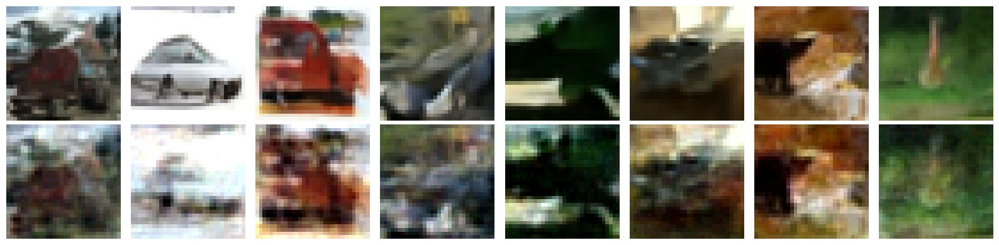

In [56]:
checkpoint_path = EXPERIMENT_DIR / "direct_student_step04000.pt"
assert checkpoint_path.is_file(), "Wait for the step-4000 checkpoint to save."

checkpoint = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
assert checkpoint["step"] == 4000
assert checkpoint["config"]["teacher_sha256"] == config["teacher_sha256"]
assert checkpoint["config"]["path"] == substep_path

direct_student.load_state_dict(checkpoint["student"])

test_metrics = direct_metrics(
    "test",
    pairs["test"]["noise"],
    pairs["test"]["targets"],
    show=True,
)

In [59]:
%pip install pytorch-fid

In [60]:
from pathlib import Path
import tempfile
import json
import shutil
import torchvision
from PIL import Image

# Check the FID dependency before generating images.
from pytorch_fid.fid_score import calculate_fid_given_paths

assert device.type == "cuda"
assert shutil.disk_usage("/content").free > 1_000_000_000, \
    "At least 1 GB of free space is required."

checkpoint_path = EXPERIMENT_DIR / "direct_student_step04000.pt"
checkpoint = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
assert checkpoint["step"] == 4000
assert checkpoint["config"]["teacher_sha256"] == config["teacher_sha256"]
assert checkpoint["config"]["path"] == substep_path
assert torch.equal(checkpoint["config"]["alpha_time_t"], alpha_time_t.cpu())

direct_student.load_state_dict(checkpoint["student"])
direct_student.eval()

fid_root = Path(tempfile.mkdtemp(prefix="direct_fid_50k_", dir="/content"))
real_dir = fid_root / "real"
generated_dir = fid_root / "generated"
real_dir.mkdir()
generated_dir.mkdir()

# Original 8-bit CIFAR-10 training images, without rescaling.
fid_real = torchvision.datasets.CIFAR10(
    root="/content/data", train=True, download=True
)
assert len(fid_real) == 50_000

print("Saving real images...")
for i in range(len(fid_real)):
    image, _ = fid_real[i]
    image.save(real_dir / f"{i:05d}.png")
    if (i + 1) % 10_000 == 0:
        print(f"  {i + 1}/50000")

# Fresh Gaussian noise, distinct from the train/validation/test seeds.
fid_seed = 67890
fid_rng = torch.Generator(device="cpu").manual_seed(fid_seed)
below_count = 0
above_count = 0
pixel_count = 0

print("Generating student images...")
with torch.inference_mode():
    for start in range(0, 50_000, 32):
        count = min(32, 50_000 - start)
        noise = torch.randn(count, 3, 32, 32, generator=fid_rng).to(device)
        t = torch.full((count,), 998, dtype=torch.long, device=device)
        output = direct_student(noise, t)

        if not torch.isfinite(output).all():
            raise FloatingPointError(f"Non-finite output at image {start}")

        below_count += (output < 0).sum().item()
        above_count += (output > 1).sum().item()
        pixel_count += output.numel()

        images = output.clamp(0, 1).mul(255).round().to(torch.uint8).cpu()
        for j, image in enumerate(images):
            Image.fromarray(image.permute(1, 2, 0).numpy()).save(
                generated_dir / f"{start + j:05d}.png"
            )

        if (start + count) % 10_000 == 0:
            print(f"  {start + count}/50000")

fid_metadata = {
    "checkpoint": str(checkpoint_path),
    "checkpoint_step": 4000,
    "teacher_sha256": checkpoint["config"]["teacher_sha256"],
    "generated_images": 50_000,
    "real_images": 50_000,
    "real_split": "CIFAR-10 training",
    "noise_seed": fid_seed,
    "sampling_timestep": 998,
    "generated_preprocessing": "clamp [0,1], round to uint8, PNG",
    "real_preprocessing": "original CIFAR-10 uint8, PNG",
    "fraction_below_zero_before_clipping": below_count / pixel_count,
    "fraction_above_one_before_clipping": above_count / pixel_count,
    "torch_version": str(torch.__version__),
    "torchvision_version": str(torchvision.__version__),
}

with open(fid_root / "metadata.json", "x") as f:
    json.dump(fid_metadata, f, indent=2)

print("\nImage sets ready:", fid_root)
print(f"Below zero before clipping: {below_count / pixel_count:.2%}")
print(f"Above one before clipping: {above_count / pixel_count:.2%}")

Saving real images...
  10000/50000
  20000/50000
  30000/50000
  40000/50000
  50000/50000
Generating student images...
  20000/50000
  40000/50000
  50000/50000

Image sets ready: /content/direct_fid_50k_qor9ihhh
Below zero before clipping: 9.82%
Above one before clipping: 1.13%


In [61]:
import math
import json

assert len(list(real_dir.glob("*.png"))) == 50_000
assert len(list(generated_dir.glob("*.png"))) == 50_000

result_path = EXPERIMENT_DIR / "fid_step04000_50k_v1.json"
assert not result_path.exists(), "FID result already exists; don't overwrite it."

fid = calculate_fid_given_paths(
    paths=[str(real_dir), str(generated_dir)],
    batch_size=50,
    device=device,
    dims=2048,
)

if not math.isfinite(fid):
    raise FloatingPointError("FID is not finite.")

result = {
    **fid_metadata,
    "fid": float(fid),
    "implementation": "pytorch-fid",
    "feature_dimensions": 2048,
}
with open(result_path, "x") as f:
    json.dump(result, f, indent=2)

print(f"Student FID: {fid:.3f}")
print("Saved result:", result_path)

Downloading: "https://github.com/mseitzer/pytorch-fid/releases/download/fid_weights/pt_inception-2015-12-05-6726825d.pth" to /root/.cache/torch/hub/checkpoints/pt_inception-2015-12-05-6726825d.pth


100%|██████████| 91.2M/91.2M [00:00<00:00, 381MB/s]
100%|██████████| 1000/1000 [03:25<00:00,  4.87it/s]


Student FID: 163.507
Saved result: /content/gdrive/My Drive/Queens/CISC473/direct_teacher_targets_v1/fid_step04000_50k_v1.json


In [62]:
import hashlib
import json
import math
import shutil
import tempfile
import numpy as np
from PIL import Image

N_COMPARE = 5000

# Verify the teacher, schedule, and student checkpoint.
checkpoint_path = EXPERIMENT_DIR / "direct_student_step04000.pt"
checkpoint = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
assert checkpoint["step"] == 4000
assert checkpoint["config"]["path"] == substep_path
assert torch.equal(checkpoint["config"]["alpha_time_t"], alpha_time_t.cpu())

digest = hashlib.sha256()
with open(TEACHER_PATH, "rb") as f:
    for chunk in iter(lambda: f.read(1024 * 1024), b""):
        digest.update(chunk)
assert digest.hexdigest() == checkpoint["config"]["teacher_sha256"]

saved_teacher = torch.load(TEACHER_PATH, map_location="cpu", weights_only=True)
current_teacher = teacher.state_dict()
assert saved_teacher.keys() == current_teacher.keys()
assert all(
    torch.equal(saved_teacher[k], current_teacher[k].detach().cpu())
    for k in saved_teacher
)
del saved_teacher, current_teacher

assert not teacher.training
assert not any(p.requires_grad for p in teacher.parameters())

direct_student.load_state_dict(checkpoint["student"])
direct_student.eval()

result_path = EXPERIMENT_DIR / "fid_teacher_student_5000_v1.json"
assert not result_path.exists(), "Comparison result already exists."

# Reconstruct the noise in the same batch sizes used for the 50k run.
# Verify the regenerated student PNGs against the originals.
verify_rng = torch.Generator(device="cpu").manual_seed(fid_metadata["noise_seed"])
changed_pixels = 0
total_pixels = 0
max_difference = 0

print("Verifying saved student images against reconstructed noise...")
with torch.inference_mode():
    for start in range(0, N_COMPARE, 32):
        noise = torch.randn(32, 3, 32, 32, generator=verify_rng)
        count = min(32, N_COMPARE - start)
        t = torch.full((32,), 998, dtype=torch.long, device=device)

        output = direct_student(noise.to(device), t)
        regenerated = output.clamp(0, 1).mul(255).round().to(torch.uint8).cpu()[:count]

        saved = torch.stack([
            torch.from_numpy(
                np.array(Image.open(generated_dir / f"{start + j:05d}.png").convert("RGB"))
            ).permute(2, 0, 1)
            for j in range(count)
        ])

        difference = (regenerated.to(torch.int16) - saved.to(torch.int16)).abs()
        changed_pixels += (difference > 0).sum().item()
        total_pixels += difference.numel()
        max_difference = max(max_difference, difference.max().item())

print(f"Maximum PNG difference: {max_difference}/255")
print(f"Changed pixels: {changed_pixels / total_pixels:.4%}")
assert max_difference <= 1 and changed_pixels / total_pixels <= 0.001, \
    "Saved student images do not match reconstructed noise; stop and report this."

# New temporary folders; original 50k images are not modified.
fid5000_root = Path(tempfile.mkdtemp(prefix="teacher_student_fid_5k_", dir="/content"))
real5000 = fid5000_root / "real"
student5000 = fid5000_root / "student"
teacher5000 = fid5000_root / "teacher"
for folder in (real5000, student5000, teacher5000):
    folder.mkdir()

print("Copying the same 5,000 real and student images...")
for i in range(N_COMPARE):
    name = f"{i:05d}.png"
    shutil.copyfile(real_dir / name, real5000 / name)
    shutil.copyfile(generated_dir / name, student5000 / name)

print("Generating 5,000 matched teacher images...")
teacher_rng = torch.Generator(device="cpu").manual_seed(fid_metadata["noise_seed"])
teacher_below = 0
teacher_above = 0
teacher_pixels = 0

for start in range(0, N_COMPARE, 32):
    noise = torch.randn(32, 3, 32, 32, generator=teacher_rng)
    count = min(32, N_COMPARE - start)

    outputs = direct_teacher_sample(noise[:count], substep_path)
    teacher_below += (outputs < 0).sum().item()
    teacher_above += (outputs > 1).sum().item()
    teacher_pixels += outputs.numel()

    images = outputs.clamp(0, 1).mul(255).round().to(torch.uint8)
    for j, image in enumerate(images):
        Image.fromarray(image.permute(1, 2, 0).numpy()).save(
            teacher5000 / f"{start + j:05d}.png"
        )

    if (start + count) % 512 == 0 or start + count == N_COMPARE:
        print(f"  {start + count}/{N_COMPARE}")

print("Comparison images ready:", fid5000_root)
print(f"Teacher below zero before clipping: {teacher_below / teacher_pixels:.2%}")
print(f"Teacher above one before clipping: {teacher_above / teacher_pixels:.2%}")

Verifying saved student images against reconstructed noise...
Maximum PNG difference: 1/255
Changed pixels: 0.0012%
Copying the same 5,000 real and student images...
Generating 5,000 matched teacher images...
  512/5000
  1024/5000
  1536/5000
  2048/5000
  2560/5000
  3072/5000
  3584/5000
  4096/5000
  4608/5000
  5000/5000
Comparison images ready: /content/teacher_student_fid_5k_ze8u8g5l
Teacher below zero before clipping: 9.67%
Teacher above one before clipping: 1.11%


In [63]:
for folder in (real5000, student5000, teacher5000):
    assert len(list(folder.glob("*.png"))) == N_COMPARE

assert not result_path.exists(), "Comparison result already exists."

print("Calculating student FID...")
student_fid_5k = calculate_fid_given_paths(
    [str(real5000), str(student5000)],
    batch_size=50, device=device, dims=2048,
)

print("Calculating teacher FID...")
teacher_fid_5k = calculate_fid_given_paths(
    [str(real5000), str(teacher5000)],
    batch_size=50, device=device, dims=2048,
)

assert math.isfinite(student_fid_5k) and math.isfinite(teacher_fid_5k)

comparison = {
    "student_fid": float(student_fid_5k),
    "teacher_fid": float(teacher_fid_5k),
    "images_per_set": N_COMPARE,
    "real_split": "first 5000 CIFAR-10 training images",
    "noise_seed": fid_metadata["noise_seed"],
    "student_step": 4000,
    "teacher_sha256": checkpoint["config"]["teacher_sha256"],
    "teacher_path": substep_path,
    "preprocessing": "clamp generated images to [0,1], round to uint8 PNG",
    "implementation": "pytorch-fid, 2048 features",
    "teacher_below_zero": teacher_below / teacher_pixels,
    "teacher_above_one": teacher_above / teacher_pixels,
}

with open(result_path, "x") as f:
    json.dump(comparison, f, indent=2)

print(f"\nStudent FID, 5k: {student_fid_5k:.3f}")
print(f"Teacher FID, 5k: {teacher_fid_5k:.3f}")
print("Saved:", result_path)

Calculating student FID...


100%|██████████| 100/100 [00:21<00:00,  4.61it/s]


Calculating teacher FID...


100%|██████████| 100/100 [00:21<00:00,  4.55it/s]



Student FID, 5k: 167.739
Teacher FID, 5k: 51.442
Saved: /content/gdrive/My Drive/Queens/CISC473/direct_teacher_targets_v1/fid_teacher_student_5000_v1.json


In [64]:
import json
import math
import shutil
import tempfile
import numpy as np
from PIL import Image

N_COMPARE = 2048
result_path = EXPERIMENT_DIR / "fid_seen_vs_unseen_2048_v1.json"
assert not result_path.exists(), "Experiment result already exists."

# Load the saved training pairs and experiment metadata.
train_pairs_saved = torch.load(
    EXPERIMENT_DIR / "train_pairs.pt", map_location="cpu", weights_only=True
)
train_config = torch.load(
    EXPERIMENT_DIR / "config.pt", map_location="cpu", weights_only=True
)
checkpoint = torch.load(
    EXPERIMENT_DIR / "direct_student_step04000.pt",
    map_location="cpu", weights_only=True,
)

with open(EXPERIMENT_DIR / "fid_teacher_student_5000_v1.json") as f:
    comparison_5k = json.load(f)

assert checkpoint["step"] == 4000
assert train_config["teacher_sha256"] == checkpoint["config"]["teacher_sha256"]
assert comparison_5k["teacher_sha256"] == train_config["teacher_sha256"]
assert comparison_5k["teacher_path"] == train_config["path"]
assert torch.equal(train_config["alpha_time_t"], alpha_time_t.cpu())
assert train_pairs_saved["seed"] != comparison_5k["noise_seed"]

seen_noise = train_pairs_saved["noise"]
seen_targets = train_pairs_saved["targets"]
assert len(seen_noise) == len(seen_targets) == N_COMPARE
assert torch.isfinite(seen_targets).all()

direct_student.load_state_dict(checkpoint["student"])
direct_student.eval()

# Verify this checkpoint matches the saved unseen student images.
verify_rng = torch.Generator(device="cpu").manual_seed(comparison_5k["noise_seed"])
verify_noise = torch.randn(32, 3, 32, 32, generator=verify_rng)
with torch.inference_mode():
    t = torch.full((32,), 998, dtype=torch.long, device=device)
    verify_output = direct_student(verify_noise.to(device), t)
    verify_pixels = verify_output.clamp(0, 1).mul(255).round().to(torch.uint8).cpu()

saved_pixels = torch.stack([
    torch.from_numpy(
        np.array(Image.open(student5000 / f"{i:05d}.png").convert("RGB"))
    ).permute(2, 0, 1)
    for i in range(32)
])
difference = (verify_pixels.to(torch.int16) - saved_pixels.to(torch.int16)).abs()
assert difference.max().item() <= 1
assert (difference > 0).float().mean().item() <= 0.001

# New temporary folders. Existing images and checkpoints are untouched.
compare_root = Path(tempfile.mkdtemp(prefix="seen_unseen_fid_", dir="/content"))
compare_dirs = {
    name: compare_root / name
    for name in ("real", "seen_student", "seen_teacher", "unseen_student", "unseen_teacher")
}
for folder in compare_dirs.values():
    folder.mkdir()

seen_mse = []
unseen_mse = []

print("Generating student images for training noise...")
with torch.inference_mode():
    for start in range(0, N_COMPARE, 32):
        noise = seen_noise[start:start + 32].to(device)
        t = torch.full((len(noise),), 998, dtype=torch.long, device=device)
        output = direct_student(noise, t)

        if not torch.isfinite(output).all():
            raise FloatingPointError(f"Non-finite student output at {start}")

        student_pixels = output.clamp(0, 1).mul(255).round().to(torch.uint8).cpu()
        teacher_pixels = (
            seen_targets[start:start + len(noise)]
            .clamp(0, 1).mul(255).round().to(torch.uint8)
        )

        errors = (
            (student_pixels.float() - teacher_pixels.float()).square()
            .mean(dim=(1, 2, 3)) / (255 ** 2)
        )
        seen_mse.extend(errors.tolist())

        for j in range(len(noise)):
            name = f"{start + j:05d}.png"
            Image.fromarray(student_pixels[j].permute(1, 2, 0).numpy()).save(
                compare_dirs["seen_student"] / name
            )
            Image.fromarray(teacher_pixels[j].permute(1, 2, 0).numpy()).save(
                compare_dirs["seen_teacher"] / name
            )

        if (start + len(noise)) % 512 == 0:
            print(f"  {start + len(noise)}/{N_COMPARE}")

print("Copying real and unseen images...")
for i in range(N_COMPARE):
    name = f"{i:05d}.png"
    shutil.copyfile(real5000 / name, compare_dirs["real"] / name)
    shutil.copyfile(student5000 / name, compare_dirs["unseen_student"] / name)
    shutil.copyfile(teacher5000 / name, compare_dirs["unseen_teacher"] / name)

    student_image = np.array(Image.open(student5000 / name).convert("RGB"), dtype=np.float32)
    teacher_image = np.array(Image.open(teacher5000 / name).convert("RGB"), dtype=np.float32)
    unseen_mse.append(float(np.mean(((student_image - teacher_image) / 255.0) ** 2)))

seen_errors = torch.tensor(seen_mse)
unseen_errors = torch.tensor(unseen_mse)

print(f"\nSeen paired MSE:   {seen_errors.mean().item():.5f}")
print(f"Unseen paired MSE: {unseen_errors.mean().item():.5f}")
print("These errors use clipped, quantized PNGs.")
print("Images ready:", compare_root)

Generating student images for training noise...
  512/2048
  1024/2048
  1536/2048
  2048/2048
Copying real and unseen images...

Seen paired MSE:   0.00177
Unseen paired MSE: 0.00368
These errors use clipped, quantized PNGs.
Images ready: /content/seen_unseen_fid_9lke2uvp


In [65]:
for folder in compare_dirs.values():
    assert len(list(folder.glob("*.png"))) == N_COMPARE

assert not result_path.exists(), "Experiment result already exists."

scores = {}
for name in ("seen_student", "seen_teacher", "unseen_student", "unseen_teacher"):
    print(f"\nCalculating {name} FID...")
    score = calculate_fid_given_paths(
        [str(compare_dirs["real"]), str(compare_dirs[name])],
        batch_size=50, device=device, dims=2048,
    )
    if not math.isfinite(score):
        raise FloatingPointError(f"{name} FID is not finite.")
    scores[name] = float(score)

result = {
    "scores": scores,
    "seen_paired_mse_clipped_png": seen_errors.mean().item(),
    "unseen_paired_mse_clipped_png": unseen_errors.mean().item(),
    "images_per_set": N_COMPARE,
    "reference": "first 2048 CIFAR-10 training images",
    "seen_noise_seed": train_pairs_saved["seed"],
    "unseen_noise_seed": comparison_5k["noise_seed"],
    "student_step": 4000,
    "teacher_sha256": train_config["teacher_sha256"],
    "implementation": "pytorch-fid, 2048 features",
}

with open(result_path, "x") as f:
    json.dump(result, f, indent=2)

print("\nFID results:")
for name, score in scores.items():
    print(f"  {name}: {score:.3f}")
print("Saved:", result_path)


Calculating seen_student FID...


100%|██████████| 41/41 [00:09<00:00,  4.32it/s]



Calculating seen_teacher FID...


100%|██████████| 41/41 [00:08<00:00,  4.83it/s]



Calculating unseen_student FID...


100%|██████████| 41/41 [00:08<00:00,  4.65it/s]



Calculating unseen_teacher FID...


100%|██████████| 41/41 [00:09<00:00,  4.51it/s]



FID results:
  seen_student: 169.178
  seen_teacher: 66.046
  unseen_student: 177.060
  unseen_teacher: 64.710
Saved: /content/gdrive/My Drive/Queens/CISC473/direct_teacher_targets_v1/fid_seen_vs_unseen_2048_v1.json


In [66]:
print("Seen paired MSE:", result["seen_paired_mse_clipped_png"])
print("Unseen paired MSE:", result["unseen_paired_mse_clipped_png"])

Seen paired MSE: 0.0017674894770607352
Unseen paired MSE: 0.003684376832097769


In [67]:
import hashlib
import json
import math
import tempfile
import numpy as np
from PIL import Image

N_TREND = 5000
TREND_STEPS = (1000, 2000, 3000, 4000)
trend_result_path = EXPERIMENT_DIR / "fid_checkpoint_trend_5000_v1.json"

assert not trend_result_path.exists(), "Trend result already exists."
for folder in (real5000, student5000, teacher5000):
    assert len(list(folder.glob("*.png"))) == N_TREND

with open(EXPERIMENT_DIR / "fid_teacher_student_5000_v1.json") as f:
    comparison_5k = json.load(f)

checkpoint_paths = {
    step: EXPERIMENT_DIR / f"direct_student_step{step:05d}.pt"
    for step in TREND_STEPS
}
assert all(path.is_file() for path in checkpoint_paths.values())

checkpoint_4k = torch.load(
    checkpoint_paths[4000], map_location="cpu", weights_only=True
)
assert checkpoint_4k["step"] == 4000
assert checkpoint_4k["config"]["teacher_sha256"] == comparison_5k["teacher_sha256"]
assert checkpoint_4k["config"]["path"] == comparison_5k["teacher_path"]
assert torch.equal(checkpoint_4k["config"]["alpha_time_t"], alpha_time_t.cpu())

trend_root = Path(tempfile.mkdtemp(prefix="student_fid_trend_5k_", dir="/content"))
trend_dirs = {4000: student5000}  # reuse the verified 4k images
trend_mse = {}
checkpoint_hashes = {}

try:
    for step in TREND_STEPS:
        print(f"\nPreparing step {step}...")
        checkpoint = torch.load(
            checkpoint_paths[step], map_location="cpu", weights_only=True
        )
        assert checkpoint["step"] == step
        assert checkpoint["config"]["teacher_sha256"] == comparison_5k["teacher_sha256"]
        assert checkpoint["config"]["path"] == comparison_5k["teacher_path"]
        assert torch.equal(checkpoint["config"]["alpha_time_t"], alpha_time_t.cpu())

        digest = hashlib.sha256()
        with open(checkpoint_paths[step], "rb") as f:
            for chunk in iter(lambda: f.read(1024 * 1024), b""):
                digest.update(chunk)
        checkpoint_hashes[step] = digest.hexdigest()

        direct_student.load_state_dict(checkpoint["student"])
        direct_student.eval()

        if step != 4000:
            trend_dirs[step] = trend_root / f"step_{step}"
            trend_dirs[step].mkdir()

        noise_rng = torch.Generator(device="cpu").manual_seed(
            comparison_5k["noise_seed"]
        )
        errors = []
        changed_pixels = 0
        total_pixels = 0
        max_difference = 0

        with torch.inference_mode():
            for start in range(0, N_TREND, 32):
                # Full batches reproduce the original 50k sampling sequence.
                noise = torch.randn(32, 3, 32, 32, generator=noise_rng)
                count = min(32, N_TREND - start)
                t = torch.full((32,), 998, dtype=torch.long, device=device)

                output = direct_student(noise.to(device), t)
                if not torch.isfinite(output).all():
                    raise FloatingPointError(f"Non-finite output at step {step}")

                pixels = (
                    output[:count].clamp(0, 1).mul(255).round()
                    .to(torch.uint8).cpu()
                )

                for j, image in enumerate(pixels):
                    name = f"{start + j:05d}.png"
                    generated = image.permute(1, 2, 0).numpy()

                    if step == 4000:
                        saved = np.array(
                            Image.open(student5000 / name).convert("RGB")
                        )
                        difference = np.abs(
                            generated.astype(np.int16) - saved.astype(np.int16)
                        )
                        changed_pixels += int(np.count_nonzero(difference))
                        total_pixels += difference.size
                        max_difference = max(max_difference, int(difference.max()))
                        student_image = saved
                    else:
                        Image.fromarray(generated).save(trend_dirs[step] / name)
                        student_image = generated

                    teacher_image = np.array(
                        Image.open(teacher5000 / name).convert("RGB"),
                        dtype=np.float32,
                    )
                    delta = (student_image.astype(np.float32) - teacher_image) / 255.0
                    errors.append(float(np.mean(delta ** 2)))

                if (start + count) % 1024 == 0 or start + count == N_TREND:
                    print(f"  {start + count}/{N_TREND}")

        if step == 4000:
            print(
                f"  4k verification: max difference {max_difference}/255, "
                f"changed pixels {changed_pixels / total_pixels:.4%}"
            )
            assert max_difference <= 1 and changed_pixels / total_pixels <= 0.001, \
                "Current checkpoint does not match the saved 4k images."

        trend_mse[step] = float(np.mean(errors))
        print(f"  Paired PNG MSE: {trend_mse[step]:.5f}")

finally:
    # Leave the in-memory direct student at the original 4,000-step checkpoint.
    direct_student.load_state_dict(checkpoint_4k["student"])
    direct_student.eval()

print("\nCheckpoint images ready:", trend_root)


Preparing step 1000...
  1024/5000
  2048/5000
  3072/5000
  4096/5000
  5000/5000
  Paired PNG MSE: 0.00709

Preparing step 2000...
  1024/5000
  2048/5000
  3072/5000
  4096/5000
  5000/5000
  Paired PNG MSE: 0.00490

Preparing step 3000...
  1024/5000
  2048/5000
  3072/5000
  4096/5000
  5000/5000
  Paired PNG MSE: 0.00403

Preparing step 4000...
  1024/5000
  2048/5000
  3072/5000
  4096/5000
  5000/5000
  4k verification: max difference 1/255, changed pixels 0.0013%
  Paired PNG MSE: 0.00370

Checkpoint images ready: /content/student_fid_trend_5k_xvb4lhxx


In [68]:
assert not trend_result_path.exists(), "Trend result already exists."

trend_fid = {}
for step in TREND_STEPS:
    assert len(list(trend_dirs[step].glob("*.png"))) == N_TREND
    print(f"\nCalculating step {step} FID...")
    score = calculate_fid_given_paths(
        [str(real5000), str(trend_dirs[step])],
        batch_size=50, device=device, dims=2048,
    )
    if not math.isfinite(score):
        raise FloatingPointError(f"Non-finite FID at step {step}")
    trend_fid[step] = float(score)

trend_result = {
    "images_per_set": N_TREND,
    "real_split": comparison_5k["real_split"],
    "noise_seed": comparison_5k["noise_seed"],
    "teacher_fid": comparison_5k["teacher_fid"],
    "teacher_sha256": comparison_5k["teacher_sha256"],
    "implementation": "pytorch-fid, 2048 features",
    "checkpoints": {
        str(step): {
            "fid": trend_fid[step],
            "paired_png_mse": trend_mse[step],
            "checkpoint_sha256": checkpoint_hashes[step],
        }
        for step in TREND_STEPS
    },
}

with open(trend_result_path, "x") as f:
    json.dump(trend_result, f, indent=2)

print("\nStep | Student FID | Paired PNG MSE")
for step in TREND_STEPS:
    print(f"{step:4d} | {trend_fid[step]:11.3f} | {trend_mse[step]:.5f}")
print(f"Teacher FID on the same inputs: {comparison_5k['teacher_fid']:.3f}")
print("Saved:", trend_result_path)


Calculating step 1000 FID...


100%|██████████| 100/100 [00:21<00:00,  4.67it/s]



Calculating step 2000 FID...


100%|██████████| 100/100 [00:21<00:00,  4.56it/s]



Calculating step 3000 FID...


100%|██████████| 100/100 [00:21<00:00,  4.67it/s]



Calculating step 4000 FID...


100%|██████████| 100/100 [00:21<00:00,  4.56it/s]



Step | Student FID | Paired PNG MSE
1000 |     260.434 | 0.00709
2000 |     229.374 | 0.00490
3000 |     193.589 | 0.00403
4000 |     167.739 | 0.00370
Teacher FID on the same inputs: 51.442
Saved: /content/gdrive/My Drive/Queens/CISC473/direct_teacher_targets_v1/fid_checkpoint_trend_5000_v1.json


In [70]:
checkpoint_path = EXPERIMENT_DIR / "direct_student_step04000.pt"
next_path = EXPERIMENT_DIR / "direct_student_step06000.pt"

assert checkpoint_path.is_file()
assert not next_path.exists(), "Step-6000 checkpoint already exists."

checkpoint = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
assert checkpoint["step"] == 4000
assert checkpoint["config"]["teacher_sha256"] == comparison_5k["teacher_sha256"]
assert checkpoint["config"]["path"] == comparison_5k["teacher_path"]

direct_train_pairs = torch.load(
    EXPERIMENT_DIR / "train_pairs.pt", map_location="cpu", weights_only=True
)
train_noise = direct_train_pairs["noise"]
train_targets = direct_train_pairs["targets"]

direct_student.load_state_dict(checkpoint["student"])
direct_optimizer.load_state_dict(checkpoint["optimizer"])
direct_batch_rng.set_state(checkpoint["batch_generator_state"])
history = checkpoint["history"]
direct_student.train()

for direct_step in range(4001, 6001):
    indices = torch.randint(len(train_noise), (32,), generator=direct_batch_rng)
    x = train_noise[indices].to(device)
    target = train_targets[indices].to(device)
    t = torch.full((len(x),), 998, dtype=torch.long, device=device)

    prediction = direct_student(x, t)
    loss = F.mse_loss(prediction, target)
    if not torch.isfinite(loss):
        raise FloatingPointError(f"Non-finite loss at step {direct_step}")

    direct_optimizer.zero_grad(set_to_none=True)
    loss.backward()
    torch.nn.utils.clip_grad_norm_(
        direct_student.parameters(), 1.0, error_if_nonfinite=True
    )
    direct_optimizer.step()

    if direct_step % 500 == 0:
        print(f"Step {direct_step}: batch MSE={loss.item():.5f}")

print("\nStep 6000")
train_metrics = direct_metrics("train subset", train_noise[:128], train_targets[:128])
val_metrics = direct_metrics(
    "validation",
    pairs["validation"]["noise"],
    pairs["validation"]["targets"],
)
history.append({"step": 6000, "train": train_metrics, "validation": val_metrics})

with open(next_path, "xb") as f:
    torch.save({
        "step": 6000,
        "student": direct_student.state_dict(),
        "optimizer": direct_optimizer.state_dict(),
        "batch_generator_state": direct_batch_rng.get_state(),
        "config": checkpoint["config"],
        "history": history,
    }, f)
print("Saved:", next_path)

Step 4500: batch MSE=0.00180
Step 5000: batch MSE=0.00143
Step 5500: batch MSE=0.00135
Step 6000: batch MSE=0.00113

Step 6000
train subset: MSE=0.00112; mean-image baseline=0.06957; variation student/teacher=0.2603/0.2611; outside [0,1]=11.7%
validation: MSE=0.00351; mean-image baseline=0.06809; variation student/teacher=0.2516/0.2578; outside [0,1]=10.0%
Saved: /content/gdrive/My Drive/Queens/CISC473/direct_teacher_targets_v1/direct_student_step06000.pt


In [71]:
import hashlib
import json
import math
import tempfile
import numpy as np
from PIL import Image

checkpoint_path = EXPERIMENT_DIR / "direct_student_step06000.pt"
result_path = EXPERIMENT_DIR / "fid_step06000_5000_v1.json"
assert checkpoint_path.is_file()
assert not result_path.exists(), "Step-6000 FID result already exists."
assert len(list(real5000.glob("*.png"))) == 5000
assert len(list(teacher5000.glob("*.png"))) == 5000

with open(EXPERIMENT_DIR / "fid_checkpoint_trend_5000_v1.json") as f:
    previous_trend = json.load(f)

checkpoint = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
assert checkpoint["step"] == 6000
assert checkpoint["config"]["teacher_sha256"] == previous_trend["teacher_sha256"]
assert checkpoint["config"]["path"] == comparison_5k["teacher_path"]
assert torch.equal(checkpoint["config"]["alpha_time_t"], alpha_time_t.cpu())

direct_student.load_state_dict(checkpoint["student"])
direct_student.eval()

fid6000_dir = Path(tempfile.mkdtemp(prefix="student_fid_6000_", dir="/content"))
noise_rng = torch.Generator(device="cpu").manual_seed(previous_trend["noise_seed"])
errors = []
below = 0
above = 0
pixel_count = 0

print("Generating 5,000 step-6000 images...")
with torch.inference_mode():
    for start in range(0, 5000, 32):
        # Reproduce the same noise sequence as the previous FID runs.
        noise = torch.randn(32, 3, 32, 32, generator=noise_rng)
        count = min(32, 5000 - start)
        t = torch.full((32,), 998, dtype=torch.long, device=device)

        output = direct_student(noise.to(device), t)[:count]
        if not torch.isfinite(output).all():
            raise FloatingPointError(f"Non-finite output at image {start}")

        below += (output < 0).sum().item()
        above += (output > 1).sum().item()
        pixel_count += output.numel()
        pixels = output.clamp(0, 1).mul(255).round().to(torch.uint8).cpu()

        for j, image in enumerate(pixels):
            name = f"{start + j:05d}.png"
            generated = image.permute(1, 2, 0).numpy()
            Image.fromarray(generated).save(fid6000_dir / name)

            teacher_image = np.array(
                Image.open(teacher5000 / name).convert("RGB"),
                dtype=np.float32,
            )
            delta = (generated.astype(np.float32) - teacher_image) / 255.0
            errors.append(float(np.mean(delta ** 2)))

        if (start + count) % 1024 == 0 or start + count == 5000:
            print(f"  {start + count}/5000")

print("Calculating FID...")
fid6000 = calculate_fid_given_paths(
    [str(real5000), str(fid6000_dir)],
    batch_size=50, device=device, dims=2048,
)
if not math.isfinite(fid6000):
    raise FloatingPointError("FID is not finite.")

digest = hashlib.sha256()
with open(checkpoint_path, "rb") as f:
    for chunk in iter(lambda: f.read(1024 * 1024), b""):
        digest.update(chunk)

result = {
    "step": 6000,
    "fid": float(fid6000),
    "paired_png_mse": float(np.mean(errors)),
    "images_per_set": 5000,
    "real_split": previous_trend["real_split"],
    "noise_seed": previous_trend["noise_seed"],
    "teacher_sha256": previous_trend["teacher_sha256"],
    "checkpoint_sha256": digest.hexdigest(),
    "implementation": "pytorch-fid, 2048 features",
    "fraction_below_zero": below / pixel_count,
    "fraction_above_one": above / pixel_count,
}

with open(result_path, "x") as f:
    json.dump(result, f, indent=2)

print(f"\nStep 4000 FID: {previous_trend['checkpoints']['4000']['fid']:.3f}")
print(f"Step 6000 FID: {fid6000:.3f}")
print(f"Step 6000 paired PNG MSE: {np.mean(errors):.5f}")
print(f"Teacher FID: {previous_trend['teacher_fid']:.3f}")
print("Saved:", result_path)

Generating 5,000 step-6000 images...
  1024/5000
  2048/5000
  3072/5000
  4096/5000
  5000/5000
Calculating FID...


100%|██████████| 100/100 [00:21<00:00,  4.72it/s]



Step 4000 FID: 167.739
Step 6000 FID: 141.750
Step 6000 paired PNG MSE: 0.00337
Teacher FID: 51.442
Saved: /content/gdrive/My Drive/Queens/CISC473/direct_teacher_targets_v1/fid_step06000_5000_v1.json


In [72]:
START_STEP = 6000
END_STEP = 8000

checkpoint_path = EXPERIMENT_DIR / f"direct_student_step{START_STEP:05d}.pt"
next_path = EXPERIMENT_DIR / f"direct_student_step{END_STEP:05d}.pt"

assert checkpoint_path.is_file()
assert not next_path.exists(), "Step-8000 checkpoint already exists."

checkpoint = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
assert checkpoint["step"] == START_STEP
assert checkpoint["config"]["teacher_sha256"] == comparison_5k["teacher_sha256"]
assert checkpoint["config"]["path"] == comparison_5k["teacher_path"]
assert torch.equal(checkpoint["config"]["alpha_time_t"], alpha_time_t.cpu())

direct_train_pairs = torch.load(
    EXPERIMENT_DIR / "train_pairs.pt", map_location="cpu", weights_only=True
)
train_noise = direct_train_pairs["noise"]
train_targets = direct_train_pairs["targets"]

direct_student.load_state_dict(checkpoint["student"])
direct_optimizer.load_state_dict(checkpoint["optimizer"])
direct_batch_rng.set_state(checkpoint["batch_generator_state"])
history = checkpoint["history"]
direct_student.train()

for direct_step in range(START_STEP + 1, END_STEP + 1):
    indices = torch.randint(len(train_noise), (32,), generator=direct_batch_rng)
    x = train_noise[indices].to(device)
    target = train_targets[indices].to(device)
    t = torch.full((len(x),), 998, dtype=torch.long, device=device)

    prediction = direct_student(x, t)
    loss = F.mse_loss(prediction, target)
    if not torch.isfinite(loss):
        raise FloatingPointError(f"Non-finite loss at step {direct_step}")

    direct_optimizer.zero_grad(set_to_none=True)
    loss.backward()
    torch.nn.utils.clip_grad_norm_(
        direct_student.parameters(), 1.0, error_if_nonfinite=True
    )
    direct_optimizer.step()

    if direct_step % 500 == 0:
        print(f"Step {direct_step}: batch MSE={loss.item():.5f}")

print(f"\nStep {END_STEP}")
train_metrics = direct_metrics("train subset", train_noise[:128], train_targets[:128])
val_metrics = direct_metrics(
    "validation", pairs["validation"]["noise"], pairs["validation"]["targets"]
)
history.append({"step": END_STEP, "train": train_metrics, "validation": val_metrics})

with open(next_path, "xb") as f:
    torch.save({
        "step": END_STEP,
        "student": direct_student.state_dict(),
        "optimizer": direct_optimizer.state_dict(),
        "batch_generator_state": direct_batch_rng.get_state(),
        "config": checkpoint["config"],
        "history": history,
    }, f)
print("Saved:", next_path)

Step 6500: batch MSE=0.00108
Step 7000: batch MSE=0.00093
Step 7500: batch MSE=0.00090
Step 8000: batch MSE=0.00074

Step 8000
train subset: MSE=0.00081; mean-image baseline=0.06957; variation student/teacher=0.2622/0.2611; outside [0,1]=12.9%
validation: MSE=0.00339; mean-image baseline=0.06809; variation student/teacher=0.2521/0.2578; outside [0,1]=10.7%
Saved: /content/gdrive/My Drive/Queens/CISC473/direct_teacher_targets_v1/direct_student_step08000.pt


In [73]:
import hashlib
import json
import math
import tempfile
import numpy as np
from PIL import Image

checkpoint_path = EXPERIMENT_DIR / "direct_student_step08000.pt"
result_path = EXPERIMENT_DIR / "fid_step08000_5000_v1.json"
assert checkpoint_path.is_file()
assert not result_path.exists(), "Step-8000 FID result already exists."
assert len(list(real5000.glob("*.png"))) == 5000
assert len(list(teacher5000.glob("*.png"))) == 5000

with open(EXPERIMENT_DIR / "fid_step06000_5000_v1.json") as f:
    previous = json.load(f)

checkpoint = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
assert checkpoint["step"] == 8000
assert checkpoint["config"]["teacher_sha256"] == previous["teacher_sha256"]
assert checkpoint["config"]["path"] == comparison_5k["teacher_path"]
assert torch.equal(checkpoint["config"]["alpha_time_t"], alpha_time_t.cpu())

direct_student.load_state_dict(checkpoint["student"])
direct_student.eval()

fid8000_dir = Path(tempfile.mkdtemp(prefix="student_fid_8000_", dir="/content"))
noise_rng = torch.Generator(device="cpu").manual_seed(previous["noise_seed"])
errors = []
below = 0
above = 0
pixel_count = 0

print("Generating 5,000 step-8000 images...")
with torch.inference_mode():
    for start in range(0, 5000, 32):
        noise = torch.randn(32, 3, 32, 32, generator=noise_rng)
        count = min(32, 5000 - start)
        t = torch.full((32,), 998, dtype=torch.long, device=device)

        output = direct_student(noise.to(device), t)[:count]
        if not torch.isfinite(output).all():
            raise FloatingPointError(f"Non-finite output at image {start}")

        below += (output < 0).sum().item()
        above += (output > 1).sum().item()
        pixel_count += output.numel()
        pixels = output.clamp(0, 1).mul(255).round().to(torch.uint8).cpu()

        for j, image in enumerate(pixels):
            name = f"{start + j:05d}.png"
            generated = image.permute(1, 2, 0).numpy()
            Image.fromarray(generated).save(fid8000_dir / name)

            teacher_image = np.array(
                Image.open(teacher5000 / name).convert("RGB"),
                dtype=np.float32,
            )
            delta = (generated.astype(np.float32) - teacher_image) / 255.0
            errors.append(float(np.mean(delta ** 2)))

        if (start + count) % 1024 == 0 or start + count == 5000:
            print(f"  {start + count}/5000")

print("Calculating FID...")
fid8000 = calculate_fid_given_paths(
    [str(real5000), str(fid8000_dir)],
    batch_size=50, device=device, dims=2048,
)
if not math.isfinite(fid8000):
    raise FloatingPointError("FID is not finite.")

digest = hashlib.sha256()
with open(checkpoint_path, "rb") as f:
    for chunk in iter(lambda: f.read(1024 * 1024), b""):
        digest.update(chunk)

result = {
    "step": 8000,
    "fid": float(fid8000),
    "paired_png_mse": float(np.mean(errors)),
    "images_per_set": 5000,
    "real_split": previous["real_split"],
    "noise_seed": previous["noise_seed"],
    "teacher_sha256": previous["teacher_sha256"],
    "checkpoint_sha256": digest.hexdigest(),
    "implementation": "pytorch-fid, 2048 features",
    "fraction_below_zero": below / pixel_count,
    "fraction_above_one": above / pixel_count,
}
with open(result_path, "x") as f:
    json.dump(result, f, indent=2)

print(f"\nStep 6000 FID: {previous['fid']:.3f}")
print(f"Step 8000 FID: {fid8000:.3f}")
print(f"Step 8000 paired PNG MSE: {np.mean(errors):.5f}")
print("Saved:", result_path)

Generating 5,000 step-8000 images...
  1024/5000
  2048/5000
  3072/5000
  4096/5000
  5000/5000
Calculating FID...


100%|██████████| 100/100 [00:21<00:00,  4.59it/s]



Step 6000 FID: 141.750
Step 8000 FID: 123.264
Step 8000 paired PNG MSE: 0.00326
Saved: /content/gdrive/My Drive/Queens/CISC473/direct_teacher_targets_v1/fid_step08000_5000_v1.json


In [74]:
START_STEP = 8000
END_STEP = 10000

checkpoint_path = EXPERIMENT_DIR / f"direct_student_step{START_STEP:05d}.pt"
next_path = EXPERIMENT_DIR / f"direct_student_step{END_STEP:05d}.pt"

assert checkpoint_path.is_file(), "Step-8000 checkpoint not found."
assert not next_path.exists(), "Step-10000 checkpoint already exists."

checkpoint = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
assert checkpoint["step"] == START_STEP
assert checkpoint["config"]["teacher_sha256"] == comparison_5k["teacher_sha256"]
assert checkpoint["config"]["path"] == comparison_5k["teacher_path"]
assert torch.equal(checkpoint["config"]["alpha_time_t"], alpha_time_t.cpu())

direct_train_pairs = torch.load(
    EXPERIMENT_DIR / "train_pairs.pt", map_location="cpu", weights_only=True
)
train_noise = direct_train_pairs["noise"]
train_targets = direct_train_pairs["targets"]

direct_student.load_state_dict(checkpoint["student"])
direct_optimizer.load_state_dict(checkpoint["optimizer"])
direct_batch_rng.set_state(checkpoint["batch_generator_state"])
history = checkpoint["history"]
direct_student.train()

for direct_step in range(START_STEP + 1, END_STEP + 1):
    indices = torch.randint(len(train_noise), (32,), generator=direct_batch_rng)
    x = train_noise[indices].to(device)
    target = train_targets[indices].to(device)
    t = torch.full((len(x),), 998, dtype=torch.long, device=device)

    prediction = direct_student(x, t)
    loss = F.mse_loss(prediction, target)
    if not torch.isfinite(loss):
        raise FloatingPointError(f"Non-finite loss at step {direct_step}")

    direct_optimizer.zero_grad(set_to_none=True)
    loss.backward()
    torch.nn.utils.clip_grad_norm_(
        direct_student.parameters(), 1.0, error_if_nonfinite=True
    )
    direct_optimizer.step()

    if direct_step % 500 == 0:
        print(f"Step {direct_step}: batch MSE={loss.item():.5f}")

print(f"\nStep {END_STEP}")
train_metrics = direct_metrics("train subset", train_noise[:128], train_targets[:128])
val_metrics = direct_metrics(
    "validation", pairs["validation"]["noise"], pairs["validation"]["targets"]
)
history.append({"step": END_STEP, "train": train_metrics, "validation": val_metrics})

with open(next_path, "xb") as f:
    torch.save({
        "step": END_STEP,
        "student": direct_student.state_dict(),
        "optimizer": direct_optimizer.state_dict(),
        "batch_generator_state": direct_batch_rng.get_state(),
        "config": checkpoint["config"],
        "history": history,
    }, f)
print("Saved:", next_path)

Step 8500: batch MSE=0.00076
Step 9000: batch MSE=0.00075
Step 9500: batch MSE=0.00070
Step 10000: batch MSE=0.00061

Step 10000
train subset: MSE=0.00062; mean-image baseline=0.06957; variation student/teacher=0.2595/0.2611; outside [0,1]=11.4%
validation: MSE=0.00334; mean-image baseline=0.06809; variation student/teacher=0.2491/0.2578; outside [0,1]=9.5%
Saved: /content/gdrive/My Drive/Queens/CISC473/direct_teacher_targets_v1/direct_student_step10000.pt


In [75]:
import hashlib
import json
import math
import tempfile
import numpy as np
from PIL import Image

checkpoint_path = EXPERIMENT_DIR / "direct_student_step10000.pt"
result_path = EXPERIMENT_DIR / "fid_step10000_5000_v1.json"
assert checkpoint_path.is_file()
assert not result_path.exists(), "Step-10000 FID result already exists."
assert len(list(real5000.glob("*.png"))) == 5000
assert len(list(teacher5000.glob("*.png"))) == 5000

with open(EXPERIMENT_DIR / "fid_step08000_5000_v1.json") as f:
    previous = json.load(f)

checkpoint = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
assert checkpoint["step"] == 10000
assert checkpoint["config"]["teacher_sha256"] == previous["teacher_sha256"]
assert checkpoint["config"]["path"] == comparison_5k["teacher_path"]
assert torch.equal(checkpoint["config"]["alpha_time_t"], alpha_time_t.cpu())

direct_student.load_state_dict(checkpoint["student"])
direct_student.eval()

fid10000_dir = Path(tempfile.mkdtemp(prefix="student_fid_10000_", dir="/content"))
noise_rng = torch.Generator(device="cpu").manual_seed(previous["noise_seed"])
errors = []
below = 0
above = 0
pixel_count = 0

print("Generating 5,000 step-10000 images...")
with torch.inference_mode():
    for start in range(0, 5000, 32):
        noise = torch.randn(32, 3, 32, 32, generator=noise_rng)
        count = min(32, 5000 - start)
        t = torch.full((32,), 998, dtype=torch.long, device=device)

        output = direct_student(noise.to(device), t)[:count]
        if not torch.isfinite(output).all():
            raise FloatingPointError(f"Non-finite output at image {start}")

        below += (output < 0).sum().item()
        above += (output > 1).sum().item()
        pixel_count += output.numel()
        pixels = output.clamp(0, 1).mul(255).round().to(torch.uint8).cpu()

        for j, image in enumerate(pixels):
            name = f"{start + j:05d}.png"
            generated = image.permute(1, 2, 0).numpy()
            Image.fromarray(generated).save(fid10000_dir / name)

            teacher_image = np.array(
                Image.open(teacher5000 / name).convert("RGB"),
                dtype=np.float32,
            )
            delta = (generated.astype(np.float32) - teacher_image) / 255.0
            errors.append(float(np.mean(delta ** 2)))

        if (start + count) % 1024 == 0 or start + count == 5000:
            print(f"  {start + count}/5000")

print("Calculating FID...")
fid10000 = calculate_fid_given_paths(
    [str(real5000), str(fid10000_dir)],
    batch_size=50, device=device, dims=2048,
)
if not math.isfinite(fid10000):
    raise FloatingPointError("FID is not finite.")

digest = hashlib.sha256()
with open(checkpoint_path, "rb") as f:
    for chunk in iter(lambda: f.read(1024 * 1024), b""):
        digest.update(chunk)

result = {
    "step": 10000,
    "fid": float(fid10000),
    "paired_png_mse": float(np.mean(errors)),
    "images_per_set": 5000,
    "real_split": previous["real_split"],
    "noise_seed": previous["noise_seed"],
    "teacher_sha256": previous["teacher_sha256"],
    "checkpoint_sha256": digest.hexdigest(),
    "implementation": "pytorch-fid, 2048 features",
    "fraction_below_zero": below / pixel_count,
    "fraction_above_one": above / pixel_count,
}
with open(result_path, "x") as f:
    json.dump(result, f, indent=2)

print(f"\nStep 8000 FID:  {previous['fid']:.3f}")
print(f"Step 10000 FID: {fid10000:.3f}")
print(f"Step 10000 paired PNG MSE: {np.mean(errors):.5f}")
print("Saved:", result_path)

Generating 5,000 step-10000 images...
  1024/5000
  2048/5000
  3072/5000
  4096/5000
  5000/5000
Calculating FID...


100%|██████████| 100/100 [00:21<00:00,  4.61it/s]



Step 8000 FID:  123.264
Step 10000 FID: 116.607
Step 10000 paired PNG MSE: 0.00322
Saved: /content/gdrive/My Drive/Queens/CISC473/direct_teacher_targets_v1/fid_step10000_5000_v1.json


In [76]:
import hashlib
import torch

MORE_COUNT = 6144
MORE_CHUNK_SIZE = 512
MORE_SEED = 78901

more_dir = EXPERIMENT_DIR.parent / "direct_more_data_v1"
more_checkpoint_path = EXPERIMENT_DIR / "direct_student_step10000.pt"

assert more_checkpoint_path.is_file()
assert not more_dir.exists(), "Experiment folder already exists; don't overwrite it."
assert not teacher.training
assert not any(p.requires_grad for p in teacher.parameters())

more_checkpoint = torch.load(
    more_checkpoint_path, map_location="cpu", weights_only=True
)
original_config = torch.load(
    EXPERIMENT_DIR / "config.pt", map_location="cpu", weights_only=True
)
assert more_checkpoint["step"] == 10000
assert more_checkpoint["config"]["teacher_sha256"] == original_config["teacher_sha256"]
assert more_checkpoint["config"]["path"] == original_config["path"]
assert original_config["path"] == substep_path
assert torch.equal(original_config["alpha_time_t"], alpha_time_t.cpu())

# Confirm that the loaded teacher still matches the checkpoint used before.
digest = hashlib.sha256()
with open(TEACHER_PATH, "rb") as f:
    for chunk in iter(lambda: f.read(1024 * 1024), b""):
        digest.update(chunk)
assert digest.hexdigest() == original_config["teacher_sha256"]

saved_teacher = torch.load(TEACHER_PATH, map_location="cpu", weights_only=True)
current_teacher = teacher.state_dict()
assert saved_teacher.keys() == current_teacher.keys()
assert all(
    torch.equal(saved_teacher[k], current_teacher[k].detach().cpu())
    for k in saved_teacher
)
del saved_teacher, current_teacher

# Ensure the new noise seed differs from the earlier pair and FID seeds.
earlier_seeds = []
for split in ("train", "validation", "test"):
    saved_split = torch.load(
        EXPERIMENT_DIR / f"{split}_pairs.pt",
        map_location="cpu", weights_only=True,
    )
    earlier_seeds.append(saved_split["seed"])
del saved_split
earlier_seeds.append(comparison_5k["noise_seed"])
assert MORE_SEED not in earlier_seeds

more_dir.mkdir(exist_ok=False)
more_config = {
    "new_pairs": MORE_COUNT,
    "chunk_size": MORE_CHUNK_SIZE,
    "noise_seed": MORE_SEED,
    "teacher_sha256": original_config["teacher_sha256"],
    "path": substep_path,
    "alpha_time_t": alpha_time_t.cpu(),
    "starting_checkpoint": str(more_checkpoint_path),
    "target": "raw deterministic teacher output at timestep 0",
}
with open(more_dir / "config.pt", "xb") as f:
    torch.save(more_config, f)

more_rng = torch.Generator(device="cpu").manual_seed(MORE_SEED)
more_below = 0
more_above = 0
more_pixels = 0

print(f"Generating {MORE_COUNT} new teacher pairs...")
for chunk_index in range(MORE_COUNT // MORE_CHUNK_SIZE):
    more_noise = torch.randn(
        MORE_CHUNK_SIZE, 3, 32, 32, generator=more_rng
    )
    target_batches = []

    for start in range(0, MORE_CHUNK_SIZE, 32):
        target_batches.append(
            direct_teacher_sample(more_noise[start:start + 32], substep_path)
        )

    more_targets = torch.cat(target_batches)
    if not torch.isfinite(more_targets).all():
        raise FloatingPointError(f"Non-finite targets in chunk {chunk_index}")

    more_below += (more_targets < 0).sum().item()
    more_above += (more_targets > 1).sum().item()
    more_pixels += more_targets.numel()

    chunk_path = more_dir / f"train_new_chunk{chunk_index:03d}.pt"
    with open(chunk_path, "xb") as f:
        torch.save({
            "chunk_index": chunk_index,
            "noise": more_noise,
            "targets": more_targets,
            "rng_state_after": more_rng.get_state(),
        }, f)

    done = (chunk_index + 1) * MORE_CHUNK_SIZE
    print(f"  {done}/{MORE_COUNT} saved")

print("\nNew pairs saved in:", more_dir)
print(f"Target pixels below zero: {more_below / more_pixels:.2%}")
print(f"Target pixels above one: {more_above / more_pixels:.2%}")

Generating 6144 new teacher pairs...
  512/6144 saved
  1024/6144 saved
  1536/6144 saved
  2048/6144 saved
  2560/6144 saved
  3072/6144 saved
  3584/6144 saved
  4096/6144 saved
  4608/6144 saved
  5120/6144 saved
  5632/6144 saved
  6144/6144 saved

New pairs saved in: /content/gdrive/My Drive/Queens/CISC473/direct_more_data_v1
Target pixels below zero: 10.44%
Target pixels above one: 1.09%


In [77]:
import copy
import hashlib
import torch
import torch.nn.functional as F

branch_dir = more_dir / "branches"
assert not branch_dir.exists(), "Branch folder already exists; don't overwrite it."

base_path = EXPERIMENT_DIR / "direct_student_step10000.pt"
base_checkpoint = torch.load(base_path, map_location="cpu", weights_only=True)
original_pairs = torch.load(
    EXPERIMENT_DIR / "train_pairs.pt", map_location="cpu", weights_only=True
)
validation_pairs = torch.load(
    EXPERIMENT_DIR / "validation_pairs.pt", map_location="cpu", weights_only=True
)
more_config = torch.load(more_dir / "config.pt", map_location="cpu", weights_only=True)

assert base_checkpoint["step"] == 10000
assert more_config["new_pairs"] == 6144
assert more_config["chunk_size"] == 512
assert more_config["teacher_sha256"] == base_checkpoint["config"]["teacher_sha256"]
assert more_config["path"] == base_checkpoint["config"]["path"]
assert torch.equal(more_config["alpha_time_t"], alpha_time_t.cpu())
assert len(original_pairs["noise"]) == len(original_pairs["targets"]) == 2048

# Load and validate all twelve new chunks.
new_noise_parts = []
new_target_parts = []
verify_rng = torch.Generator(device="cpu").manual_seed(more_config["noise_seed"])

for chunk_index in range(12):
    chunk_path = more_dir / f"train_new_chunk{chunk_index:03d}.pt"
    chunk_data = torch.load(chunk_path, map_location="cpu", weights_only=True)

    assert chunk_data["chunk_index"] == chunk_index
    assert chunk_data["noise"].shape == (512, 3, 32, 32)
    assert chunk_data["targets"].shape == (512, 3, 32, 32)
    assert torch.isfinite(chunk_data["targets"]).all()

    expected_noise = torch.randn(512, 3, 32, 32, generator=verify_rng)
    assert torch.equal(chunk_data["noise"], expected_noise)
    assert torch.equal(chunk_data["rng_state_after"], verify_rng.get_state())

    new_noise_parts.append(chunk_data["noise"])
    new_target_parts.append(chunk_data["targets"])

expanded_noise = torch.cat([original_pairs["noise"]] + new_noise_parts)
expanded_targets = torch.cat([original_pairs["targets"]] + new_target_parts)
assert len(expanded_noise) == len(expanded_targets) == 8192

# Record exactly which starting checkpoint both branches use.
digest = hashlib.sha256()
with open(base_path, "rb") as f:
    for chunk in iter(lambda: f.read(1024 * 1024), b""):
        digest.update(chunk)
base_sha = digest.hexdigest()

branch_dir.mkdir(exist_ok=False)
branch_model = copy.deepcopy(direct_student).to(device)
branch_optimizer = torch.optim.Adam(branch_model.parameters(), lr=1e-4)
branch_rng = torch.Generator(device="cpu")


@torch.no_grad()
def branch_metrics(model, noise, targets):
    model.eval()
    outputs = []
    for start in range(0, len(noise), 32):
        x = noise[start:start + 32].to(device)
        t = torch.full((len(x),), 998, dtype=torch.long, device=device)
        outputs.append(model(x, t).cpu())

    outputs = torch.cat(outputs)
    if not torch.isfinite(outputs).all():
        raise FloatingPointError("Non-finite branch output.")

    return {
        "mse": F.mse_loss(outputs, targets).item(),
        "student_variation": outputs.std(dim=0, unbiased=False).mean().item(),
        "teacher_variation": targets.std(dim=0, unbiased=False).mean().item(),
    }


for branch_name, branch_noise, branch_targets in [
    ("control", original_pairs["noise"], original_pairs["targets"]),
    ("more_data", expanded_noise, expanded_targets),
]:
    # Reset all three states before each branch.
    branch_model.load_state_dict(base_checkpoint["student"])
    branch_optimizer.load_state_dict(base_checkpoint["optimizer"])
    branch_rng.set_state(base_checkpoint["batch_generator_state"])
    branch_model.train()

    print(f"\nTraining {branch_name}: {len(branch_noise)} pairs")
    for update in range(1, 2001):
        indices = torch.randint(len(branch_noise), (32,), generator=branch_rng)
        x = branch_noise[indices].to(device)
        target = branch_targets[indices].to(device)
        t = torch.full((len(x),), 998, dtype=torch.long, device=device)

        prediction = branch_model(x, t)
        loss = F.mse_loss(prediction, target)
        if not torch.isfinite(loss):
            raise FloatingPointError(f"Non-finite loss in {branch_name}, update {update}")

        branch_optimizer.zero_grad(set_to_none=True)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(
            branch_model.parameters(), 1.0, error_if_nonfinite=True
        )
        branch_optimizer.step()

        if update % 500 == 0:
            print(f"  update {update}/2000: batch MSE={loss.item():.5f}")

    metrics = {
        "original_pairs": branch_metrics(
            branch_model, original_pairs["noise"][:128], original_pairs["targets"][:128]
        ),
        "new_pairs": branch_metrics(
            branch_model, expanded_noise[2048:2176], expanded_targets[2048:2176]
        ),
        "validation": branch_metrics(
            branch_model, validation_pairs["noise"], validation_pairs["targets"]
        ),
    }

    print(f"{branch_name} metrics:")
    for name, values in metrics.items():
        print(
            f"  {name}: MSE={values['mse']:.5f}; "
            f"variation student/teacher="
            f"{values['student_variation']:.4f}/{values['teacher_variation']:.4f}"
        )

    branch_path = branch_dir / f"{branch_name}_step12000.pt"
    with open(branch_path, "xb") as f:
        torch.save({
            "step": 12000,
            "student": branch_model.state_dict(),
            "optimizer": branch_optimizer.state_dict(),
            "batch_generator_state": branch_rng.get_state(),
            "config": base_checkpoint["config"],
            "comparison": {
                "branch": branch_name,
                "training_pairs": len(branch_noise),
                "updates": 2000,
                "starting_checkpoint": str(base_path),
                "starting_checkpoint_sha256": base_sha,
                "new_pairs_config": str(more_dir / "config.pt"),
                "metrics": metrics,
            },
        }, f)
    print("Saved:", branch_path)

print("\nBoth branches complete.")


Training control: 2048 pairs
  update 500/2000: batch MSE=0.00074
  update 1000/2000: batch MSE=0.00054
  update 1500/2000: batch MSE=0.00054
  update 2000/2000: batch MSE=0.00046
control metrics:
  original_pairs: MSE=0.00050; variation student/teacher=0.2600/0.2611
  new_pairs: MSE=0.00299; variation student/teacher=0.2506/0.2576
  validation: MSE=0.00330; variation student/teacher=0.2492/0.2578
Saved: /content/gdrive/My Drive/Queens/CISC473/direct_more_data_v1/branches/control_step12000.pt

Training more_data: 8192 pairs
  update 500/2000: batch MSE=0.00167
  update 1000/2000: batch MSE=0.00181
  update 1500/2000: batch MSE=0.00149
  update 2000/2000: batch MSE=0.00119
more_data metrics:
  original_pairs: MSE=0.00097; variation student/teacher=0.2586/0.2611
  new_pairs: MSE=0.00145; variation student/teacher=0.2544/0.2576
  validation: MSE=0.00216; variation student/teacher=0.2541/0.2578
Saved: /content/gdrive/My Drive/Queens/CISC473/direct_more_data_v1/branches/more_data_step12000

In [78]:
import copy
import hashlib
import json
import math
import tempfile
import numpy as np
from PIL import Image

with open(EXPERIMENT_DIR / "fid_step10000_5000_v1.json") as f:
    baseline = json.load(f)
with open(EXPERIMENT_DIR / "fid_teacher_student_5000_v1.json") as f:
    teacher_comparison = json.load(f)

assert baseline["noise_seed"] == teacher_comparison["noise_seed"]
assert baseline["teacher_sha256"] == teacher_comparison["teacher_sha256"]
assert len(list(real5000.glob("*.png"))) == 5000
assert len(list(teacher5000.glob("*.png"))) == 5000

comparison_path = branch_dir / "fid_data_comparison_5000_v1.json"
assert not comparison_path.exists(), "FID comparison already exists."

branch_paths = {
    "control": branch_dir / "control_step12000.pt",
    "more_data": branch_dir / "more_data_step12000.pt",
}
branch_results_paths = {
    name: branch_dir / f"fid_{name}_5000_v1.json"
    for name in branch_paths
}
assert all(path.is_file() for path in branch_paths.values())
assert all(not path.exists() for path in branch_results_paths.values()), \
    "A branch FID result already exists; don't overwrite it."

digest = hashlib.sha256()
with open(EXPERIMENT_DIR / "direct_student_step10000.pt", "rb") as f:
    for chunk in iter(lambda: f.read(1024 * 1024), b""):
        digest.update(chunk)
starting_sha = digest.hexdigest()

branch_checkpoints = {}
for name, path in branch_paths.items():
    saved = torch.load(path, map_location="cpu", weights_only=True)
    assert saved["step"] == 12000
    assert saved["comparison"]["branch"] == name
    assert saved["comparison"]["updates"] == 2000
    assert saved["comparison"]["starting_checkpoint_sha256"] == starting_sha
    assert saved["config"]["teacher_sha256"] == baseline["teacher_sha256"]
    assert saved["config"]["path"] == teacher_comparison["teacher_path"]
    assert torch.equal(saved["config"]["alpha_time_t"], alpha_time_t.cpu())
    branch_checkpoints[name] = saved

assert branch_checkpoints["control"]["comparison"]["training_pairs"] == 2048
assert branch_checkpoints["more_data"]["comparison"]["training_pairs"] == 8192

fid_branch_model = copy.deepcopy(direct_student).to(device)
fid_branch_root = Path(tempfile.mkdtemp(prefix="data_branch_fid_5k_", dir="/content"))
print("Temporary images:", fid_branch_root)

branch_results = {}
branch_image_dirs = {}

for name in ("control", "more_data"):
    fid_branch_model.load_state_dict(branch_checkpoints[name]["student"])
    fid_branch_model.eval()

    image_dir = fid_branch_root / name
    image_dir.mkdir()
    branch_image_dirs[name] = image_dir
    noise_rng = torch.Generator(device="cpu").manual_seed(baseline["noise_seed"])
    errors = []
    below = 0
    above = 0
    pixel_count = 0

    print(f"\nGenerating {name} images...")
    with torch.inference_mode():
        for start in range(0, 5000, 32):
            noise = torch.randn(32, 3, 32, 32, generator=noise_rng)
            count = min(32, 5000 - start)
            t = torch.full((32,), 998, dtype=torch.long, device=device)

            output = fid_branch_model(noise.to(device), t)[:count]
            if not torch.isfinite(output).all():
                raise FloatingPointError(f"Non-finite {name} output at {start}")

            below += (output < 0).sum().item()
            above += (output > 1).sum().item()
            pixel_count += output.numel()
            pixels = output.clamp(0, 1).mul(255).round().to(torch.uint8).cpu()

            for j, image in enumerate(pixels):
                filename = f"{start + j:05d}.png"
                generated = image.permute(1, 2, 0).numpy()
                Image.fromarray(generated).save(image_dir / filename)

                teacher_image = np.array(
                    Image.open(teacher5000 / filename).convert("RGB"),
                    dtype=np.float32,
                )
                delta = (generated.astype(np.float32) - teacher_image) / 255.0
                errors.append(float(np.mean(delta ** 2)))

            if (start + count) % 1024 == 0 or start + count == 5000:
                print(f"  {start + count}/5000")

    print(f"Calculating {name} FID...")
    score = calculate_fid_given_paths(
        [str(real5000), str(image_dir)],
        batch_size=50, device=device, dims=2048,
    )
    if not math.isfinite(score):
        raise FloatingPointError(f"Non-finite {name} FID")

    digest = hashlib.sha256()
    with open(branch_paths[name], "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            digest.update(chunk)

    branch_results[name] = {
        "fid": float(score),
        "paired_png_mse": float(np.mean(errors)),
        "training_pairs": branch_checkpoints[name]["comparison"]["training_pairs"],
        "checkpoint_sha256": digest.hexdigest(),
        "fraction_below_zero": below / pixel_count,
        "fraction_above_one": above / pixel_count,
    }
    with open(branch_results_paths[name], "x") as f:
        json.dump(branch_results[name], f, indent=2)

    print(
        f"{name}: FID={score:.3f}; "
        f"paired PNG MSE={np.mean(errors):.5f}"
    )
    print("Saved:", branch_results_paths[name])

comparison_result = {
    "images_per_set": 5000,
    "noise_seed": baseline["noise_seed"],
    "real_split": baseline["real_split"],
    "teacher_sha256": baseline["teacher_sha256"],
    "starting_checkpoint_sha256": starting_sha,
    "starting_step10000_fid": baseline["fid"],
    "teacher_fid": teacher_comparison["teacher_fid"],
    "implementation": "pytorch-fid, 2048 features",
    "branches": branch_results,
}
with open(comparison_path, "x") as f:
    json.dump(comparison_result, f, indent=2)

print("\nFID comparison:")
print(f"  Starting step 10000: {baseline['fid']:.3f}")
print(f"  Control:             {branch_results['control']['fid']:.3f}")
print(f"  More data:           {branch_results['more_data']['fid']:.3f}")
print(f"  Teacher:             {teacher_comparison['teacher_fid']:.3f}")
print("Saved:", comparison_path)

Temporary images: /content/data_branch_fid_5k_zmn07md2

Generating control images...
  1024/5000
  2048/5000
  3072/5000
  4096/5000
  5000/5000
Calculating control FID...


100%|██████████| 100/100 [00:21<00:00,  4.63it/s]


control: FID=110.993; paired PNG MSE=0.00327
Saved: /content/gdrive/My Drive/Queens/CISC473/direct_more_data_v1/branches/fid_control_5000_v1.json

Generating more_data images...
  1024/5000
  2048/5000
  3072/5000
  4096/5000
  5000/5000
Calculating more_data FID...


100%|██████████| 100/100 [00:21<00:00,  4.56it/s]


more_data: FID=112.084; paired PNG MSE=0.00212
Saved: /content/gdrive/My Drive/Queens/CISC473/direct_more_data_v1/branches/fid_more_data_5000_v1.json

FID comparison:
  Starting step 10000: 116.607
  Control:             110.993
  More data:           112.084
  Teacher:             51.442
Saved: /content/gdrive/My Drive/Queens/CISC473/direct_more_data_v1/branches/fid_data_comparison_5000_v1.json
